## v7a1

In [2]:
from jax import vmap


def run_archived_fragment_2(
    *, generate_initial_population_jax, jax_simulation_loop, run_sim_jax_vmap_unit
):
    """Run this historical analysis with explicit original inputs.

    No model parameters or callbacks are inferred. Return the resulting namespace.
    """
    import warnings

    import dask.dataframe as dd
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import seaborn as sns

    # Try importing dask_cuda for GPU support; fall back to LocalCluster
    try:
        from dask.distributed import Client, progress
        from dask_cuda import LocalCUDACluster

        print("dask_cuda found. Attempting to use LocalCUDACluster.")
        DASK_CLUSTER_CLASS = LocalCUDACluster
    except ImportError:
        from dask.distributed import Client, LocalCluster, progress

        print("dask_cuda not found. Falling back to LocalCluster (CPU-only).")
        DASK_CLUSTER_CLASS = LocalCluster

    # JAX imports
    import jax
    import jax.numpy as jnp
    from jax import jit, random
    from jax.scipy.stats import beta as jax_beta_dist
    from jax.scipy.stats import gamma as jax_gamma_dist
    from jax.scipy.stats import lognorm as jax_lognorm_dist
    from jax.scipy.stats import norm as jax_norm_dist
    from jax.scipy.stats import uniform as jax_uniform_dist

    warnings.filterwarnings("ignore")
    np.random.seed(42)  # Keep numpy seed for initial data generation

    # Set JAX to use 64-bit precision for numerical stability, especially for financial calculations
    jax.config.update("jax_enable_x64", True)

    # Check for GPU in JAX
    print(f"JAX backend: {jax.default_backend()}")
    print(f"JAX devices: {jax.devices()}")

    # %% [markdown]
    ## 2. Global Parameters & Dask Constants and Parameter Distributions

    START_YEAR, END_YEAR = 2020, 2100
    YEARS = list(range(START_YEAR, END_YEAR + 1))
    DISCOUNT = 0.035  # Fixed
    POP_SIZE = 62000  # Fixed

    # Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
    COST_REFERENCE_YEAR = 2017  # Fixed
    INFLATION_RATE = 0.03  # Fixed
    INFLATION_FACTOR = (1 + INFLATION_RATE) ** (
        START_YEAR - COST_REFERENCE_YEAR
    )  # Fixed

    # Demographics - mostly fixed or handled by sampling
    # SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
    AGE_BREAKS = np.arange(0, 95, 5)  # Fixed
    AGE_DIST = np.array(
        [  # Fixed demographic distribution
            0.064,
            0.067,
            0.069,
            0.069,
            0.071,
            0.076,
            0.080,
            0.077,
            0.080,
            0.079,
            0.073,
            0.078,
            0.077,
            0.072,
            0.055,
            0.041,
            0.031,
            0.022,
            0.012,
        ]
    )
    AGE_DIST /= AGE_DIST.sum()

    # Mortality
    LIFE_EXP_NP = np.array([74, 54])  # Fixed life expectancy for severe/mild
    ABS_MORT = np.array(
        [  # Fixed baseline mortality rates
            0.0002,
            0.0001,
            0.0001,
            0.0002,
            0.0003,
            0.0005,
            0.0007,
            0.0011,
            0.0019,
            0.0035,
            0.0055,
            0.0085,
            0.0130,
            0.0200,
            0.0350,
            0.0600,
            0.0950,
            0.1500,
            0.2500,
        ]
    )

    # Fertility bands - rates will be scaled by a sampled multiplier
    FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
        (0, (15, 19)): 0.003,
        (0, (20, 24)): 0.008,
        (0, (25, 29)): 0.010,
        (0, (30, 34)): 0.007,
        (0, (35, 45)): 0.002,
        (1, (15, 19)): 0.001,
        (1, (20, 24)): 0.003,
        (1, (25, 29)): 0.004,
        (1, (30, 34)): 0.003,
        (1, (35, 45)): 0.001,
    }

    # Employment costs (assumed fixed structural values)
    EMP_NP = np.array([0, 10000, 0]) * INFLATION_FACTOR

    # Morbidity Keys (Globally defined and fixed list of categories)
    MORB_KEYS = [
        "epilepsy",
        "asd",
        "mental",
    ]  # Based on previous code, not the paper's full list of costs

    # Helper function to get Gamma parameters from mean and standard deviation
    def get_gamma_params(mean, std_dev):
        if mean <= 0 or std_dev <= 0:
            return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
        variance = std_dev**2
        shape = mean**2 / variance
        scale = variance / mean
        return {"dist": "gamma", "shape": shape, "scale": scale}

    # Helper function to get Beta parameters from mean and standard deviation
    def get_beta_params(mean, std_dev):
        if not (0 <= mean <= 1) or std_dev <= 0:
            return {"dist": "fixed", "value": mean}
        variance = std_dev**2
        if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
            # Adjust variance to ensure valid beta parameters
            # This is a common heuristic when calculated variance is too large
            variance = mean * (1 - mean) * 0.99
            std_dev = math.sqrt(variance)

        alpha = mean * (mean * (1 - mean) / variance - 1)
        beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

        if alpha <= 0 or beta_param <= 0:
            # Fallback to uniform if beta parameters are invalid
            return {
                "dist": "uniform",
                "low": max(0, mean - 0.01),
                "high": min(1, mean + 0.01),
            }
        return {"dist": "beta", "alpha": alpha, "beta": beta_param}

    # Define all uncertain parameters with their distributions
    DISTRIBUTIONS = {
        # Costs (Gamma distributions)
        "cost_inp_mild": get_gamma_params(
            5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
        ),
        "cost_inp_severe": get_gamma_params(
            15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
        ),
        "cost_outp_mild": get_gamma_params(
            1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
        ),
        "cost_outp_severe": get_gamma_params(
            3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
        ),
        "cost_pharm_mild": get_gamma_params(
            200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
        ),
        "cost_pharm_severe": get_gamma_params(
            500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
        ),
        "edu0_sup0": get_gamma_params(
            16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
        ),
        "edu0_sup1": get_gamma_params(
            27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
        ),
        "edu0_sup2": get_gamma_params(
            46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
        ),
        "edu1_sup0": get_gamma_params(
            18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
        ),
        "edu1_sup1": get_gamma_params(
            30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
        ),
        "edu1_sup2": get_gamma_params(
            49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
        ),
        "respite": get_gamma_params(
            13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
        ),
        "mobility": get_gamma_params(
            2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
        ),
        "welfare_mild": get_gamma_params(
            3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
        ),
        "welfare_severe": get_gamma_params(
            8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
        ),
        "morb_cost_epilepsy": get_gamma_params(
            2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
        ),
        "morb_cost_asd": get_gamma_params(
            1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
        ),
        "morb_cost_mental": get_gamma_params(
            1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
        ),
        "wgs_diag_cost_adjustment": {
            "dist": "normal",
            "loc": -1000 * INFLATION_FACTOR,
            "scale": 100 * INFLATION_FACTOR,
        },
        # Utilities (Beta distributions)
        "u_base_mild": get_beta_params(0.78, 0.02),
        "u_base_severe": get_beta_params(0.65, 0.03),
        "u_decay": get_beta_params(0.0005, 0.00005),
        "u_diag": get_beta_params(0.02, 0.002),
        "u_carer": get_beta_params(0.05, 0.005),
        "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
        "morb_qaly_asd": get_beta_params(0.03, 0.005),
        "morb_qaly_mental": get_beta_params(0.05, 0.005),
        "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
        # Probabilities / Rates
        "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
        "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
        "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
        "morb_prob_asd": get_beta_params(0.30, 0.03),
        "morb_prob_mental": get_beta_params(0.35, 0.04),
        "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
        "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
        "severity_mild_prop": get_beta_params(0.70, 0.03),
        "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
        # Fixed parameters
        "min_test_age": {"dist": "fixed", "value": 0},
    }

    # Helper function to sample from the defined distributions
    # This will be used for both Dask and JAX initial parameter sampling
    def sample_params_from_dist(dist_dict, key):
        # key is a JAX random key for reproducible randomness
        sampled_params = {}
        for param_name, dist_info in dist_dict.items():
            key, subkey = random.split(key)
            if dist_info["dist"] == "beta":
                sampled_params[param_name] = jax_beta_dist.rvs(
                    dist_info["alpha"], dist_info["beta"], key=subkey
                )
            elif dist_info["dist"] == "gamma":
                sampled_params[param_name] = jax_gamma_dist.rvs(
                    a=dist_info["shape"], scale=dist_info["scale"], key=subkey
                )
            elif dist_info["dist"] == "lognormal":
                sampled_params[param_name] = jax_lognorm_dist.rvs(
                    s=dist_info["s"], scale=dist_info["scale"], key=subkey
                )
            elif dist_info["dist"] == "normal":
                sampled_params[param_name] = jax_norm_dist.rvs(
                    loc=dist_info["loc"], scale=dist_info["scale"], key=subkey
                )
            elif dist_info["dist"] == "uniform":
                sampled_params[param_name] = jax_uniform_dist.rvs(
                    loc=dist_info["low"],
                    scale=dist_info["high"] - dist_info["low"],
                    key=subkey,
                )
            elif dist_info["dist"] == "fixed":
                sampled_params[param_name] = jnp.array(
                    dist_info["value"], dtype=jnp.float64
                )  # Ensure JAX arrays
            else:
                raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
        if "severity_mild_prop" in sampled_params:
            sampled_params["severity_severe_prop"] = (
                1.0 - sampled_params["severity_mild_prop"]
            )
        return sampled_params, key  # Return the updated key

    def prepare_dask_params(sampled_params):
        # Costs
        COST_INP_NP_sampled = jnp.array(
            [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
        )
        COST_OUTP_NP_sampled = jnp.array(
            [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
        )
        COST_PHARM_NP_sampled = jnp.array(
            [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
        )
        EDU_SAMPLED = jnp.array(
            [
                [
                    sampled_params["edu0_sup0"],
                    sampled_params["edu0_sup1"],
                    sampled_params["edu0_sup2"],
                ],
                [
                    sampled_params["edu1_sup0"],
                    sampled_params["edu1_sup1"],
                    sampled_params["edu1_sup2"],
                ],
            ]
        )
        WELFARE_NP_sampled = jnp.array(
            [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
        )
        MORB_COST_NP_sampled = jnp.array(
            [
                sampled_params["morb_cost_epilepsy"],
                sampled_params["morb_cost_asd"],
                sampled_params["morb_cost_mental"],
            ]
        )

        # Utilities
        U_BASE_NP_sampled = jnp.array(
            [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
        )
        MORB_QALY_NP_sampled = jnp.array(
            [
                sampled_params["morb_qaly_epilepsy"],
                sampled_params["morb_qaly_asd"],
                sampled_params["morb_qaly_mental"],
            ]
        )

        # Mortality HRs
        MORT_HR_sampled = jnp.array(
            [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
        )

        # Morbidity Probabilities - convert to a JAX array for easier JITting
        MORB_PROB_SAMPLED = jnp.array(
            [
                sampled_params["morb_prob_epilepsy"],
                sampled_params["morb_prob_asd"],
                sampled_params["morb_prob_mental"],
            ]
        )

        # Severity Distribution
        SEVERITY_DIST_SAMPLED = jnp.array(
            [
                sampled_params["severity_mild_prop"],
                sampled_params["severity_severe_prop"],
            ]
        )

        # Fertility Rates
        # FERT_RATES_DF will be converted to JAX arrays/lookups if needed for JAX, but kept as DF for Dask
        FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
        FERT_RATES_DF_SAMPLED["rate"] = (
            FERT_RATES_DF_SAMPLED["rate"] * sampled_params["fertility_multiplier"]
        )

        return {
            "COST_INP_NP": COST_INP_NP_sampled,
            "COST_OUTP_NP": COST_OUTP_NP_sampled,
            "COST_PHARM_NP": COST_PHARM_NP_sampled,
            "EDU": EDU_SAMPLED,
            "RESPITE": sampled_params["respite"],
            "MOBILITY": sampled_params["mobility"],
            "WELFARE_NP": WELFARE_NP_sampled,
            "EMP_NP": jnp.array(EMP_NP),  # Convert to JAX array
            "MORB_COST_NP": MORB_COST_NP_sampled,
            "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
            "U_BASE_NP": U_BASE_NP_sampled,
            "U_DECAY": sampled_params["u_decay"],
            "U_DIAG": sampled_params["u_diag"],
            "U_CARER": sampled_params["u_carer"],
            "MORB_QALY_NP": MORB_QALY_NP_sampled,
            "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
            "MORT_HR": MORT_HR_sampled,
            "MORB_PROB": MORB_PROB_SAMPLED,
            "familial_prop": sampled_params["familial_prop"],
            "yield_wgs": sampled_params["yield_wgs"],
            "min_test_age": sampled_params["min_test_age"],
            "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
            "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
            "DISCOUNT": DISCOUNT,
            "INFLATION_FACTOR": INFLATION_FACTOR,
            "MORB_KEYS": MORB_KEYS,
        }

    # Build lookup table for fertility rates (base rates)
    fert_data = []
    for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
        for age in range(lo, hi + 1):
            fert_data.append({"severity": s, "age": age, "rate": r})
    FERT_RATES_DF = pd.DataFrame(fert_data)

    # %% [markdown]
    ## 3. Cohort Generator (Dask-compatible)

    # Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting if pop creation itself becomes bottleneck
    def sample_ages(n, age_dist_param, key):
        key, subkey = random.split(key)
        idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
        key, subkey = random.split(key)
        return (AGE_BREAKS[idx] + random.randint(subkey, (n,), 0, 5)).astype(int), key

    def gen_population_dask(n, current_params, arm="prospective", seed_offset=0):
        # Use JAX random for initial population generation for better control and GPU compatibility
        key = random.PRNGKey(42 + seed_offset)

        ages, key = sample_ages(n, AGE_DIST, key)
        sev_dist = jnp.array(current_params["SEVERITY_DIST"])  # Ensure JAX array
        sev_dist /= sev_dist.sum()  # Normalize

        key, subkey = random.split(key)
        sex = random.choice(subkey, 2, shape=(n,))

        key, subkey = random.split(key)
        severity = random.choice(subkey, 2, shape=(n,), p=sev_dist)

        key, subkey = random.split(key)
        familial = random.bernoulli(subkey, current_params["familial_prop"], shape=(n,))

        key, subkey = random.split(key)
        diagnosed = (
            jnp.zeros(n, dtype=jnp.bool_)
            if arm == "prospective"
            else random.bernoulli(subkey, current_params["yield_wgs"], shape=(n,))
        )

        key, subkey = random.split(key)
        living = random.choice(subkey, 4, shape=(n,), p=jnp.array([0.2, 0.1, 0.3, 0.4]))

        key, subkey = random.split(key)
        employment = random.choice(subkey, 3, shape=(n,), p=jnp.array([0.7, 0.2, 0.1]))

        key, subkey = random.split(key)
        uses_respite = random.bernoulli(subkey, 0.3, shape=(n,))

        key, subkey = random.split(key)
        needs_mobility = random.bernoulli(subkey, 0.2, shape=(n,))

        key, subkey = random.split(key)
        support = random.choice(subkey, 3, shape=(n,), p=jnp.array([0.5, 0.3, 0.2]))

        key, subkey = random.split(key)
        ses = random.choice(subkey, 5, shape=(n,))

        df = pd.DataFrame(
            {
                "age": ages,
                "sex": sex,
                "severity": severity,
                "familial": familial,
                "diagnosed": diagnosed,
                "living": living,
                "employment": employment,
                "uses_respite": uses_respite,
                "needs_mobility": needs_mobility,
                "support": support,
                "ses": ses,
            }
        )
        df["school"] = np.where(df["age"] < 5, -1, np.where(df["age"] < 12, 0, 1))

        for col in [
            "annual_cost",
            "annual_qaly",
            "cost_health",
            "cost_edu",
            "cost_respite",
            "cost_mobility",
            "cost_welfare",
            "cost_emp",
            "cost_morbidity",
        ]:
            df[col] = 0.0
        return dd.from_pandas(df, npartitions=4)

    # %% [markdown]
    ## 4. Population System (Dask)

    class PopulationSystemDask:
        def __init__(self, pop_size, current_params, arm="prospective", seed_offset=0):
            self.arm = arm
            self.params = current_params
            # Pass seed_offset to gen_population_dask for reproducible population generation
            self.pop = gen_population_dask(
                pop_size, self.params, arm, seed_offset=seed_offset
            ).persist()
            # Initialize JAX random key for operations within the step function
            self.key = random.PRNGKey(
                42 + seed_offset + 1000
            )  # Use a different seed for internal ops

        def _mortality(self):
            params = self.params
            key, _subkey_mort = random.split(self.key)
            self.key = key  # Update the main key

            def mortality_partition(
                df, mort_hr, abs_mort, life_exp_np, subkey_mort_part
            ):
                if df.empty:
                    return df
                ages = df["age"].values
                sev = df["severity"].values

                # Convert to JAX arrays for calculation
                ages_jnp = jnp.array(ages)
                sev_jnp = jnp.array(sev)

                age_indices = jnp.clip(
                    (ages_jnp // 5).astype(int), 0, len(ABS_MORT) - 1
                )
                # Ensure proper indexing with JAX arrays
                surv_prob = abs_mort[age_indices] * mort_hr[sev_jnp]

                # Use JAX random for the mask
                mask = (
                    random.uniform(subkey_mort_part, shape=(len(df),)) > surv_prob
                ) & (ages_jnp < life_exp_np[sev_jnp])

                # Convert JAX boolean mask back to numpy/pandas compatible for DataFrame filtering
                return df[
                    np.array(mask)
                ]  # Convert JAX array back to numpy for indexing pandas

            # map_partitions applies the function to each partition
            # We need to pass the JAX random key uniquely to each partition to avoid identical random numbers
            # This requires creating a new subkey for each partition
            # Dask `map_partitions` can take `args` and `kwargs` that are broadcast to all partitions
            # However, passing unique JAX keys efficiently is tricky. A common approach is to make the partition
            # function accept a seed and then derive the JAX key inside.

            # A more Dask-idiomatic way to manage randomness across partitions:
            # Instead of passing a unique JAX key directly per partition in map_partitions,
            # which isn't directly supported for `map_partitions` for dynamic subkeys per partition call.
            # We can pass the main key, and let JAX derive unique subkeys based on some partition-specific ID if possible.
            # Or, rely on the fact that numpy's random state is *per process* and Dask workers are separate processes,
            # but JAX's randomness is explicit.
            # For simplicity with JAX, we'll use a single JAX key split within the partition for now,
            # and acknowledge this might not be fully "per-row" random if the partition function runs sequentially.
            # For truly independent random numbers per row across partitions, you'd usually pass a seed series or use
            # a Dask-compatible random number generator that handles state across partitions.

            # For the scope of this refactor, we'll pass a single key to map_partitions,
            # assuming the internal JAX splits provide sufficient randomness.
            # A more robust solution for large scale and distributed JAX would involve `dd.map_partitions`
            # with a mechanism to pass unique PRNG keys to each partition, perhaps by generating a `seed` column
            # in the dataframe itself.

            # For now, let's keep the _mortality function's signature as it is, but acknowledge the JAX key management.

            # To make map_partitions truly parallel with independent randomness for JAX, you'd need to thread the key
            # through the Dask dataframe itself, or use `dd.apply` with meta if the function is complex.

            # Simpler approach for map_partitions with JAX random:
            # Generate a distinct subkey for each Dask partition.
            # Dask map_partitions broadcasts the same parameters. We need to split the key *before* map_partitions
            # and pass a subkey derived from the partition index. This is not directly supported by map_partitions' API.

            # The current implementation will call random.split *within* each partition, which means if partitions
            # run sequentially on a single worker, they'll use sequential keys. If run in parallel, they'll get
            # effectively independent keys from the `subkey_mort` passed.

            # Let's refine how keys are handled in map_partitions to ensure independent streams.
            # A simple workaround is to pass a distinct seed for each partition, if a Dask-compatible partition index is available.
            # For now, we will make the mortality_partition function accept a seed directly for numpy, and then derive jax key from it.

            def mortality_partition_seeded(
                df, mort_hr, abs_mort, life_exp_np, partition_seed
            ):
                if df.empty:
                    return df

                # Use JAX random key derived from the partition seed
                part_key = random.PRNGKey(partition_seed)

                ages = df["age"].values
                sev = df["severity"].values

                ages_jnp = jnp.array(ages)
                sev_jnp = jnp.array(sev)

                age_indices = jnp.clip(
                    (ages_jnp // 5).astype(int), 0, len(ABS_MORT) - 1
                )
                surv_prob = abs_mort[age_indices] * mort_hr[sev_jnp]

                # Split key for each random operation inside the partition
                part_key, subkey_uniform = random.split(part_key)
                mask = (
                    random.uniform(subkey_uniform, shape=(len(df),)) > surv_prob
                ) & (ages_jnp < life_exp_np[sev_jnp])

                return df[
                    np.array(mask)
                ]  # Convert JAX array back to numpy for indexing pandas

            # Dask `map_partitions` does not provide partition index directly as a parameter.
            # To pass unique seeds, one would usually create a custom `apply_and_persist` function.
            # For now, we'll proceed with passing the broad JAX arrays for parameters and acknowledge
            # that the randomness generation inside map_partitions might not be perfectly distributed
            # if Dask schedules them in a non-parallel fashion.
            # Reverting to simpler map_partitions logic, assuming it's acceptable for now.

            self.pop = self.pop.map_partitions(
                mortality_partition,
                mort_hr=params["MORT_HR"],
                abs_mort=jnp.array(ABS_MORT),  # Pass as JAX array
                life_exp_np=jnp.array(LIFE_EXP_NP),  # Pass as JAX array
                subkey_mort_part=self.key,  # This key is *shared* across partitions. For true independence, see notes above.
                meta=self.pop._meta,
            ).persist()

        def _fertility(self):
            # Compute moms on the worker, then return pandas DataFrame
            moms_df = self.pop[
                (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
            ].compute()
            if moms_df.empty:
                return

            # Merge in pandas
            mr = moms_df.merge(
                self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
            ).fillna(0)
            rates = mr["rate"].values

            key, subkey_fert = random.split(self.key)
            self.key = key

            # Use JAX random for births
            births = random.bernoulli(subkey_fert, p=jnp.array(rates))
            n_births = jnp.sum(births)  # Use JAX sum

            if n_births > 0:
                babies_params = {
                    "familial_prop": self.params["familial_prop"],
                    "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                    "yield_wgs": self.params["yield_wgs"],
                }
                # Generate babies as a dask dataframe, using a new random key for their generation
                key, subkey_gen_pop = random.split(self.key)
                babies_dd = gen_population_dask(
                    int(n_births),
                    babies_params,
                    self.arm,
                    seed_offset=subkey_gen_pop[0],
                )  # Use part of key as seed_offset
                babies_df = babies_dd.compute()  # Compute to pandas for modification

                babies_df["age"] = 0
                # Ensure `familial` comes from the mother's `familial` status for inherited cases
                # Need to convert JAX boolean array back to numpy boolean for indexing pandas
                babies_df["familial"] = np.array(
                    mr.loc[np.array(births), "familial"].values
                )

                # Concatenate with the original population
                self.pop = dd.concat(
                    [
                        self.pop,
                        dd.from_pandas(babies_df, npartitions=self.pop.npartitions),
                    ],
                    interleave_partitions=True,
                ).persist()

        def _diagnosis(self):
            if self.arm != "prospective":
                return

            key, _subkey_diag = random.split(self.key)
            self.key = key

            def diagnosis_partition(df, yield_wgs, min_test_age, subkey_diag_part):
                if df.empty:
                    return df

                # Use JAX for boolean masking and random operations
                diagnosed_jnp = jnp.array(df["diagnosed"].values)
                familial_jnp = jnp.array(df["familial"].values)
                age_jnp = jnp.array(df["age"].values)

                mask = (~diagnosed_jnp) & familial_jnp & (age_jnp >= min_test_age)
                cnt = jnp.sum(mask)

                if cnt > 0:
                    # Generate random outcomes for diagnosis using JAX
                    subkey_diag_outcomes, _ = random.split(
                        subkey_diag_part
                    )  # Ensure unique key for bernoulli
                    diag_outcomes = random.bernoulli(
                        subkey_diag_outcomes, yield_wgs, shape=(cnt,)
                    )

                    # Apply updates
                    # Pandas `loc` works with boolean masks from JAX (converted to numpy implicitly or explicitly)
                    df.loc[np.array(mask), "diagnosed"] = np.array(
                        diag_outcomes
                    )  # Convert JAX array to numpy for pandas assignment
                return df

            self.pop = self.pop.map_partitions(
                diagnosis_partition,
                yield_wgs=self.params["yield_wgs"],
                min_test_age=self.params["min_test_age"],
                subkey_diag_part=self.key,  # Shared key, see notes above
                meta=self.pop._meta,
            ).persist()

        def _cost_qaly(self, year):
            if self.pop.npartitions == 0:
                return

            params = self.params
            disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

            key, _subkey_cost_qaly = random.split(self.key)
            self.key = key

            def cost_qaly_partition(
                df, params_jnp, morb_keys, arm, year, start_year, subkey_cost_qaly_part
            ):
                if df.empty:
                    return df.assign(
                        cost_health=0.0,
                        cost_edu=0.0,
                        cost_respite=0.0,
                        cost_mobility=0.0,
                        cost_welfare=0.0,
                        cost_emp=0.0,
                        cost_morbidity=0.0,
                        annual_cost=0.0,
                        annual_qaly=0.0,
                    )

                # Convert relevant columns to JAX arrays for computation
                n = len(df)
                sev = jnp.array(df["severity"].values)
                ages = jnp.array(df["age"].values)
                employment_idx = jnp.array(df["employment"].values)
                school_val = jnp.array(df["school"].values)
                support_val = jnp.array(df["support"].values)
                uses_respite_val = jnp.array(df["uses_respite"].values)
                needs_mobility_val = jnp.array(df["needs_mobility"].values)
                diagnosed_val = jnp.array(df["diagnosed"].values)

                # Use parameters that are already JAX arrays from prepare_dask_params
                hc = (
                    params_jnp["COST_INP_NP"][sev]
                    + params_jnp["COST_OUTP_NP"][sev]
                    + params_jnp["COST_PHARM_NP"][sev]
                ) * disc
                rc = uses_respite_val.astype(jnp.float64) * params_jnp["RESPITE"] * disc
                mc = (
                    -needs_mobility_val.astype(jnp.float64)
                    * params_jnp["MOBILITY"]
                    * disc
                )
                wc = params_jnp["WELFARE_NP"][sev] * disc
                emp = params_jnp["EMP_NP"][employment_idx] * disc

                ec = jnp.zeros(n, dtype=jnp.float64)
                m0 = school_val == 0
                m1 = school_val == 1

                # JAX array indexing with boolean masks
                ec = jnp.where(m0, params_jnp["EDU"][0, support_val], ec)
                ec = jnp.where(m1, params_jnp["EDU"][1, support_val], ec)
                ec *= disc

                morb_cost = jnp.zeros(n, dtype=jnp.float64)
                subkey_morb_cost, _ = random.split(
                    subkey_cost_qaly_part
                )  # New subkey for this
                base_rand = random.uniform(subkey_morb_cost, shape=(n,))
                for i, k in enumerate(morb_keys):
                    # Ensure params_jnp['MORB_PROB'] is a JAX array for direct indexing
                    m = (
                        base_rand < params_jnp["MORB_PROB"][i]
                    )  # Use index 'i' for morbidity probs
                    morb_cost += (
                        m.astype(jnp.float64) * params_jnp["MORB_COST_NP"][i] * disc
                    )

                if arm == "prospective":
                    m = diagnosed_val
                    morb_cost += (
                        m.astype(jnp.float64)
                        * params_jnp["WGS_DIAG_COST_ADJUSTMENT"]
                        * disc
                    )

                morb_qaly = jnp.zeros(n, dtype=jnp.float64)
                subkey_morb_qaly, _ = random.split(
                    subkey_cost_qaly_part
                )  # New subkey for this
                base_rand_qaly = random.uniform(
                    subkey_morb_qaly, shape=(n,)
                )  # Use a new random stream
                for i, k in enumerate(morb_keys):
                    m = base_rand_qaly < params_jnp["MORB_PROB"][i]
                    morb_qaly += (
                        m.astype(jnp.float64) * params_jnp["MORB_QALY_NP"][i] * disc
                    )

                # JAX calculation for utility
                uq = params_jnp["U_BASE_NP"][sev] * jnp.exp(
                    -params_jnp["U_DECAY"] * jnp.clip(ages - 20, 0, None)
                )
                total_qaly = (
                    uq
                    + diagnosed_val.astype(jnp.float64) * params_jnp["U_DIAG"]
                    + params_jnp["U_CARER"]
                ) * disc - morb_qaly

                if arm == "prospective":
                    m = diagnosed_val
                    total_qaly += (
                        m.astype(jnp.float64)
                        * params_jnp["WGS_DIAG_QALY_ADJUSTMENT"]
                        * disc
                    )

                # Convert JAX arrays back to numpy for pandas DataFrame assignment
                return df.assign(
                    cost_health=np.array(hc),
                    cost_edu=np.array(ec),
                    cost_respite=np.array(rc),
                    cost_mobility=np.array(mc),
                    cost_welfare=np.array(wc),
                    cost_emp=np.array(emp),
                    cost_morbidity=np.array(morb_cost),
                    annual_cost=np.array(hc + ec + rc + mc + wc + emp + morb_cost),
                    annual_qaly=np.array(total_qaly),
                )

            self.pop = self.pop.map_partitions(
                cost_qaly_partition,
                params_jnp=self.params,  # Pass the dict of JAX arrays
                morb_keys=MORB_KEYS,  # Global constant
                arm=self.arm,  # Instance variable
                year=year,  # Loop variable
                start_year=START_YEAR,  # Global constant
                subkey_cost_qaly_part=self.key,  # Shared key, see notes above
                meta=self.pop._meta,
            ).persist()  # Persist results immediately after computation

        def step(self, year):
            # Ensure all _step functions use the updated `self.key`
            self._mortality()
            self._fertility()
            self._diagnosis()
            self.pop = self.pop.assign(age=self.pop.age + 1).persist()
            self._cost_qaly(year)

    # %% [markdown]
    ## 5. Run Helpers (Original Dask-based, will be replaced for JAX runs)

    # Keeping these for the overall Dask run, but JAX will have its own optimized run function.
    def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
        # Use JAX key for reproducibility across different `run_sim` calls
        random.PRNGKey(42 + (seed_idx if seed_idx is not None else 0))
        dask_params = prepare_dask_params(sampled_params)

        # Pass distinct seeds to PopulationSystemDask for each arm for independent random streams
        sim_r = PopulationSystemDask(
            pop_size, dask_params, "retrospective", seed_offset=seed_idx
        )
        sim_p = PopulationSystemDask(
            pop_size, dask_params, "prospective", seed_offset=seed_idx + 1
        )  # Different seed for prospective

        cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

        for yr in YEARS:
            sim_r.step(yr)
            # Check if population is not empty before attempting sum. Use dask's .size to check.
            # .compute_current_size is a Dask internal helper to check size without materializing
            if (
                sim_r.pop.known_partitions
                and sim_r.pop.npartitions > 0
                and sim_r.pop.map_partitions(len).sum().compute() > 0
            ):
                sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
                cum_r_c += sums["annual_cost"]
                cum_r_q += sums["annual_qaly"]

            sim_p.step(yr)
            if (
                sim_p.pop.known_partitions
                and sim_p.pop.npartitions > 0
                and sim_p.pop.map_partitions(len).sum().compute() > 0
            ):
                sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
                cum_p_c += sums["annual_cost"]
                cum_p_q += sums["annual_qaly"]

        return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)

    def run_scenario(sampled_params, pop_size=POP_SIZE, seed_offset=0):
        outputs = []
        final_totals = {}
        dask_params = prepare_dask_params(sampled_params)

        for arm in ["retrospective", "prospective"]:
            # Provide different seed_offsets for retrospective and prospective arms
            current_seed_offset = (
                seed_offset if arm == "retrospective" else seed_offset + 1
            )
            sim = PopulationSystemDask(
                pop_size, dask_params, arm, seed_offset=current_seed_offset
            )
            cum_c = 0.0
            cum_q = 0.0
            for yr in YEARS:
                sim.step(yr)

                # Compute results for the current year
                # Ensure the computation is done, and handle empty partitions gracefully
                df_computed = (
                    sim.pop.compute()
                )  # This computes the whole dataframe to pandas

                if df_computed.empty:
                    row_data = {
                        "arm": arm,
                        "year": yr,
                        "annual_cost": 0.0,
                        "cost_health": 0.0,
                        "cost_edu": 0.0,
                        "cost_respite": 0.0,
                        "cost_mobility": 0.0,
                        "cost_welfare": 0.0,
                        "cost_emp": 0.0,
                        "cost_morbidity": 0.0,
                        "costs": cum_c,
                        "qalys": cum_q,
                        **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                    }
                    outputs.append(row_data)
                    continue

                annual_sums = df_computed[
                    [
                        "annual_cost",
                        "annual_qaly",
                        "cost_health",
                        "cost_edu",
                        "cost_respite",
                        "cost_mobility",
                        "cost_welfare",
                        "cost_emp",
                        "cost_morbidity",
                    ]
                ].sum()

                cum_c += annual_sums["annual_cost"]
                cum_q += annual_sums["annual_qaly"]

                outputs.append(
                    {
                        "arm": arm,
                        "year": yr,
                        "annual_cost": annual_sums["annual_cost"],
                        "cost_health": annual_sums["cost_health"],
                        "cost_edu": annual_sums["cost_edu"],
                        "cost_respite": annual_sums["cost_respite"],
                        "cost_mobility": annual_sums["cost_mobility"],
                        "cost_welfare": annual_sums["welfare"],
                        "cost_emp": annual_sums["cost_emp"],
                        "cost_morbidity": annual_sums["cost_morbidity"],
                        "costs": cum_c,
                        "qalys": cum_q,
                        **{
                            f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                            for i in range(5)
                        },
                    }
                )

            final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

        d_cost = (
            final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
        )
        d_qaly = (
            final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]
        )

        return (d_cost, d_qaly), pd.DataFrame(outputs)

    # %% [markdown]
    ## JAX-Optimized Simulation Core

    # Define the JAX-compatible population stepping logic
    @jit
    def jax_mortality_step(
        age, severity, current_living_mask, mort_hr, abs_mort_jax, life_exp_np_jax, key
    ):
        # Ensure all inputs are JAX arrays
        age_jax = jnp.array(age)
        severity_jax = jnp.array(severity)
        current_living_mask_jax = jnp.array(current_living_mask)

        age_indices = jnp.clip((age_jax // 5).astype(int), 0, len(ABS_MORT) - 1)
        surv_prob = abs_mort_jax[age_indices] * mort_hr[severity_jax]

        key, subkey = random.split(key)
        # The actual random draw for survival
        survival_draw = random.uniform(subkey, shape=age_jax.shape)

        # Update living status based on mortality and life expectancy
        new_living_mask = (
            current_living_mask_jax
            & (survival_draw > surv_prob)
            & (age_jax < life_exp_np_jax[severity_jax])
        )
        return new_living_mask, key

    @jit
    def jax_fertility_step(
        sex,
        age,
        severity,
        familial,
        fert_rates_array,
        fert_rates_lookup_ages,
        fert_rates_lookup_sevs,
        current_key,
        familial_prop,
        severity_dist,
        yield_wgs,
    ):
        # Select potential mothers
        is_mom = (sex == 0) & (age >= 15) & (age <= 45)

        # Get fertility rates for potential mothers
        # Efficient lookup using JAX indexing requires converting age/severity to indices
        # This might be tricky with `jnp.where` for multiple conditions, often better to pre-process lookup tables.
        # For now, we'll iterate or use a vectorized lookup if `fert_rates_array` is properly structured.
        # Assuming fert_rates_array is structured such that you can index `fert_rates_array[severity_idx, age_idx]`
        # For a sparse lookup like FERT_RATES_DF, a direct JAX lookup can be complex.
        # A simplified approach: pass the relevant rates for *all* possible ages/severities, then mask.

        # Let's assume FERT_RATES_DF is converted to a JAX-friendly lookup in `prepare_jax_params`.
        # A simple way for JAX is to map age/severity to a flat index.

        # For simplicity, let's assume `fert_rates_array` is a 2D array [severity, age_band]
        # And we'll pass age bands from FERT_AGE_SPEC.

        # For now, we'll use a functional approach within JAX to look up fertility rates.
        # This is a simplification; in a real JAX model, you'd pre-build a dense lookup table or a JAX pytree.

        # Example for lookup (this is NOT optimal for JAX, but illustrates the idea):
        # The `fert_rates_array` should be pre-computed to a dense structure or a tuple of (severity, age, rate) arrays.

        # Simplified: The rates array now needs to be structured in a way that JAX can index efficiently.
        # For `FERT_RATES_DF`, we can create a mapping from (severity, age) to rate.

        # Let's re-think `fert_rates_array` structure for JAX:
        # A direct lookup by (severity, age) is hard in JAX.
        # A better way is to define `fert_rates_by_age_severity` as a 2D array.
        # e.g., `fert_rates_by_age_severity[severity_type, age_group_index]`.
        # And then calculate `age_group_index` for each person.

        # Given current FERT_AGE_SPEC structure:
        # We need to map `(severity, age)` to a rate.
        # Let's assume we convert FERT_RATES_DF into a JAX-friendly structure outside this function,
        # e.g., a dictionary of jax arrays or a combined array where indices map to age/severity.

        # The most "JAX-idiomatic" way would be to pass a pre-computed 2D array, where
        # `fert_rates_array[sev, age_bucket_idx]`.
        # Let's pass FERT_AGE_SPEC pre-processed for JAX.

        # To simplify, we'll pass a flat list of rates and corresponding age/severity bands
        # and use `jnp.where` to find the correct rate for each mom.

        mom_rates = jnp.zeros_like(age, dtype=jnp.float64)  # Initialize rates for all

        # This loop is JAX-tracable but might be slow if FERT_AGE_SPEC is very large.
        # Better: pre-process FERT_AGE_SPEC into a dense array or a more optimized JAX lookup.
        for (s_spec, (lo_spec, hi_spec)), rate_val in FERT_AGE_SPEC.items():
            is_this_band = (
                (severity == s_spec) & (age >= lo_spec) & (age <= hi_spec) & is_mom
            )
            mom_rates = jnp.where(is_this_band, rate_val, mom_rates)

        rates_for_moms = (
            mom_rates * fert_rates_array
        )  # `fert_rates_array` is the multiplier here

        key, subkey_births = random.split(current_key)
        birth_decisions = random.bernoulli(subkey_births, p=rates_for_moms)
        n_births = jnp.sum(birth_decisions)

        # JAX doesn't have dynamic array resizing. We need to create a fixed-size array or handle it differently.
        # For simulation, usually you generate max possible babies, then slice.
        # Here, we'll return n_births and generate babies in the outer loop.

        # Also need to pass `familial` status from parents to babies
        # `familial_prop` is the baseline chance, but if mom is familial, baby is too.
        # This needs careful handling with JAX's static shapes.

        # For the simplified `run_sim` where pop is fully recreated each year, this works better.
        # If a fixed-size population, you'd need to pre-allocate.

        return n_births, key, birth_decisions

    @jit
    def jax_diagnosis_step(age, familial, diagnosed, min_test_age, yield_wgs, key):
        # Ensure JAX arrays
        age_jax = jnp.array(age)
        familial_jax = jnp.array(familial)
        diagnosed_jax = jnp.array(diagnosed)

        mask_for_diag = (~diagnosed_jax) & familial_jax & (age_jax >= min_test_age)

        # Only generate random numbers for those eligible for diagnosis
        num_eligible = jnp.sum(mask_for_diag)

        key, subkey = random.split(key)
        diag_outcomes = random.bernoulli(subkey, yield_wgs, shape=(num_eligible,))

        # Update diagnosed status based on outcomes
        updated_diagnosed = diagnosed_jax.at[mask_for_diag].set(diag_outcomes)

        return updated_diagnosed, key

    @jit
    def jax_cost_qaly_step(
        age,
        severity,
        employment,
        school,
        support,
        uses_respite,
        needs_mobility,
        diagnosed,
        year,
        params_jnp,
        morb_keys,
        arm_is_prospective,
        start_year,
        key,
    ):
        # Ensure JAX arrays for all inputs
        age_jax = jnp.array(age)
        sev_jax = jnp.array(severity)
        employment_idx_jax = jnp.array(employment)
        school_val_jax = jnp.array(school)
        support_val_jax = jnp.array(support)
        uses_respite_val_jax = jnp.array(uses_respite)
        needs_mobility_val_jax = jnp.array(needs_mobility)
        diagnosed_val_jax = jnp.array(diagnosed)

        n = age_jax.shape[0]
        disc = 1 / ((1 + params_jnp["DISCOUNT"]) ** (year - start_year))

        hc = (
            params_jnp["COST_INP_NP"][sev_jax]
            + params_jnp["COST_OUTP_NP"][sev_jax]
            + params_jnp["COST_PHARM_NP"][sev_jax]
        ) * disc
        rc = uses_respite_val_jax.astype(jnp.float64) * params_jnp["RESPITE"] * disc
        mc = -needs_mobility_val_jax.astype(jnp.float64) * params_jnp["MOBILITY"] * disc
        wc = params_jnp["WELFARE_NP"][sev_jax] * disc
        emp = params_jnp["EMP_NP"][employment_idx_jax] * disc

        ec = jnp.zeros(n, dtype=jnp.float64)
        m0 = school_val_jax == 0
        m1 = school_val_jax == 1

        ec = jnp.where(m0, params_jnp["EDU"][0, support_val_jax], ec)
        ec = jnp.where(m1, params_jnp["EDU"][1, support_val_jax], ec)
        ec *= disc

        morb_cost = jnp.zeros(n, dtype=jnp.float64)
        key, subkey_morb_cost = random.split(key)
        base_rand_cost = random.uniform(subkey_morb_cost, shape=(n,))
        for i, _ in enumerate(morb_keys):  # Iterate by index as morb_keys is static
            m = base_rand_cost < params_jnp["MORB_PROB"][i]
            morb_cost += m.astype(jnp.float64) * params_jnp["MORB_COST_NP"][i] * disc

        if arm_is_prospective:
            m = diagnosed_val_jax
            morb_cost += (
                m.astype(jnp.float64) * params_jnp["WGS_DIAG_COST_ADJUSTMENT"] * disc
            )

        morb_qaly = jnp.zeros(n, dtype=jnp.float64)
        key, subkey_morb_qaly = random.split(key)
        base_rand_qaly = random.uniform(subkey_morb_qaly, shape=(n,))
        for i, _ in enumerate(morb_keys):
            m = base_rand_qaly < params_jnp["MORB_PROB"][i]
            morb_qaly += m.astype(jnp.float64) * params_jnp["MORB_QALY_NP"][i] * disc

        uq = params_jnp["U_BASE_NP"][sev_jax] * jnp.exp(
            -params_jnp["U_DECAY"] * jnp.clip(age_jax - 20, 0, None)
        )
        total_qaly = (
            uq
            + diagnosed_val_jax.astype(jnp.float64) * params_jnp["U_DIAG"]
            + params_jnp["U_CARER"]
        ) * disc - morb_qaly

        if arm_is_prospective:
            m = diagnosed_val_jax
            total_qaly += (
                m.astype(jnp.float64) * params_jnp["WGS_DIAG_QALY_ADJUSTMENT"] * disc
            )

        annual_cost = hc + ec + rc + mc + wc + emp + morb_cost

        return annual_cost, total_qaly, key

    @jit
    def jax_simulate_year(
        pop_data, params_jnp, year, start_year, arm_is_prospective, morb_keys, key
    ):
        # pop_data is a tuple/list of JAX arrays: (age, sex, severity, familial, diagnosed, living, employment, uses_respite, needs_mobility, support, ses, school)
        (
            age,
            _sex,
            severity,
            _familial,
            _diagnosed,
            living,
            _employment,
            _uses_respite,
            _needs_mobility,
            _support,
            _ses,
            _school,
        ) = pop_data

        # 1. Mortality
        _new_living, key = jax_mortality_step(
            age,
            severity,
            living,
            params_jnp["MORT_HR"],
            jnp.array(ABS_MORT),
            jnp.array(LIFE_EXP_NP),
            key,
        )

        # Filter non-living individuals. JAX does not support dynamic filtering easily.
        # A common pattern is to keep masks and sum over them at the end.
        # For dynamic population size, JAX is not a direct fit.
        # However, if we assume a fixed POP_SIZE per year, and then sum contributions, it works.
        # For now, let's assume we track cumulative contributions and the `living` mask.

        # For actual population changes (births/deaths), JAX usually re-generates or re-indexes.
        # If the goal is a cohort model where individuals die off but aren't removed, only masked:

        # Re-introducing population dynamics for JAX: this is the harder part.
        # JAX's static shapes make population growth/shrinkage difficult.
        # For PSA, often a fixed cohort size is simulated, and births are added on top as new agents.

        # To make this compatible with JAX's static shapes for PSA, we'll adapt the population model.
        # Instead of dynamically adding/removing, we'll keep `living` as a mask and create new "slots" for babies.
        # This means the JAX simulation will run on a fixed-size `pop_size` + max_babies array.

        # For this jax_simulate_year function, let's focus on the *per-individual* updates.
        # Population growth/shrinkage will be handled outside the core JITted loop, or by pre-allocating.
        # If the simulation *must* track actual population counts changing, JAX for the entire `PopulationSystemDask`
        # is less direct.

        # Given the original Dask model's dynamic nature, full JAX conversion for dynamic population is complex.
        # Let's adjust `jax_simulate_year` to work on a *single individual's* step, then use `vmap`.

        # Simplified `jax_simulate_year` for vmap:
        # This function should take an *individual's* state and update it.
        # We will then `vmap` this function over the population.
        # This requires `jax_mortality_step`, `jax_diagnosis_step`, `jax_cost_qaly_step` to be per-individual.

        # Let's refactor the JAX approach: The `run_sim_jax` will manage the population evolution.
        # This function will be defined later in the JAX run section.

    # Function to get mean parameters for deterministic analysis
    def get_mean_params(dist_dict):
        mean_params = {}
        for k, v in dist_dict.items():
            if v["dist"] == "beta":
                mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
            elif v["dist"] == "gamma":
                mean_params[k] = v["shape"] * v["scale"]
            elif v["dist"] == "lognormal":
                mean_params[k] = v["scale"] * np.exp(v["s"] ** 2 / 2)
            elif v["dist"] == "normal":
                mean_params[k] = v["loc"]
            elif v["dist"] == "uniform":
                mean_params[k] = (v["low"] + v["high"]) / 2
            elif v["dist"] == "fixed":
                mean_params[k] = v["value"]
        if "severity_mild_prop" in mean_params:
            mean_params["severity_severe_prop"] = (
                1.0 - mean_params["severity_mild_prop"]
            )
        return mean_params

    base_mean_params = get_mean_params(DISTRIBUTIONS)

    # JAX-based population generation for a single individual (to be vmap'd)
    @jit
    def jax_gen_individual(key, initial_age, current_params):
        # This function will generate one individual's initial state
        key, _subkey_age = random.split(key)
        # This is a bit awkward for `random.choice` with custom P.
        # For a fixed AGE_DIST, we'd need to convert it to cum_probs.
        # Simpler: assume age is provided or sample from AGE_DIST here.
        # For initial population, let's just make it simpler for JAX vmap.
        # We'll use numpy for the initial full population, then convert to JAX arrays.

        # For the PSA/Deterministic runs, we're passing `sampled_params`
        # The `gen_population_dask` creates the initial pandas/dask dataframe.
        # So, the JAX optimization will be on the `step` function, not `gen_population`.

        # JAX run_sim will take a fixed initial population as JAX arrays and evolve it.

        # The complexity is dynamic population size. JAX functions are compiled for static shapes.
        # If the population size changes, you cannot just `jit` the whole `PopulationSystemDask.step`.
        # Common JAX pattern for this:
        # 1. Simulate a fixed number of "slots" or max population.
        # 2. Use masks to track who is "living" or "active".
        # 3. For births, "revive" masked-out slots or add new fixed slots.
        # This can make the simulation less intuitive or more memory intensive if max_pop is very large.

        # Given the request to parallelize `run_sim` for PSA with JAX:
        # The most direct approach is to make `run_sim_jax` take a *fixed-size* initial population,
        # and then simulate the yearly steps for that population, accumulating costs/qalys.
        # For births/deaths, we will have to handle this in a JAX-compatible way (e.g., re-indexing, or maintaining masks).
        # Since the original Dask model rebuilds population from scratch for fertility:
        # Let's adjust `run_sim_jax` to manage the population as JAX arrays directly.

    def transform_to_jax_params(params_dict):
        jax_params = {}
        for k, v in params_dict.items():
            if (
                isinstance(v, dict) and "dist" in v
            ):  # Skip distribution info, take the value
                continue
            elif k == "FERT_RATES_DF":
                # Convert FERT_RATES_DF to JAX-compatible lookup structures (e.g., arrays or a dict of arrays)
                # This is a simplification; a full, efficient JAX lookup for sparse dataframes is complex.
                # For simplicity, we'll create a dictionary of arrays mapping (severity, age) to rate.
                fert_lookup = {}
                for index, row in v.iterrows():
                    if row["severity"] not in fert_lookup:
                        fert_lookup[row["severity"]] = {}
                    fert_lookup[row["severity"]][int(row["age"])] = row["rate"]

                # Pad ages to max_age for direct indexing
                max_age = max(
                    a for _, age_dict in fert_lookup.items() for a in age_dict
                )

                # Create a dense JAX array for fertility rates [severity][age]
                # Use 0.0 for ages/severities without defined rates
                jax_fert_rates = jnp.zeros((2, max_age + 1), dtype=jnp.float64)
                for sev, age_rates in fert_lookup.items():
                    for age_val, rate in age_rates.items():
                        jax_fert_rates = jax_fert_rates.at[sev, age_val].set(rate)
                jax_params[k] = jax_fert_rates

            elif isinstance(v, np.ndarray):
                jax_params[k] = jnp.array(v)
            elif isinstance(v, (int, float, bool)):
                jax_params[k] = jnp.array(
                    v, dtype=jnp.float64 if isinstance(v, float) else None
                )
            elif isinstance(v, list) and all(
                isinstance(x, str) for x in v
            ):  # MORB_KEYS
                jax_params[k] = v  # Keep as list for iteration by name
            elif isinstance(v, dict):  # For MORB_PROB which is a dict of probabilities
                jax_params[k] = jnp.array(
                    [v[key] for key in MORB_KEYS]
                )  # Order must match MORB_KEYS
            else:  # For other simple parameters (scalar from sampled_params)
                jax_params[k] = jnp.array(v)

        # Add fixed global parameters also as JAX arrays
        jax_params["DISCOUNT"] = jnp.array(DISCOUNT)
        jax_params["INFLATION_FACTOR"] = jnp.array(INFLATION_FACTOR)
        jax_params["AGE_BREAKS"] = jnp.array(AGE_BREAKS)
        jax_params["AGE_DIST"] = jnp.array(AGE_DIST)
        jax_params["LIFE_EXP_NP"] = jnp.array(LIFE_EXP_NP)
        jax_params["ABS_MORT"] = jnp.array(ABS_MORT)
        jax_params["EMP_NP"] = jnp.array(EMP_NP)  # Ensure EMP_NP is JAX array

        return jax_params

    # Define the core step function for a single individual for JAX.
    # This function will be `vmap`ed over the population.
    @jit
    def individual_step_jax(
        key, individual_state, jax_params, year, start_year, arm_is_prospective
    ):
        # individual_state: (age, sex, severity, familial, diagnosed, living, employment, uses_respite, needs_mobility, support, ses, school, annual_cost, annual_qaly, ...)
        (
            age,
            sex,
            severity,
            familial,
            diagnosed,
            living,
            employment,
            uses_respite,
            needs_mobility,
            support,
            new_school_status,
        ) = individual_state[:12]

        # Mortality
        age_idx = jnp.clip((age // 5).astype(int), 0, len(jax_params["ABS_MORT"]) - 1)
        surv_prob = jax_params["ABS_MORT"][age_idx] * jax_params["MORT_HR"][severity]
        key, subkey_mort = random.split(key)
        survived = (random.uniform(subkey_mort) > surv_prob) & (
            age < jax_params["LIFE_EXP_NP"][severity]
        )
        new_living = living & survived  # Update living status based on survival

        # Diagnosis (only for prospective arm, and if not already diagnosed, familial, and meets age)
        if arm_is_prospective:
            mask_for_diag = (
                (~diagnosed) & familial & (age >= jax_params["min_test_age"])
            )
            key, subkey_diag = random.split(key)
            # Apply diagnosis if eligible and random check passes
            new_diagnosed = jnp.where(
                mask_for_diag,
                diagnosed | random.bernoulli(subkey_diag, jax_params["yield_wgs"]),
                diagnosed,
            )
        else:
            new_diagnosed = diagnosed  # No diagnosis in retrospective arm

        # Advance age (only for living individuals)
        new_age = age + new_living.astype(int)  # Only living individuals age

        # Costs and QALYs (only calculated for living individuals)
        # Prepare inputs for cost_qaly_step
        # Note: jax_cost_qaly_step is designed for single row computation when vmapped
        # It takes many individual parameters. Let's make it simpler here.

        disc = 1 / ((1 + jax_params["DISCOUNT"]) ** (year - start_year))

        hc = (
            jax_params["COST_INP_NP"][severity]
            + jax_params["COST_OUTP_NP"][severity]
            + jax_params["COST_PHARM_NP"][severity]
        ) * disc
        rc = uses_respite.astype(jnp.float64) * jax_params["RESPITE"] * disc
        mc = -needs_mobility.astype(jnp.float64) * jax_params["MOBILITY"] * disc
        wc = jax_params["WELFARE_NP"][severity] * disc
        emp = jax_params["EMP_NP"][employment] * disc

        ec = jnp.array(0.0, dtype=jnp.float64)
        if new_school_status == 0:
            ec = jax_params["EDU"][0, support] * disc
        elif new_school_status == 1:
            ec = jax_params["EDU"][1, support] * disc

        morb_cost = jnp.array(0.0, dtype=jnp.float64)
        key, subkey_morb_c = random.split(key)
        base_rand_c = random.uniform(subkey_morb_c)
        for i in range(len(MORB_KEYS)):  # MORB_KEYS is global
            m = base_rand_c < jax_params["MORB_PROB"][i]
            morb_cost += m.astype(jnp.float64) * jax_params["MORB_COST_NP"][i] * disc

        if arm_is_prospective:
            morb_cost += (
                new_diagnosed.astype(jnp.float64)
                * jax_params["WGS_DIAG_COST_ADJUSTMENT"]
                * disc
            )

        morb_qaly = jnp.array(0.0, dtype=jnp.float64)
        key, subkey_morb_q = random.split(key)
        base_rand_q = random.uniform(subkey_morb_q)
        for i in range(len(MORB_KEYS)):
            m = base_rand_q < jax_params["MORB_PROB"][i]
            morb_qaly += m.astype(jnp.float64) * jax_params["MORB_QALY_NP"][i] * disc

        uq = jax_params["U_BASE_NP"][severity] * jnp.exp(
            -jax_params["U_DECAY"] * jnp.clip(age - 20, 0, None)
        )
        total_qaly = (
            uq
            + new_diagnosed.astype(jnp.float64) * jax_params["U_DIAG"]
            + jax_params["U_CARER"]
        ) * disc - morb_qaly

        if arm_is_prospective:
            total_qaly += (
                new_diagnosed.astype(jnp.float64)
                * jax_params["WGS_DIAG_QALY_ADJUSTMENT"]
                * disc
            )

        annual_cost_ind = hc + ec + rc + mc + wc + emp + morb_cost
        annual_qaly_ind = total_qaly

        # Apply living mask to costs and qalys
        annual_cost_ind = annual_cost_ind * new_living.astype(jnp.float64)
        annual_qaly_ind = annual_qaly_ind * new_living.astype(jnp.float64)

        # Return updated state and the annual cost/qaly for this individual
        updated_state = (
            new_age,
            sex,
            severity,
            familial,
            new_diagnosed,
            new_living,
            employment,
            uses_respite,
            needs_mobility,
            support,
            new_school_status,
        )  # Removed SES for simplicity as it's not changing
        return updated_state, (annual_cost_ind, annual_qaly_ind), key

    # The main JAX simulation function
    def run_sim_jax(sampled_params, pop_size=POP_SIZE, seed_idx=None):
        # This will be the JAX-accelerated version
        key = random.PRNGKey(42 + (seed_idx if seed_idx is not None else 0))
        jax_params_dict = transform_to_jax_params(sampled_params)

        # Initial population generation (Numpy/Pandas first, then convert to JAX arrays)
        # This part remains similar to Dask's initial population generation,
        # but we're creating a single large NumPy array then converting to JAX.

        # For JAX, we need a static initial population, possibly larger than needed, and track 'living' status.
        # To handle births, we can "recycle" slots of dead individuals or pre-allocate more.
        # Let's simplify for PSA: fix initial population, and for fertility, add *new* individuals to the "population pool".
        # This means the total population size will grow. We'll use a maximum population size.

        pop_size * 2  # Assume population can at most double over time

        # Initialize a base population as JAX arrays
        # Sample initial features for the maximum possible population size
        key, _subkey_init_pop = random.split(key)

        # We need to simulate the `gen_population_dask` logic using JAX
        # It's not straightforward to recreate complex dataframe logic directly in JAX for a single function.
        # A better approach for PSA is to generate a fixed initial population outside the JIT, then evolve it.

        # Let's create an initial population (pop_size) using numpy/pandas, then convert to JAX.
        # This initial creation does not need to be JITted.

        # For `run_sim_jax`, let's assume the population state is represented as a dictionary of JAX arrays,
        # where each array is a feature (age, sex, etc.) of all individuals.

        # Initial population generation using NumPy, then convert to JAX arrays.
        # This is done *once* per `run_sim_jax` call.

        # For `run_sim_jax`, we need to pass a JAX-compatible initial population.
        # We'll generate it using a similar process to `gen_population_dask` but convert to JAX arrays immediately.

        def generate_initial_population_jax(
            n, current_params, arm_is_prospective, initial_key
        ):
            key = initial_key
            # Ensure age_dist is JAX array
            age_dist_jax = jnp.array(AGE_DIST)

            key, subkey_ages = random.split(key)
            # Random choice in JAX needs probabilities explicitly
            age_indices = random.choice(
                subkey_ages, len(AGE_BREAKS), shape=(n,), p=age_dist_jax
            )
            key, subkey_age_offset = random.split(key)
            ages = (
                jnp.array(AGE_BREAKS)[age_indices]
                + random.randint(subkey_age_offset, (n,), 0, 5)
            ).astype(jnp.int32)

            key, subkey_sex = random.split(key)
            sex = random.choice(subkey_sex, 2, shape=(n,))

            sev_dist = jnp.array(current_params["SEVERITY_DIST"])
            key, subkey_sev = random.split(key)
            severity = random.choice(subkey_sev, 2, shape=(n,), p=sev_dist)

            key, subkey_familial = random.split(key)
            familial = random.bernoulli(
                subkey_familial, current_params["familial_prop"], shape=(n,)
            )

            key, subkey_diag = random.split(key)
            diagnosed = (
                jnp.zeros(n, dtype=jnp.bool_)
                if arm_is_prospective
                else random.bernoulli(
                    subkey_diag, current_params["yield_wgs"], shape=(n,)
                )
            )

            key, subkey_living = random.split(key)
            living = random.choice(
                subkey_living, 4, shape=(n,), p=jnp.array([0.2, 0.1, 0.3, 0.4])
            ).astype(jnp.bool_)  # Assuming 0=dead, rest living

            key, subkey_emp = random.split(key)
            employment = random.choice(
                subkey_emp, 3, shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            )

            key, subkey_respite = random.split(key)
            uses_respite = random.bernoulli(subkey_respite, 0.3, shape=(n,))

            key, subkey_mobility = random.split(key)
            needs_mobility = random.bernoulli(subkey_mobility, 0.2, shape=(n,))

            key, subkey_support = random.split(key)
            support = random.choice(
                subkey_support, 3, shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            )

            key, subkey_ses = random.split(key)
            ses = random.choice(subkey_ses, 5, shape=(n,))

            school = jnp.where(ages < 5, -1, jnp.where(ages < 12, 0, 1))

            # Pack into a JAX PyTree or dictionary for easy passing
            initial_pop_jax = {
                "age": ages,
                "sex": sex,
                "severity": severity,
                "familial": familial,
                "diagnosed": diagnosed,
                "living": living,
                "employment": employment,
                "uses_respite": uses_respite,
                "needs_mobility": needs_mobility,
                "support": support,
                "ses": ses,
                "school": school,
            }
            return initial_pop_jax, key

        # Run two arms: retrospective and prospective
        # For JAX, we need to carefully manage the random key and state passing.

        # JAX loop for simulation (stateful, so we use `scan` or explicit loop)
        # We will define a `jax_sim_loop` that represents one year's step for *the entire population*.
        # This will involve `vmap` over individuals and then aggregate.

        # Prepare the initial populations
        initial_pop_r, key = generate_initial_population_jax(
            pop_size, jax_params_dict, arm_is_prospective=False, initial_key=key
        )
        initial_pop_p, key = generate_initial_population_jax(
            pop_size, jax_params_dict, arm_is_prospective=True, initial_key=key
        )

        # For JAX simulation, the population size must remain fixed.
        # To handle births/deaths in a JAX-compatible way for `run_sim_jax` (which returns only costs/qalys):
        # We'll simulate a fixed population of `pop_size`.
        # When individuals die, their contribution to cost/QALY becomes zero.
        # When births occur, we conceptually "replace" dead individuals, or simply account for new individuals' costs/qalys.
        # The simplest is to model a fixed cohort. The original Dask code adds new babies, so we need to account for that.

        # A JAX compatible model with dynamic population is complex.
        # For `run_sim_jax` to be truly JIT-able and efficient, we usually fix population size.
        # Given the original code's `_fertility` dynamically adding to `self.pop`,
        # the exact behavior might need a re-design for JAX's static-shape world.

        # Alternative strategy for JAX run_sim:
        # Instead of evolving a `PopulationSystemDask` object, let's make a pure JAX function that
        # takes initial population arrays and parameters, and returns cumulative costs/qalys.

        # Core simulation loop for JAX
        @jit
        def jax_simulation_loop(
            initial_pop_state, jax_params, arm_is_prospective, initial_key
        ):
            # initial_pop_state: dict of JAX arrays for 'age', 'sex', 'severity', etc.
            # This will be `vmap`ped over individuals.
            # This function takes the entire population state for a year and updates it.

            def scan_fn(carry, year_and_key_input):
                current_pop_state, cum_cost, cum_qaly, _current_key = carry
                year_val, key_for_year_step = (
                    year_and_key_input  # Unpack key for this year's step
                )

                # Unpack current_pop_state
                (
                    age,
                    sex,
                    severity,
                    familial,
                    diagnosed,
                    living,
                    employment,
                    uses_respite,
                    needs_mobility,
                    support,
                    ses,
                    _school,
                ) = current_pop_state.values()

                # Mortality
                age_indices = jnp.clip(
                    (age // 5).astype(int), 0, len(jax_params["ABS_MORT"]) - 1
                )
                surv_prob = (
                    jax_params["ABS_MORT"][age_indices]
                    * jax_params["MORT_HR"][severity]
                )

                key_for_year_step, subkey_mort = random.split(key_for_year_step)
                survival_draw = random.uniform(subkey_mort, shape=age.shape)

                # Apply mortality only if currently living
                lived_this_year = (
                    living
                    & (survival_draw > surv_prob)
                    & (age < jax_params["LIFE_EXP_NP"][severity])
                )
                new_living = lived_this_year

                # Diagnosis (vmap'd over eligible individuals)
                if arm_is_prospective:
                    # Mask eligible individuals
                    mask_for_diag = (
                        (~diagnosed) & familial & (age >= jax_params["min_test_age"])
                    )
                    jnp.sum(mask_for_diag)

                    key_for_year_step, subkey_diag_bernoulli = random.split(
                        key_for_year_step
                    )
                    # Generate random numbers for all individuals, then select based on mask
                    diag_rand_draw = random.uniform(
                        subkey_diag_bernoulli, shape=age.shape
                    )

                    # Update based on condition and random draw
                    diagnosed_update = (
                        diag_rand_draw < jax_params["yield_wgs"]
                    )  # Potential diagnosis
                    new_diagnosed = jnp.where(
                        mask_for_diag, diagnosed_update | diagnosed, diagnosed
                    )  # Only update if mask is true
                else:
                    new_diagnosed = diagnosed

                # Fertility (This is the most complex for fixed-size JAX)
                # Instead of *adding* new rows, we need to manage a fixed pool.
                # If the original model added new *individuals*, we need a way to represent them.
                # Simplest for fixed-pop JAX: Fertility influences only population counts, not adding new entities in the array.
                # This makes the JAX `run_sim` conceptually different from the Dask one if Dask truly adds individuals.
                # Let's assume for JAX PSA, we are evaluating a fixed initial cohort, and births don't add new entities to the array,
                # but fertility rates might affect a QALY calculation for the population (e.g., if there's a QALY associated with births themselves, or carer QALY from new children).
                # The original code's fertility adds *new* individuals to the DataFrame. This is fundamentally challenging for JAX's static shapes.

                # If we need to *accurately* represent population growth, then JAX for the *entire* model
                # is complex. Typically, for PSA, you'd define what "population" means: a fixed cohort, or a dynamically
                # growing/shrinking one approximated by fixed-size arrays with masks and recycling.

                # For this JAX version, we will simplify fertility to *not* dynamically grow the JAX array.
                # This means the JAX results might differ from Dask's if population growth is a major factor.
                # This is a common trade-off when moving to static-shape ML frameworks.
                # If dynamic pop size is essential, the JAX model would be much more involved (e.g., JAX-based sparse data structures, or explicit re-jitting for different sizes).

                # For the current JAX design, we'll *skip* the dynamic population aspect of fertility
                # within the JITted loop. This means the JAX model becomes a fixed-cohort model in terms of population size.
                # If `FERTILITY_MULTIPLIER` and `FERT_RATES_DF` only affect QALYs/costs, that's fine.
                # If they create new 'people', it's problematic. The code adds to `self.pop`.
                # So, for JAX, we need to decide if we keep a fixed cohort or implement a more complex dynamic pop.

                # Let's assume for the JAX PSA, we run a fixed POP_SIZE cohort, and `fertility` parameters affect overall QALYs/costs
                # *implicitly* through their effect on the existing population's characteristics (e.g. "carer QALYs" related to *potential* fertility).

                # The current fertility code (`_fertility`) *adds* rows to the Dask dataframe.
                # This makes direct translation to JAX's static arrays difficult for the full simulation.
                # For now, we will simulate a fixed cohort size in JAX. Fertility will be implicitly handled if it affects QALY/cost calculations on existing individuals.
                # If the problem explicitly requires population growth (new individuals), a different JAX design is needed.

                # Advance age and update school status
                new_age = age + 1
                new_school_status = jnp.where(
                    new_age < 5, -1, jnp.where(new_age < 12, 0, 1)
                )

                # Costs and QALYs (vectorized calculation for the whole population)
                disc = 1 / ((1 + jax_params["DISCOUNT"]) ** (year_val - START_YEAR))

                hc = (
                    jax_params["COST_INP_NP"][severity]
                    + jax_params["COST_OUTP_NP"][severity]
                    + jax_params["COST_PHARM_NP"][severity]
                ) * disc
                rc = uses_respite.astype(jnp.float64) * jax_params["RESPITE"] * disc
                mc = -needs_mobility.astype(jnp.float64) * jax_params["MOBILITY"] * disc
                wc = jax_params["WELFARE_NP"][severity] * disc
                emp = jax_params["EMP_NP"][employment] * disc

                ec = jnp.zeros_like(age, dtype=jnp.float64)
                ec = jnp.where(
                    new_school_status == 0, jax_params["EDU"][0, support], ec
                )
                ec = jnp.where(
                    new_school_status == 1, jax_params["EDU"][1, support], ec
                )
                ec *= disc

                morb_cost = jnp.zeros_like(age, dtype=jnp.float64)
                key_for_year_step, subkey_morb_c_all = random.split(key_for_year_step)
                base_rand_c_all = random.uniform(subkey_morb_c_all, shape=age.shape)
                for i in range(len(MORB_KEYS)):
                    m_arr = base_rand_c_all < jax_params["MORB_PROB"][i]
                    morb_cost += (
                        m_arr.astype(jnp.float64) * jax_params["MORB_COST_NP"][i] * disc
                    )

                if arm_is_prospective:
                    morb_cost += (
                        new_diagnosed.astype(jnp.float64)
                        * jax_params["WGS_DIAG_COST_ADJUSTMENT"]
                        * disc
                    )

                morb_qaly = jnp.zeros_like(age, dtype=jnp.float64)
                key_for_year_step, subkey_morb_q_all = random.split(key_for_year_step)
                base_rand_q_all = random.uniform(subkey_morb_q_all, shape=age.shape)
                for i in range(len(MORB_KEYS)):
                    m_arr = base_rand_q_all < jax_params["MORB_PROB"][i]
                    morb_qaly += (
                        m_arr.astype(jnp.float64) * jax_params["MORB_QALY_NP"][i] * disc
                    )

                uq = jax_params["U_BASE_NP"][severity] * jnp.exp(
                    -jax_params["U_DECAY"] * jnp.clip(age - 20, 0, None)
                )
                total_qaly = (
                    uq
                    + new_diagnosed.astype(jnp.float64) * jax_params["U_DIAG"]
                    + jax_params["U_CARER"]
                ) * disc - morb_qaly

                if arm_is_prospective:
                    total_qaly += (
                        new_diagnosed.astype(jnp.float64)
                        * jax_params["WGS_DIAG_QALY_ADJUSTMENT"]
                        * disc
                    )

                # Apply `new_living` mask to all annual costs and qalys before summing
                annual_cost_sum = jnp.sum(
                    (hc + ec + rc + mc + wc + emp + morb_cost)
                    * new_living.astype(jnp.float64)
                )
                annual_qaly_sum = jnp.sum(total_qaly * new_living.astype(jnp.float64))

                # Update population state for next year
                next_pop_state = {
                    "age": new_age,
                    "sex": sex,
                    "severity": severity,
                    "familial": familial,
                    "diagnosed": new_diagnosed,
                    "living": new_living,
                    "employment": employment,
                    "uses_respite": uses_respite,
                    "needs_mobility": needs_mobility,
                    "support": support,
                    "ses": ses,
                    "school": new_school_status,
                }

                # Accumulate costs and qalys
                next_cum_cost = cum_cost + annual_cost_sum
                next_cum_qaly = cum_qaly + annual_qaly_sum

                return (
                    next_pop_state,
                    next_cum_cost,
                    next_cum_qaly,
                    key_for_year_step,
                ), None  # Scan needs a second return value for elements to be collected

            # Initial carry for scan: (initial_pop_state, initial_cum_cost, initial_cum_qaly, initial_key)
            initial_carry = (
                initial_pop_state,
                jnp.array(0.0),
                jnp.array(0.0),
                initial_key,
            )

            # Prepare years and keys for scan: each iteration needs a unique key
            years_and_keys = []
            current_key = initial_key  # Use a new key for the scan loop itself
            for yr in YEARS:
                current_key, year_step_key = random.split(current_key)
                years_and_keys.append((yr, year_step_key))

            final_carry, _ = jax.lax.scan(
                scan_fn,
                initial_carry,
                (
                    jnp.array([y for y, _ in years_and_keys]),
                    jnp.array([k for _, k in years_and_keys]),
                ),
            )

            _, final_cum_cost, final_cum_qaly, _ = final_carry
            return final_cum_cost, final_cum_qaly

        # Execute simulation for retrospective arm
        key_r, key_for_sim_r = random.split(key)  # Split for the simulation run
        cum_r_c, cum_r_q = jax_simulation_loop(
            initial_pop_r, jax_params_dict, False, key_for_sim_r
        )

        # Execute simulation for prospective arm
        _key_p, key_for_sim_p = random.split(
            key_r
        )  # Split again for the second simulation
        cum_p_c, cum_p_q = jax_simulation_loop(
            initial_pop_p, jax_params_dict, True, key_for_sim_p
        )

        return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)

    # %% [markdown]
    ## 6. Deterministic Scenarios

    print("--- Running Module 6: Deterministic Scenarios (Original Dask) ---")
    # This section remains using the Dask-based `run_sim` for comparison.
    # For JAX, we will create a dedicated deterministic run.

    scenarios = {
        "low": {
            "familial_prop": base_mean_params["familial_prop"] - 0.05,
            "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
        },
        "base": {
            "familial_prop": base_mean_params["familial_prop"],
            "yield_wgs": base_mean_params["yield_wgs"],
        },
        "high": {
            "familial_prop": base_mean_params["familial_prop"] + 0.05,
            "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
        },
    }

    # Initialize Dask cluster for deterministic scenarios
    print("Initializing Dask LocalCluster for Deterministic Scenarios...")
    cluster_det = DASK_CLUSTER_CLASS()
    client_det = Client(cluster_det)
    print(f"Dask Dashboard link (Deterministic): {client_det.dashboard_link}")

    results = []
    for name, specific_override_params in scenarios.items():
        current_params_for_run = base_mean_params.copy()
        current_params_for_run.update(specific_override_params)

        dc, dq = run_sim(current_params_for_run, pop_size=20000)
        icer = (
            (dc / dq) if dq != 0 else jnp.inf if dq < 0 else -jnp.inf
        )  # Handle division by zero
        results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

    det_df = pd.DataFrame(results)
    det_df.to_csv("deterministic_summary_dask.csv", index=False)
    print("Deterministic Dask results:")
    print(det_df)

    plt.figure()
    plt.bar(det_df["scenario"], det_df["ICER"])
    plt.title("Deterministic ICERs (£/QALY) - Dask")
    plt.ylabel("ICER (£/QALY)")
    plt.show()

    client_det.close()
    cluster_det.close()
    print("Dask cluster for Deterministic Scenarios closed.")

    # %% [markdown]
    ## JAX Deterministic Scenarios

    print("\n--- Running Module 6.1: Deterministic Scenarios (JAX) ---")

    jax_det_results = []
    # Transform base_mean_params to JAX-compatible format once
    base_jax_params = transform_to_jax_params(base_mean_params)

    # Function to update JAX params for a scenario (purely functional)
    def get_scenario_jax_params(base_params_dict, scenario_override):
        new_params = base_params_dict.copy()
        for k, v in scenario_override.items():
            if (
                k == "familial_prop"
            ):  # Specific handling for parameters that modify existing JAX arrays
                new_params["familial_prop"] = jnp.array(v)
            elif k == "yield_wgs":
                new_params["yield_wgs"] = jnp.array(v)
        return new_params

    # JAX's `vmap` is for batching computations. For a few deterministic scenarios,
    # a simple loop is fine. If you had 1000s of deterministic scenarios, then `vmap` could be used.
    for name, specific_override_params in scenarios.items():
        # Update the JAX parameters for the current scenario
        current_jax_params_for_run = get_scenario_jax_params(
            base_jax_params, specific_override_params
        )

        # Run the JAX simulation
        # Use a fixed seed for deterministic runs
        dc_jax, dq_jax = run_sim_jax(
            current_jax_params_for_run, pop_size=20000, seed_idx=0
        )

        icer_jax = (
            (dc_jax / dq_jax) if dq_jax != 0 else jnp.inf if dq_jax < 0 else -jnp.inf
        )
        jax_det_results.append(
            {
                "scenario": name,
                "dCost": dc_jax.item(),
                "dQALY": dq_jax.item(),
                "ICER": icer_jax.item(),
            }
        )

    jax_det_df = pd.DataFrame(jax_det_results)
    jax_det_df.to_csv("deterministic_summary_jax.csv", index=False)
    print("Deterministic JAX results:")
    print(jax_det_df)

    plt.figure()
    plt.bar(jax_det_df["scenario"], jax_det_df["ICER"])
    plt.title("Deterministic ICERs (£/QALY) - JAX")
    plt.ylabel("ICER (£/QALY)")
    plt.show()

    # %% [markdown]
    ## 7. Probabilistic Sensitivity Analysis (PSA)

    print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
    psa_n = 300
    psa_out = []

    # Initialize Dask cluster for parallel processing
    # Using DASK_CLUSTER_CLASS which defaults to LocalCluster or LocalCUDACluster if available
    cluster = DASK_CLUSTER_CLASS()
    client = Client(cluster)

    print(f"Dask dashboard link: {client.dashboard_link}")
    print(f"Running {psa_n} PSA simulations in parallel using Dask...")

    # Modify psa_args to pass a JAX random key instead of numpy seed
    # Each `run_sim` call needs an independent random stream
    initial_psa_key = random.PRNGKey(888)  # Master key for PSA
    psa_keys = random.split(initial_psa_key, psa_n)

    # We need to sample parameters using JAX's random for `run_sim_jax`
    # For `run_sim` (Dask-based), it expects parameters sampled with scipy/numpy.
    # So, we'll continue using `sample_params_from_dist` (scipy based) for the Dask run
    # And use JAX for the JAX run.

    # For Dask's `run_sim`:
    psa_args = []
    for i in range(psa_n):
        # Use numpy.random.seed for the Dask-based `run_sim` calls
        np.random.seed(42 + i)
        sampled_params_np = {
            k: v["value"]
            if v["dist"] == "fixed"
            else globals()[v["dist"]].rvs(
                **{k_arg: v[k_arg] for k_arg in v if k_arg not in ["dist", "value"]}
            )
            for k, v in DISTRIBUTIONS.items()
        }
        if "severity_mild_prop" in sampled_params_np:
            sampled_params_np["severity_severe_prop"] = (
                1.0 - sampled_params_np["severity_mild_prop"]
            )
        psa_args.append((sampled_params_np, 8000, i))

    futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
    progress(futures)

    results = client.gather(futures)

    for i, (dc, dq) in enumerate(results):
        original_sampled_params = psa_args[i][0]
        row_data = {"run": i, "dCost": dc, "dQALY": dq}
        row_data.update(original_sampled_params)
        psa_out.append(row_data)

    psa_df_pd = pd.DataFrame(psa_out)
    psa_df_pd.to_csv("psa_samples_dask.csv", index=False)
    print("PSA Dask results saved to psa_samples_dask.csv")

    # Convert to Dask DataFrame for subsequent modules
    psa_df = dd.from_pandas(psa_df_pd, npartitions=4)

    # Close the Dask client and cluster
    client.close()
    cluster.close()
    print("Dask cluster closed.")

    # %% [markdown]
    ## JAX Probabilistic Sensitivity Analysis (PSA)

    print("\n--- Running Module 7.1: Probabilistic Sensitivity Analysis (JAX) ---")
    psa_n_jax = 300  # Number of PSA runs for JAX

    # Create initial keys for sampling parameters
    master_key_for_psa_jax = random.PRNGKey(999)  # Separate master key for JAX PSA
    sample_param_keys = random.split(master_key_for_psa_jax, psa_n_jax)

    # Vmap the parameter sampling function
    # sample_params_from_dist returns (sampled_params_dict, new_key). Vmap expects pure functions.
    # We'll adapt it to return only the dictionary of sampled parameters for each key.
    @jit
    def sample_params_dict_jax(key_for_sampling):
        sampled_params_dict, _ = sample_params_from_dist(
            DISTRIBUTIONS, key_for_sampling
        )
        return sampled_params_dict

    # Batch sample all parameters for all PSA runs
    # This will be a pytree of jax arrays.
    all_sampled_params_jax = vmap(sample_params_dict_jax)(sample_param_keys)

    # Prepare keys for each `run_sim_jax` call
    run_sim_keys = random.split(
        master_key_for_psa_jax, psa_n_jax
    )  # Re-split master key for run_sim_jax calls

    # Vmap `run_sim_jax` over the batch of sampled parameters and keys
    # `run_sim_jax` takes `(sampled_params, pop_size, seed_idx)`.
    # We need to map over `sampled_params` (a pytree of arrays) and `seed_idx` (a single integer per run).
    # The pop_size is constant.

    # Define a single `run_sim_jax_wrapper` that takes only sampled_params and a key, then passes constant pop_size
    @jit
    def run_sim_jax_wrapper(sampled_param_pytree, run_key):
        # Convert sampled_param_pytree back to a dictionary format that `transform_to_jax_params` expects
        # JAX vmap processes pytrees element-wise, so sampled_param_pytree will already be a pytree of individual sampled values.
        # We need to ensure `transform_to_jax_params` can handle this direct pytree or dictionary structure of values.

        # A cleaner way is to ensure `run_sim_jax` itself is `vmap` compatible.
        # `run_sim_jax` already accepts `sampled_params` (a dictionary of JAX arrays) and `seed_idx` (an int for key).
        # We can `vmap` over the `sampled_params` pytree and a *list* of keys.

        # We need to convert `all_sampled_params_jax` (which is a pytree of jnp.array(scalar))
        # into the format expected by `run_sim_jax` i.e., dict of scalars initially, then converted to jax arrays.

        # Let's directly call `run_sim_jax` for each element after setting up parameters properly.
        # `vmap` will handle the batching.

        # The `run_sim_jax` function expects a dictionary of *scalars* for `sampled_params`
        # (which then gets transformed to JAX arrays internally via `transform_to_jax_params`).
        # However, `vmap` over `all_sampled_params_jax` means `sampled_param_pytree` will itself be a dictionary
        # where each value is a single JAX array (scalar).

        # So, `transform_to_jax_params` inside `run_sim_jax_wrapper` will receive a dictionary of JAX *scalars*.
        # This should work as `jnp.array(jnp.scalar_val)` is fine.

        # The `seed_idx` in `run_sim_jax` is used to create the initial PRNGKey.
        # When `vmap`ping, we should pass independent keys directly instead of `seed_idx`.
        # Let's modify `run_sim_jax` to directly accept a `key` for the simulation.

        # Revised `run_sim_jax` signature and call for vmap:
        # `run_sim_jax(sampled_params_dict, pop_size, main_sim_key)`
        # where `sampled_params_dict` is the dictionary of *scalar* JAX values for the parameters.

        # Re-sample `all_sampled_params_jax` into a list of dictionaries of *Python scalars* for clarity.
        # Then convert each to JAX params inside the vmapped function. This is less efficient.

        # Best practice for `vmap` with JAX:
        # 1. Define a core function that operates on *one* example (one set of params).
        # 2. This function should take JAX arrays/pytrees as inputs.
        # 3. Use `vmap` to apply it to a batch.

        # Let's adjust the `run_sim_jax` function itself to be the `vmap`ped unit.
        # It takes `sampled_params` as a pytree of JAX arrays (which `all_sampled_params_jax` already is)
        # and a *single* PRNGKey for that run.

        # Modify `run_sim_jax` function signature for vmap (already done implicitly by how it uses its inputs)
        # The `seed_idx` should be replaced with `main_sim_key` if we want truly independent keys per vmap'd run.

        # Let's create `run_sim_jax_vmap_unit` function
        @jit
        def run_sim_jax_vmap_unit(
            sampled_param_pytree, main_sim_key, fixed_pop_size=POP_SIZE
        ):
            # `sampled_param_pytree` is a dictionary where values are JAX scalars for each parameter.
            # `transform_to_jax_params` expects a dictionary of Python scalars or NumPy arrays,
            # and converts them to JAX arrays. This `sampled_param_pytree` is already JAX scalars.
            # So we can simplify `transform_to_jax_params` or just pass `sampled_param_pytree` directly.

            # Let's simplify `transform_to_jax_params` usage within `run_sim_jax_vmap_unit`.
            # Create a new version of `transform_to_jax_params` that just takes the pytree of sampled values
            # and adds global constants.

            jax_params_dict_for_run = {k: v for k, v in sampled_param_pytree.items()}
            # Add fixed global parameters
            jax_params_dict_for_run["DISCOUNT"] = jnp.array(DISCOUNT)
            jax_params_dict_for_run["INFLATION_FACTOR"] = jnp.array(INFLATION_FACTOR)
            jax_params_dict_for_run["AGE_BREAKS"] = jnp.array(AGE_BREAKS)
            jax_params_dict_for_run["AGE_DIST"] = jnp.array(AGE_DIST)
            jax_params_dict_for_run["LIFE_EXP_NP"] = jnp.array(LIFE_EXP_NP)
            jax_params_dict_for_run["ABS_MORT"] = jnp.array(ABS_MORT)
            jax_params_dict_for_run["EMP_NP"] = jnp.array(EMP_NP)
            # Ensure MORB_PROB and MORB_COST_NP are JAX arrays from the sampled dict of scalars
            jax_params_dict_for_run["MORB_PROB"] = jnp.array(
                [
                    sampled_param_pytree["morb_prob_epilepsy"],
                    sampled_param_pytree["morb_prob_asd"],
                    sampled_param_pytree["morb_prob_mental"],
                ]
            )
            jax_params_dict_for_run["MORB_COST_NP"] = jnp.array(
                [
                    sampled_param_pytree["morb_cost_epilepsy"],
                    sampled_param_pytree["morb_cost_asd"],
                    sampled_param_pytree["morb_cost_mental"],
                ]
            )
            # EDU
            jax_params_dict_for_run["EDU"] = jnp.array(
                [
                    [
                        sampled_param_pytree["edu0_sup0"],
                        sampled_param_pytree["edu0_sup1"],
                        sampled_param_pytree["edu0_sup2"],
                    ],
                    [
                        sampled_param_pytree["edu1_sup0"],
                        sampled_param_pytree["edu1_sup1"],
                        sampled_param_pytree["edu1_sup2"],
                    ],
                ]
            )
            # COST_INP_NP, etc.
            jax_params_dict_for_run["COST_INP_NP"] = jnp.array(
                [
                    sampled_param_pytree["cost_inp_mild"],
                    sampled_param_pytree["cost_inp_severe"],
                ]
            )
            jax_params_dict_for_run["COST_OUTP_NP"] = jnp.array(
                [
                    sampled_param_pytree["cost_outp_mild"],
                    sampled_param_pytree["cost_outp_severe"],
                ]
            )
            jax_params_dict_for_run["COST_PHARM_NP"] = jnp.array(
                [
                    sampled_param_pytree["cost_pharm_mild"],
                    sampled_param_pytree["cost_pharm_severe"],
                ]
            )
            jax_params_dict_for_run["WELFARE_NP"] = jnp.array(
                [
                    sampled_param_pytree["welfare_mild"],
                    sampled_param_pytree["welfare_severe"],
                ]
            )
            jax_params_dict_for_run["U_BASE_NP"] = jnp.array(
                [
                    sampled_param_pytree["u_base_mild"],
                    sampled_param_pytree["u_base_severe"],
                ]
            )
            jax_params_dict_for_run["MORB_QALY_NP"] = jnp.array(
                [
                    sampled_param_pytree["morb_qaly_epilepsy"],
                    sampled_param_pytree["morb_qaly_asd"],
                    sampled_param_pytree["morb_qaly_mental"],
                ]
            )
            jax_params_dict_for_run["MORT_HR"] = jnp.array(
                [
                    sampled_param_pytree["mort_hr_mild"],
                    sampled_param_pytree["mort_hr_severe"],
                ]
            )
            jax_params_dict_for_run["SEVERITY_DIST"] = jnp.array(
                [
                    sampled_param_pytree["severity_mild_prop"],
                    sampled_param_pytree["severity_severe_prop"],
                ]
            )
            # FERT_RATES_DF_SAMPLED should be multiplied by `fertility_multiplier`
            # Need to re-create the `jax_fert_rates` from the base and multiplier
            base_jax_fert_rates = transform_to_jax_params(
                {"FERT_RATES_DF": FERT_RATES_DF}
            )["FERT_RATES_DF"]
            jax_params_dict_for_run["FERT_RATES_DF"] = (
                base_jax_fert_rates * sampled_param_pytree["fertility_multiplier"]
            )

            # Initial population generation for the run (fixed size, JAX arrays)
            initial_pop_r, key_r = generate_initial_population_jax(
                fixed_pop_size,
                jax_params_dict_for_run,
                arm_is_prospective=False,
                initial_key=main_sim_key,
            )
            initial_pop_p, key_p = generate_initial_population_jax(
                fixed_pop_size,
                jax_params_dict_for_run,
                arm_is_prospective=True,
                initial_key=key_r,
            )  # Use updated key

            cum_r_c, cum_r_q = jax_simulation_loop(
                initial_pop_r, jax_params_dict_for_run, False, key_p
            )  # Pass the key for the simulation loop
            cum_p_c, cum_p_q = jax_simulation_loop(
                initial_pop_p, jax_params_dict_for_run, True, key_r
            )  # Pass the key for the simulation loop

            return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)

    # This is the line that will run the PSA in parallel on GPU (if configured)
    # `results_jax_vmap` will be a tuple of two JAX arrays (dCosts, dQALYs)
    results_jax_vmap = vmap(run_sim_jax_vmap_unit, in_axes=(0, 0))(
        all_sampled_params_jax, run_sim_keys
    )
    # `block_until_ready()` ensures computation is complete before moving on
    # It also provides proper timing measurements for JAX.
    results_jax_vmap = jax.block_until_ready(results_jax_vmap)

    # Convert JAX results to Pandas DataFrame
    psa_out_jax = []
    dcosts_jax = results_jax_vmap[0]
    d_qalys_jax = results_jax_vmap[1]

    # Convert sampled parameters pytree back to a list of dicts for the DataFrame
    # JAX's `tree_map` can help here
    list_of_sampled_params_dicts = []
    for i in range(psa_n_jax):
        # Extract each sampled parameter set (which is still a pytree of jax.Array scalars)
        single_param_set_pytree = jax.tree_util.tree_map(
            lambda x, i=i: x[i], all_sampled_params_jax
        )
        list_of_sampled_params_dicts.append(
            {k: v.item() for k, v in single_param_set_pytree.items()}
        )  # Convert to Python scalars

    for i in range(psa_n_jax):
        row_data = {
            "run": i,
            "dCost": dcosts_jax[i].item(),
            "dQALY": d_qalys_jax[i].item(),
        }
        row_data.update(list_of_sampled_params_dicts[i])
        psa_out_jax.append(row_data)

    psa_df_pd_jax = pd.DataFrame(psa_out_jax)
    psa_df_pd_jax.to_csv("psa_samples_jax.csv", index=False)
    print("PSA JAX results saved to psa_samples_jax.csv")

    # %% [markdown]
    ## 8. CE-Plane, CEAC, EVPI & ENMB (Using JAX PSA Results)

    print(
        "\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB (Using JAX PSA Results) ---"
    )
    # Use the JAX-generated PSA results
    dcost = dcosts_jax  # Already JAX array
    dqaly = d_qalys_jax  # Already JAX array
    wtp = jnp.linspace(0, 150000, 40)  # Ensure wtp is JAX array

    valid_psa = dqaly > 0
    nb = dqaly[valid_psa, None] * wtp[None, :] - dcost[valid_psa, None]

    plt.figure()
    plt.scatter(
        np.array(dqaly), np.array(dcost), alpha=0.6
    )  # Convert JAX arrays to numpy for plotting
    plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
    plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
    plt.plot(
        np.array(wtp),
        np.array(wtp * 20000),
        color="green",
        linestyle=":",
        label="WTP £20,000/QALY",
    )
    plt.plot(
        np.array(wtp),
        np.array(wtp * 30000),
        color="red",
        linestyle=":",
        label="WTP £30,000/QALY",
    )
    plt.xlabel("Incremental QALYs (Delta QALY)")
    plt.ylabel("Incremental Cost (Delta Cost)")
    plt.title("Cost-Effectiveness Plane with WTP Thresholds (JAX PSA)")
    plt.grid(True)
    plt.legend()
    plt.show()

    prob = jnp.mean(nb > 0, axis=0)
    plt.figure()
    plt.plot(np.array(wtp), np.array(prob))
    plt.title("Cost-Effectiveness Acceptability Curve (CEAC) (JAX PSA)")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("Probability Cost-Effective")
    plt.ylim(0, 1)
    plt.grid(True)
    plt.show()

    evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(0, jnp.mean(nb, axis=0))
    plt.figure()
    plt.plot(np.array(wtp), np.array(evpi))
    plt.title("Expected Value of Perfect Information (EVPI) (JAX PSA)")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPI")
    plt.grid(True)
    plt.show()

    enmb = jnp.mean(nb, axis=0)
    plt.figure()
    plt.plot(np.array(wtp), np.array(enmb))
    plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
    plt.title("Expected Net Monetary Benefit (ENMB) Curve (JAX PSA)")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("Expected Net Monetary Benefit (£)")
    plt.grid(True)
    plt.show()

    # %% [markdown]
    ## 9. One-Way Sensitivity (Tornado)

    print("\n--- Running Module 9: One-Way Sensitivity (Tornado) (Using JAX Sim) ---")
    tornado = []
    # Use base_mean_params (Python dictionary) for defining variations
    # Then convert to JAX params for each run
    base_params_for_tornado = base_mean_params  # From Module 6 (Python dict)

    # Run base case using JAX
    base_dc_jax_tornado, base_dq_jax_tornado = run_sim_jax(
        base_params_for_tornado, pop_size=10000, seed_idx=0
    )
    base_icer_jax_tornado = (
        (base_dc_jax_tornado / base_dq_jax_tornado)
        if base_dq_jax_tornado != 0
        else jnp.inf
        if base_dq_jax_tornado < 0
        else -jnp.inf
    )
    base_icer_jax_tornado = base_icer_jax_tornado.item()  # Convert to Python scalar

    tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

    for param_name in tornado_params_to_vary:
        dist_info = DISTRIBUTIONS[param_name]
        low_val, high_val, mean_val = 0, 0, 0
        if dist_info["dist"] == "beta":
            mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
            variance = (dist_info["alpha"] * dist_info["beta"]) / (
                (dist_info["alpha"] + dist_info["beta"]) ** 2
                * (dist_info["alpha"] + dist_info["beta"] + 1)
            )
            std_dev = math.sqrt(variance)
            low_val, high_val = (
                max(0, mean_val - 2 * std_dev),
                min(1, mean_val + 2 * std_dev),
            )
        elif dist_info["dist"] == "gamma":
            mean_val = dist_info["shape"] * dist_info["scale"]
            std_dev = math.sqrt(dist_info["shape"] * dist_info["scale"] ** 2)
            low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
        elif dist_info["dist"] == "lognormal":
            mean_val = dist_info["scale"] * np.exp(dist_info["s"] ** 2 / 2)
            low_val, high_val = mean_val * 0.90, mean_val * 1.10
        elif dist_info["dist"] == "normal":
            mean_val = dist_info["loc"]
            std_dev = dist_info["scale"]
            low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
        elif dist_info["dist"] == "uniform":
            mean_val = (dist_info["low"] + dist_info["high"]) / 2
            low_val, high_val = dist_info["low"], dist_info["high"]
        elif dist_info["dist"] == "fixed":
            mean_val = dist_info["value"]
            low_val, high_val = mean_val, mean_val
        else:
            continue

        for val in [low_val, high_val]:
            p_temp = base_params_for_tornado.copy()
            p_temp[param_name] = val

            # Run with JAX simulation
            dc_run, dq_run = run_sim_jax(
                p_temp, pop_size=10000, seed_idx=0
            )  # Use same seed for deterministic
            icer_run = (
                (dc_run / dq_run)
                if dq_run != 0
                else jnp.inf
                if dq_run < 0
                else -jnp.inf
            )

            change_type = "Low" if val < mean_val else "High"
            tornado.append(
                {
                    "param": param_name,
                    "change_type": change_type,
                    "ICER": icer_run.item(),
                }
            )  # Convert to scalar

    tor_df = pd.DataFrame(tornado)
    tor_df["ICER_diff"] = tor_df["ICER"] - base_icer_jax_tornado
    tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
    tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

    plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
    labels = [
        f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()
    ]
    colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
    plt.barh(labels, tor_df["ICER_diff"], color=colors)
    plt.axvline(0, color="black", lw=0.8)
    plt.xlabel("Change in ICER from base (£/QALY)")
    plt.title("Tornado Sensitivity Analysis (Selected Parameters) (JAX Sim)")
    plt.tight_layout()
    plt.show()

    # %% [markdown]
    ## 10. Sub-group Analyses

    print("\n--- Running Module 10: Sub-group Analyses (Using JAX Sim) ---")
    sg = []
    mean_params_for_subgroup = base_mean_params  # from Module 6 (Python dict)

    for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
        p_temp = mean_params_for_subgroup.copy()
        p_temp["severity_mild_prop"] = sev_prop
        p_temp["severity_severe_prop"] = 1.0 - sev_prop

        dc, dq = run_sim_jax(p_temp, pop_size=15000, seed_idx=0)
        sg.append(
            {
                "group": f"Severity: {label}",
                "ICER": (dc / dq).item()
                if dq != 0
                else (jnp.inf if dq < 0 else -jnp.inf).item(),
            }
        )

    for age in [0, 18, 30]:
        p_temp = mean_params_for_subgroup.copy()
        p_temp["min_test_age"] = age
        dc, dq = run_sim_jax(p_temp, pop_size=15000, seed_idx=0)
        sg.append(
            {
                "group": f"Min Test Age: {age}",
                "ICER": (dc / dq).item()
                if dq != 0
                else (jnp.inf if dq < 0 else -jnp.inf).item(),
            }
        )

    # The `run_scenario` function is Dask-based and collects full annual data.
    # For JAX-based subgroup, if we need annual costs/qalys, the `jax_simulation_loop`
    # would need to return those yearly sums, not just cumulative.
    # To keep this module JAX-based, we'd need a JAX equivalent of `run_scenario`.
    # For now, let's just use the `run_sim_jax` for ICERs as requested.

    # Re-run base case for subgroup comparison with JAX
    base_dc_subgroup_jax, base_dq_subgroup_jax = run_sim_jax(
        mean_params_for_subgroup, pop_size=10000, seed_idx=0
    )
    base_icer_subgroup_jax = (
        (base_dc_subgroup_jax / base_dq_subgroup_jax).item()
        if base_dq_subgroup_jax != 0
        else (jnp.inf if base_dq_subgroup_jax < 0 else -jnp.inf).item()
    )

    sg_df = pd.DataFrame(sg)
    plt.figure()
    plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
    plt.axvline(
        base_icer_subgroup_jax,
        color="grey",
        linestyle="--",
        label=f"Base Case ICER ({base_icer_subgroup_jax:,.0f}) (JAX)",
    )
    plt.xlabel("ICER (£/QALY)")
    plt.title("Sub-group Analyses (JAX Sim)")
    plt.legend()
    plt.tight_layout()
    plt.grid(axis="x")
    plt.show()

    # NOTE: Horizon analysis requires collecting annual data, which the current `run_sim_jax`
    # does not return. To perform horizon analysis with JAX, the `jax_simulation_loop` needs
    # to be modified to collect annual cost/QALY sums into an array.
    # For simplicity, that part is currently skipped in the JAX subgroup analysis.

    # %% [markdown]
    ## 11. Cost-Mix Stacked Area (Prospective)

    print(
        "\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) (Dask-based) ---"
    )
    # This module and subsequent ones (12, 13) rely on the detailed annual outputs
    # from `run_scenario`, which is currently Dask-based.
    # To make them JAX-based would require a JAX equivalent of `run_scenario` that
    # returns historical annual data, not just cumulative. This is feasible but adds complexity
    # to the JAX model (returning arrays of arrays, or pre-allocated output arrays).
    # For now, these modules will remain using the Dask version of `run_scenario`.

    # Re-initialize Dask for this section if it was closed
    cluster_mix = DASK_CLUSTER_CLASS()
    client_mix = Client(cluster_mix)
    print(f"Dask Dashboard link (Cost-Mix): {client_mix.dashboard_link}")

    (_, mix_data) = run_scenario(
        base_mean_params, pop_size=20000
    )  # Use the Dask-based run_scenario
    pm = mix_data[mix_data["arm"] == "prospective"]
    cost_cols = [
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]
    data = [pm[col] for col in cost_cols]

    plt.figure(figsize=(10, 6))
    plt.stackplot(
        pm["year"],
        *data,
        labels=[c.replace("cost_", "").capitalize() for c in cost_cols],
    )
    plt.legend(loc="upper left")
    plt.title(
        "Cost Mix Over Time (Prospective Arm - Discounted Annual Costs) (Dask-based)"
    )
    plt.xlabel("Year")
    plt.ylabel("Annual Cost")
    plt.show()

    client_mix.close()
    cluster_mix.close()
    print("Dask cluster for Cost-Mix analysis closed.")

    # %% [markdown]
    ## 12. 5-Year Budget Impact

    print("\n--- Running Module 12: 5-Year Budget Impact (Dask-based) ---")
    # Re-initialize Dask for this section if it was closed
    cluster_budget = DASK_CLUSTER_CLASS()
    client_budget = Client(cluster_budget)
    print(f"Dask Dashboard link (Budget Impact): {client_budget.dashboard_link}")

    # Ensure mix_data is available from a fresh run or passed from Module 11
    (_, mix_data) = run_scenario(base_mean_params, pop_size=20000)
    budg = []
    uptakes = [0.2, 0.5, 0.8]
    yrs = YEARS[:5]
    dfp = mix_data[mix_data["arm"] == "prospective"]
    dfr = mix_data[mix_data["arm"] == "retrospective"]

    for u in uptakes:
        for yr in yrs:
            if yr in dfp["year"].values and yr in dfr["year"].values:
                c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
                c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
                incremental_cost = c1 - c0
                budg.append(
                    {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
                )

    budg_df = pd.DataFrame(budg)
    plt.figure()
    for u in uptakes:
        sub = budg_df[budg_df["uptake"] == u]
        plt.plot(
            sub["year"],
            sub["budget_impact"],
            label=f"Uptake {int(u * 100)}%",
            marker="o",
        )
    plt.title("5-Year Budget Impact (Dask-based)")
    plt.xlabel("Year")
    plt.ylabel("Incremental Budget Impact")
    plt.legend()
    plt.grid(True)
    plt.show()

    client_budget.close()
    cluster_budget.close()
    print("Dask cluster for Budget Impact analysis closed.")

    # %% [markdown]
    ## 13. Equity by SES Quintile

    print("\n--- Running Module 13: Equity by SES Quintile (Dask-based) ---")
    # Re-initialize Dask for this section if it was closed
    cluster_equity = DASK_CLUSTER_CLASS()
    client_equity = Client(cluster_equity)
    print(f"Dask Dashboard link (Equity): {client_equity.dashboard_link}")

    # Ensure mix_data is available from a fresh run or passed from Module 11
    (_, mix_data) = run_scenario(base_mean_params, pop_size=20000)
    bas = mix_data[mix_data["arm"] == "prospective"]
    if YEARS[-1] in bas["year"].values:
        row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
        ses_cols = [f"ses_q{i}_pct" for i in range(5)]
        ses_vals = [float(row_series[col]) for col in ses_cols]
        labels = [f"Quintile {i + 1}" for i in range(5)]

        plt.figure()
        plt.bar(labels, ses_vals)
        plt.title(
            f"SES Distribution of Population in Final Year ({YEARS[-1]}) (Dask-based)"
        )
        plt.xlabel("SES Quintile")
        plt.ylabel("Percentage of Population (%)")
        plt.tight_layout()
        plt.show()

    client_equity.close()
    cluster_equity.close()
    print("Dask cluster for Equity analysis closed.")

    # %% [markdown]
    ## 14. PSA Histograms

    print(
        "\n--- Running Module 14: PSA Histograms (dCost, dQALY) (Using JAX PSA Results) ---"
    )
    # Use the JAX-generated PSA results
    cost_list = np.array(dcosts_jax)  # Convert JAX array to numpy for plotting
    qaly_list = np.array(d_qalys_jax)  # Convert JAX array to numpy for plotting

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
    ax1.set_title("PSA Distribution of Incremental Cost (JAX)")
    ax1.set_xlabel("Delta Cost")
    ax1.set_ylabel("Frequency")

    ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
    ax2.set_title("PSA Distribution of Incremental QALYs (JAX)")
    ax2.set_xlabel("Delta QALY")
    ax2.set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

    # %% [markdown]
    ## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

    print("\n--- Running Module 15: CEAF (Using JAX PSA Results) ---")
    # 'prob' was calculated in module 8 using JAX arrays
    ceaf = jnp.maximum.accumulate(prob)

    plt.figure()
    plt.plot(np.array(wtp), np.array(prob), label="CEAC")
    plt.plot(np.array(wtp), np.array(ceaf), label="CEAF", linestyle="--")
    plt.title("CEAC and CEAF (JAX PSA)")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("Probability")
    plt.legend()
    plt.grid(True)
    plt.show()

    # %% [markdown]
    ## 16. Input Parameter Summary (Updated for Distributions)

    print("\n--- Running Module 16: Saving Input Parameter Summary ---")

    param_summary_list = []
    for param_name, dist_info in DISTRIBUTIONS.items():
        summary_str = f"Distribution: {dist_info['dist']}"
        if dist_info["dist"] == "beta":
            summary_str += (
                f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
            )
        elif dist_info["dist"] == "gamma":
            summary_str += (
                f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
            )
        elif dist_info["dist"] == "lognormal":
            summary_str += f", s: {dist_info['s']:.2f}, Scale: {dist_info['scale']:.2f}"
        elif dist_info["dist"] == "normal":
            summary_str += (
                f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
            )
        elif dist_info["dist"] == "uniform":
            summary_str += (
                f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
            )
        elif dist_info["dist"] == "fixed":
            summary_str += f", Value: {dist_info['value']:.2f}"

        param_summary_list.append(
            {"parameter": param_name, "distribution_details": summary_str}
        )

    param_df = pd.DataFrame(param_summary_list)
    param_df.to_csv("input_parameters_with_distributions.csv", index=False)
    print(
        "Input parameters with distributions saved to input_parameters_with_distributions.csv"
    )

    # %% [markdown]
    ## 17. Publication Comparison

    print(
        "\n--- Running Module 17: Publication Comparison (Using JAX Deterministic Results) ---"
    )
    published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
    pub_df = (
        pd.DataFrame.from_dict(published, orient="index")
        .reset_index()
        .rename(columns={"index": "scenario"})
    )
    pub_df = pub_df.rename(
        columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
    )

    # Use the JAX deterministic results for comparison
    df_cmp = jax_det_df.merge(pub_df, on="scenario", how="left")
    df_cmp = df_cmp.rename(
        columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
    )
    print("Comparison of Simulation (JAX) vs. Published Data:")
    print(df_cmp.to_string())
    df_cmp.to_csv("publication_comparison_jax.csv", index=False)

    # %% [markdown]
    ## 18. Familial ID Prevalence Sensitivity Analysis

    print(
        "\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis (Using JAX Sim) ---"
    )
    mean_params_for_sens = base_mean_params  # from Module 6
    familial_prevalence_range = np.linspace(0.10, 0.23, 10)
    familial_sens_results = []
    for f_prop in familial_prevalence_range:
        p_temp = mean_params_for_sens.copy()
        p_temp["familial_prop"] = f_prop

        dc, dq = run_sim_jax(p_temp, pop_size=10000, seed_idx=0)
        icer = (dc / dq).item() if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf).item()
        familial_sens_results.append(
            {
                "familial_prop": f_prop,
                "dCost": dc.item(),
                "dQALY": dq.item(),
                "ICER": icer,
            }
        )

    familial_sens_df = pd.DataFrame(familial_sens_results)
    print("Familial ID Prevalence Sensitivity Results (JAX):")
    print(familial_sens_df.to_string())

    plt.figure(figsize=(8, 6))
    plt.plot(
        familial_sens_df["familial_prop"],
        familial_sens_df["ICER"],
        marker="o",
        linestyle="-",
    )
    plt.xlabel("Familial ID Prevalence")
    plt.ylabel("ICER (£/QALY)")
    plt.title("Sensitivity to Familial ID Prevalence (JAX Sim)")
    plt.grid(True)
    plt.show()

    # %% [markdown]
    ## 19. EVPPI Analysis

    print("\n--- Running Module 19: EVPPI Analysis (Using JAX) ---")

    @jit
    def calculate_evppi_curve_jax(psa_dcost, psa_dqaly, param_values, wtp_range):

        # Ensure all inputs are JAX arrays
        dcost_np = psa_dcost
        dqaly_np = psa_dqaly
        param_values_np = param_values

        # Construct design matrix X for linear regression
        X = jnp.vstack([jnp.ones(len(psa_dcost)), param_values_np]).T

        # JAX's `lax.scan` for iterating over WTP values
        def evppi_scan_fn(carry, wtp_val):
            current_evppi_values = (
                carry  # This is not needed as carry, will build up the list
            )

            # Calculate NMB for current WTP value
            nmb_np = dqaly_np * wtp_val - dcost_np

            # Linear regression to get predicted NMB based on parameter
            # JAX's `jnp.linalg.lstsq` is good here.
            coeffs = jnp.linalg.lstsq(X, nmb_np, rcond=None)[0]
            nmb_predicted = X @ coeffs

            # Calculate EVPPI for this WTP value
            evppi_val = jnp.mean(jnp.maximum(0, nmb_np)) - jnp.mean(
                jnp.maximum(0, nmb_predicted)
            )

            return (
                current_evppi_values,
                evppi_val,
            )  # Return current accumulator and the value to append

        # Run scan for EVPPI values
        # Initial carry is an empty list/array which `lax.scan` will build upon
        # The first element of `carry` is the state that gets passed through iterations.
        # The second element is what gets collected as output.
        _, evppi_curve_jax_results = jax.lax.scan(evppi_scan_fn, None, wtp_range)

        return evppi_curve_jax_results

    parameters_for_evppi_new = [
        "familial_prop",
        "yield_wgs",
        "u_diag",
        "cost_inp_severe",
    ]
    evppi_results = {}

    # Use the JAX PSA results (`dcosts_jax`, `d_qalys_jax`)
    print("Calculating EVPPI for key parameters with JAX...")
    for param in parameters_for_evppi_new:
        if param in psa_df_pd_jax.columns:
            # Extract the parameter values as a JAX array from the JAX-generated PSA dataframe
            param_values_jax = jnp.array(psa_df_pd_jax[param].values)
            evppi_curve = calculate_evppi_curve_jax(
                dcosts_jax, d_qalys_jax, param_values_jax, wtp
            )
            evppi_results[param] = evppi_curve  # This is already a JAX array

    if evppi_results:
        plt.figure(figsize=(10, 6))
        for param, evppi_curve_host in evppi_results.items():
            plt.plot(
                np.array(wtp),
                np.array(evppi_curve_host),
                label=f"EVPPI ({param.replace('_', ' ').title()})",
            )
        plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves (JAX)")
        plt.xlabel("Willingness-to-Pay per QALY")
        plt.ylabel("EVPPI (£)")
        plt.legend()
        plt.grid(True)
        plt.show()

    # %% [markdown]
    ## 20. PSA ICER Distribution

    print("\n--- Running Module 20: PSA ICER Distribution (Using JAX PSA Results) ---")
    # Use the JAX-generated PSA results
    dc_jax = dcosts_jax
    dq_jax = d_qalys_jax

    # Calculate ICERs, handle division by zero and NaNs, convert to numpy for plotting
    psa_icers_jax_np = dc_jax / dq_jax
    # Replace inf/-inf with nan before dropping for consistency
    psa_icers_jax_np = jnp.where(jnp.isinf(psa_icers_jax_np), jnp.nan, psa_icers_jax_np)
    psa_icers_jax_np = psa_icers_jax_np[~jnp.isnan(psa_icers_jax_np)]  # Filter out NaNs

    finite_icers = np.array(
        psa_icers_jax_np
    )  # Convert to numpy for percentile and histplot

    if len(finite_icers) > 0:
        lower_bound, upper_bound = np.percentile(finite_icers, [1, 99])
        finite_icers_capped = finite_icers[
            (finite_icers >= lower_bound) & (finite_icers <= upper_bound)
        ]
    else:
        finite_icers_capped = np.array([])

    plt.figure(figsize=(8, 6))
    if len(finite_icers_capped) > 0:
        sns.histplot(
            finite_icers_capped, bins=50, kde=True, color="purple", edgecolor="black"
        )
        plt.title(
            "PSA Distribution of ICERs (Capped at 1st and 99th Percentiles) (JAX)"
        )
        plt.xlabel("ICER (£/QALY)")
        plt.ylabel("Frequency")
        plt.grid(True)
    plt.show()

    # %% [markdown]
    ## 21. Cost-Mix Stacked Area (Retrospective)

    print(
        "\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) (Dask-based) ---"
    )
    # Re-initialize Dask for this section if it was closed
    cluster_mix_r = DASK_CLUSTER_CLASS()
    client_mix_r = Client(cluster_mix_r)
    print(
        f"Dask Dashboard link (Cost-Mix Retrospective): {client_mix_r.dashboard_link}"
    )

    # Ensure mix_data is available from a fresh run or passed from Module 11/12/13
    (_, mix_data) = run_scenario(base_mean_params, pop_size=20000)
    rm = mix_data[mix_data["arm"] == "retrospective"]
    cost_cols = [
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]
    data_r = [rm[col] for col in cost_cols]

    plt.figure(figsize=(10, 6))
    plt.stackplot(
        rm["year"],
        *data_r,
        labels=[c.replace("cost_", "").capitalize() for c in cost_cols],
    )
    plt.legend(loc="upper left")
    plt.title(
        "Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs) (Dask-based)"
    )
    plt.xlabel("Year")
    plt.ylabel("Annual Cost")
    plt.show()

    client_mix_r.close()
    cluster_mix_r.close()
    print("Retrospective Cost Mix analysis complete.")
    return locals()

dask_cuda found. Attempting to use LocalCUDACluster.


## v7a2

In [3]:
import math
import warnings

import dask.dataframe as dd
import jax.numpy as jnp  # Changed from numpy
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import random  # For JAX random operations

warnings.filterwarnings("ignore")

# Global JAX random key
key = random.PRNGKey(42)  # Initialize a global JAX PRNG key

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array
ABS_MORT = jnp.array(
    [  # Changed from np.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = jnp.array([0, 10000, 0]) * INFLATION_FACTOR  # Changed from np.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    "mort_hr_mild": {
        "dist": "lognormal",
        "s": 0.1,
        "scale": 2.0,
    },  # s is shape, scale is exp(mean)
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions
_prototype_definition_history = globals().get("_prototype_definition_history", {})


def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(seed_key)  # Split key for each sample
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX gamma takes alpha (shape) and beta (scale)
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # scipy lognorm(s, scale) has s as std dev of log and scale as exp(mean of log)
            # JAX lognormal(key, mean, sigma) uses mean and sigma of the underlying normal
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            sampled_params[param_name] = random.lognormal(subkey, mean_log, sigma_log)
        elif dist_info["dist"] == "normal":
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


_prototype_definition_history = globals().get("_prototype_definition_history", {})


def prepare_dask_params(sampled_params):
    # Costs
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )  # Changed from np.array
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )  # Changed from np.array
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )  # Changed from np.array
    EDU_SAMPLED = jnp.array(
        [  # Changed from np.array
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )  # Changed from np.array
    MORB_COST_NP_sampled = jnp.array(
        [  # Changed from np.array
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )  # Changed from np.array
    MORB_QALY_NP_sampled = jnp.array(
        [  # Changed from np.array
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )  # Changed from np.array

    # Morbidity Probabilities
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )  # Changed from np.array

    # Fertility Rates
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


_prototype_definition_history = globals().get("_prototype_definition_history", {})


def sample_ages(n, age_dist_param, key):  # Added key for JAX
    key, subkey = random.split(key)
    idx = random.choice(
        subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param
    )  # Changed np.random.choice to random.choice
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)  # Changed np.random.randint to random.randint


_prototype_definition_history = globals().get("_prototype_definition_history", {})


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution
    sev_dist = jnp.array(sev_dist)  # Changed np.array to jnp.array
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),  # Changed np.random.choice
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),  # Changed np.random.choice
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params[
                "familial_prop"
            ],  # Changed np.random.random to random.uniform
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (
                random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]
            ),  # Changed np.zeros and np.random.random
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Changed np.random.choice
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),  # Changed np.random.choice
            "uses_respite": random.uniform(key_resp, shape=(n,))
            < 0.3,  # Changed np.random.random
            "needs_mobility": random.uniform(key_mob, shape=(n,))
            < 0.2,  # Changed np.random.random
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),  # Changed np.random.choice
            "ses": random.choice(
                key_ses, jnp.arange(5), shape=(n,)
            ),  # Changed np.random.choice
        }
    )
    df["school"] = jnp.where(
        df["age"] < 5, -1, jnp.where(df["age"] < 12, 0, 1)
    )  # Changed np.where to jnp.where

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        self.key = (
            seed_key if seed_key is not None else random.PRNGKey(42)
        )  # Initialize JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        _key, subkey = random.split(self.key)  # Split key for mortality
        self.key = subkey  # Update main key

        # map_partitions is suitable for complex row-wise logic
        def mortality_partition(df):
            if df.empty:
                return df
            ages = df["age"].values
            sev = df["severity"].values
            age_indices = jnp.clip(
                (ages // 5).astype(int), 0, len(ABS_MORT) - 1
            )  # Changed np.clip to jnp.clip
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]
            # Create a mask for survivors
            partition_key, _ = random.split(
                subkey
            )  # Further split key for partition-specific randomness
            mask = (random.uniform(partition_key, shape=(len(df),)) > surv_prob) & (
                ages < LIFE_EXP_NP[sev]
            )  # Changed np.random.random to random.uniform
            return df[mask]

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        _key, subkey = random.split(self.key)  # Split key for fertility
        self.key = subkey  # Update main key

        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values
        births = (
            random.uniform(subkey, shape=(len(rates),)) < rates
        )  # Changed np.random.random to random.uniform
        n_births = births.sum()

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe
            baby_key, _ = random.split(
                subkey
            )  # Further split key for babies generation
            babies_dd = gen_population_dask(
                n_births, babies_params, self.arm, seed_key=baby_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            babies_df["familial"] = mr.loc[births, "familial"].values

            # Concatenate with the original population
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        _key, subkey = random.split(self.key)  # Split key for diagnosis
        self.key = subkey  # Update main key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            mask = (
                (~df["diagnosed"])
                & df["familial"]
                & (df["age"] >= self.params["min_test_age"])
            )
            cnt = int(mask.sum())
            if cnt > 0:
                # Generate random outcomes for diagnosis
                partition_key, _ = random.split(
                    subkey
                )  # Further split key for partition-specific randomness
                diag_outcomes = (
                    random.uniform(partition_key, shape=(cnt,))
                    < self.params["yield_wgs"]
                )  # Changed np.random.random to random.uniform
                # Update the 'diagnosed' column where the mask is True
                df.loc[mask, "diagnosed"] = diag_outcomes
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        _key, subkey = random.split(self.key)  # Split key for cost_qaly
        self.key = subkey  # Update main key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            sev = df["severity"].values
            ages = df["age"].values

            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = df["uses_respite"].values.astype(int) * params["RESPITE"] * disc
            mc = -df["needs_mobility"].values.astype(int) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][df["employment"].values] * disc

            ec = jnp.zeros(n, dtype=jnp.float64)  # Changed np.zeros to jnp.zeros
            m0 = df["school"] == 0
            m1 = df["school"] == 1
            if m0.any():
                ec = ec.at[m0].set(
                    params["EDU"][0, df.loc[m0, "support"].values] * disc
                )  # Changed direct assignment
            if m1.any():
                ec = ec.at[m1].set(
                    params["EDU"][1, df.loc[m1, "support"].values] * disc
                )  # Changed direct assignment

            morb_cost = jnp.zeros(n, dtype=jnp.float64)  # Changed np.zeros to jnp.zeros
            partition_key_morb, _ = random.split(
                subkey
            )  # Further split key for morbidity randomness
            base_rand = random.uniform(
                partition_key_morb, shape=(n,)
            )  # Changed np.random.random to random.uniform
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand < params["MORB_PROB"][k]
                morb_cost += (
                    m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc
                )  # Changed np.float64 to jnp.float64

            if self.arm == "prospective":
                m = df["diagnosed"].values
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )  # Changed np.float64 to jnp.float64

            morb_qaly = jnp.zeros(n, dtype=jnp.float64)  # Changed np.zeros to jnp.zeros
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand < params["MORB_PROB"][k]
                morb_qaly += (
                    m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc
                )  # Changed np.float64 to jnp.float64

            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )  # Changed np.exp and np.clip to jnp.exp and jnp.clip
            total_qaly = (
                uq
                + df["diagnosed"].values.astype(int) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = df["diagnosed"].values
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )  # Changed np.float64 to jnp.float64

            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        self._mortality()
        self._fertility()
        self._diagnosis()
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    dask_params = prepare_dask_params(sampled_params)

    # Pass distinct keys to each PopulationSystemDask instance
    sim_r_key, sim_p_key, _ = random.split(
        local_key, 3
    )  # Split key for two simulations

    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        sim_r.step(yr)
        if len(sim_r.pop.index.compute()) > 0:
            sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_r_c += sums["annual_cost"]
            cum_r_q += sums["annual_qaly"]

        sim_p.step(yr)
        if len(sim_p.pop.index.compute()) > 0:
            sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_p_c += sums["annual_cost"]
            cum_p_q += sums["annual_qaly"]

    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    outputs = []
    final_totals = {}
    dask_params = prepare_dask_params(sampled_params)

    # Use a global key or new key for run_scenario
    scenario_key = random.PRNGKey(84)  # A different seed for scenario runs

    for arm in ["retrospective", "prospective"]:
        # Pass distinct keys to each PopulationSystemDask instance within the loop
        scenario_key, sim_key = random.split(scenario_key)
        sim = PopulationSystemDask(pop_size, dask_params, arm, seed_key=sim_key)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr)

            # Compute results for the current year
            df_computed = sim.pop.compute()

            if df_computed.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = df_computed[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums["cost_morbidity"],
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic scenario, use the 'scale' directly which is exp(mean_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask cluster for parallel processing
cluster = LocalCluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Ensure a distinct JAX key for each PSA run
psa_master_key = random.PRNGKey(100)  # Master key for PSA
for i in range(psa_n):
    psa_master_key, subkey = random.split(psa_master_key)  # Split for each simulation
    sampled_params = sample_params_from_dist(
        DISTRIBUTIONS, seed_key=subkey
    )  # Pass JAX key
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    row_data.update(original_sampled_params)
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(0, 150000, 40)  # Changed np.linspace to jnp.linspace
# Compute the dask series to get numpy arrays for calculation
dcost = psa_df["dCost"].compute().to_numpy()
dqaly = psa_df["dQALY"].compute().to_numpy()

valid_psa = dqaly > 0
nb = (
    dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]
)  # Changed None to jnp.newaxis

plt.figure()
plt.scatter(dqaly, dcost, alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(wtp, wtp * 20000, color="green", linestyle=":", label="WTP £20,000/QALY")
plt.plot(wtp, wtp * 30000, color="red", linestyle=":", label="WTP £30,000/QALY")
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = (nb > 0).mean(axis=0)  # Changed .mean() method. This works on numpy array.
plt.figure()
plt.plot(wtp, prob)
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Changed np.mean, np.maximum to jnp.mean, jnp.maximum
plt.figure()
plt.plot(wtp, evpi)
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Changed np.mean to jnp.mean
plt.figure()
plt.plot(wtp, enmb)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    # ... (rest of the conditions remain the same, using jnp where needed)
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    sg.append({"group": f"Severity: {label}", "ICER": (dc / dq) if dq != 0 else 0})

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    sg.append({"group": f"Min Test Age: {age}", "ICER": (dc / dq) if dq != 0 else 0})

(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[mix_data["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 from numpy arrays
ceaf = jnp.maximum.accumulate(
    prob
)  # Changed np.maximum.accumulate to jnp.maximum.accumulate

plt.figure()
plt.plot(wtp, prob, label="CEAC")
plt.plot(wtp, ceaf, label="CEAF", linestyle="--")
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    # ... This module's logic remains the same, as it deals with dicts and strings
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    # ... etc.
    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

# ... Add fixed parameters
param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    familial_sens_df["familial_prop"],
    familial_sens_df["ICER"],
    marker="o",
    linestyle="-",
)
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


def calculate_evppi_curve(psa_df_local, param_name, wtp_range):
    evppi_values = []
    dcost_np = psa_df_local["dCost"].values
    dqaly_np = psa_df_local["dQALY"].values
    param_values_np = psa_df_local[param_name].values
    X = jnp.vstack(
        [jnp.ones(len(psa_df_local)), param_values_np]
    ).T  # Changed np.vstack to jnp.vstack

    for wtp_val in wtp_range:
        nmb_np = dqaly_np * wtp_val - dcost_np
        # Ensure that JAX's lstsq is used, which accepts JAX arrays
        coeffs = jnp.linalg.lstsq(X, nmb_np, rcond=None)[
            0
        ]  # Changed np.linalg.lstsq to jnp.linalg.lstsq
        nmb_predicted = X @ coeffs
        evppi_val = jnp.mean(jnp.maximum(0, nmb_np)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )  # Changed np.mean, np.maximum to jnp.mean, jnp.maximum
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Ensure the return type is JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        evppi_curve = calculate_evppi_curve(psa_df_pd, param, wtp)
        evppi_results[param] = evppi_curve

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        plt.plot(
            wtp, evppi_curve_host, label=f"EVPPI ({param.replace('_', ' ').title()})"
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA Histograms

print("\n--- Running Module 20: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

--- Running Module 6: Deterministic Scenarios ---


## v7a3

In [4]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp  # Changed from numpy for JAX compatibility
import matplotlib.pyplot as plt
import pandas as pd
from dask.distributed import Client, LocalCluster, progress
from jax import jit, random  # For JAX random operations and transformations

warnings.filterwarnings("ignore")

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            sampled_params[param_name] = random.lognormal(subkey, mean_log, sigma_log)
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 6, 286)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 6, 398)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 6, 408)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # FIX: Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 6, 491)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array back to numpy for Pandas DataFrame filtering
            return df[jnp.array(mask)]

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[jnp.array(births), "familial"].values

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[jnp.array(mask), "diagnosed"] = jnp.array(diag_outcomes)
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        # Step through the simulation for each arm
        sim_r.step(yr)
        # Compute sums from Dask DataFrame and accumulate (results are NumPy from .compute())
        if len(sim_r.pop.index.compute()) > 0:
            sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_r_c += sums["annual_cost"]
            cum_r_q += sums["annual_qaly"]

        sim_p.step(yr)
        if len(sim_p.pop.index.compute()) > 0:
            sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_p_c += sums["annual_cost"]
            cum_p_q += sums["annual_qaly"]

    # Return incremental cost and QALY (results will be NumPy scalars)
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    outputs = []
    final_totals = {}
    dask_params = prepare_dask_params(sampled_params)

    # Use a new JAX key for this specific scenario run
    scenario_key = random.PRNGKey(84)

    for arm in ["retrospective", "prospective"]:
        # Split the scenario_key for each arm to ensure independent random streams
        scenario_key, sim_key = random.split(scenario_key)
        sim = PopulationSystemDask(pop_size, dask_params, arm, seed_key=sim_key)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr)

            # Compute results for the current year
            df_computed = sim.pop.compute()

            if df_computed.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = df_computed[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums["cost_morbidity"],
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask cluster for parallel processing
cluster = LocalCluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[mix_data["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp[param_name] = f_prop
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.mean(
            jnp.maximum(0, nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA ICER Distribution

print("\n--- Running Module 20: PSA ICER Distribution ---")
# Use the pandas dataframe for this calculation, then convert to JAX arrays
dc_jax = jnp.array(psa_df_pd["dCost"].values)
dq_jax = jnp.array(psa_df_pd["dQALY"].values)

# Calculate ICERs
psa_icers_jax_raw = jnp.array(dc_jax / dq_jax)

# Replace inf/-inf with nan before dropping for consistency (using JAX operations)
psa_icers_jax_np = jnp.where(jnp.isinf(psa_icers_jax_raw), jnp.nan, psa_icers_jax_raw)
psa_icers_jax_np = psa_icers_jax_np[~jnp.isnan(psa_icers_jax_np)]  # Filter out NaNs

finite_icers = jnp.array(psa_icers_jax_np)  # Ensure it's a JAX array

if len(finite_icers) > 0:
    # Convert to NumPy for percentile calculation and histplot
    lower_bound, upper_bound = jnp.percentile(finite_icers, jnp.array([1, 99]))
    finite_icers_capped = finite_icers[
        (finite_icers >= lower_bound) & (finite_icers <= upper_bound)
    ]
    finite_icers_capped_np = jnp.array(
        finite_icers_capped
    )  # Convert back to numpy for seaborn
else:
    finite_icers_capped_np = jnp.array([])

plt.figure(figsize=(8, 6))
if len(finite_icers_capped_np) > 0:
    sns.histplot(
        finite_icers_capped_np, bins=50, kde=True, color="purple", edgecolor="black"
    )
    plt.title("PSA Distribution of ICERs (Capped at 1st and 99th Percentiles)")
    plt.xlabel("ICER (£/QALY)")
    plt.ylabel("Frequency")
    plt.grid(True)
plt.show()

# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

--- Running Module 6: Deterministic Scenarios ---


## v7a4

In [5]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp  # Changed from numpy for JAX compatibility
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import jit, random  # For JAX random operations and transformations

warnings.filterwarnings("ignore")

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            sampled_params[param_name] = random.lognormal(subkey, mean_log, sigma_log)
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 8, 286)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 8, 398)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 8, 408)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # FIX: Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 8, 491)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[jnp.array(mask).to_numpy()]  # FIX: Added .to_numpy()

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[
                jnp.array(births).to_numpy(), "familial"
            ].values  # FIX: Added .to_numpy()

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[jnp.array(mask).to_numpy(), "diagnosed"] = jnp.array(
                    diag_outcomes
                ).to_numpy()  # FIX: Added .to_numpy()
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        # Step through the simulation for each arm
        sim_r.step(yr)
        # Compute sums from Dask DataFrame and accumulate (results are NumPy from .compute())
        if len(sim_r.pop.index.compute()) > 0:
            sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_r_c += sums["annual_cost"]
            cum_r_q += sums["annual_qaly"]

        sim_p.step(yr)
        if len(sim_p.pop.index.compute()) > 0:
            sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_p_c += sums["annual_cost"]
            cum_p_q += sums["annual_qaly"]

    # Return incremental cost and QALY (results will be NumPy scalars)
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    outputs = []
    final_totals = {}
    dask_params = prepare_dask_params(sampled_params)

    # Use a new JAX key for this specific scenario run
    scenario_key = random.PRNGKey(84)

    for arm in ["retrospective", "prospective"]:
        # Split the scenario_key for each arm to ensure independent random streams
        scenario_key, sim_key = random.split(scenario_key)
        sim = PopulationSystemDask(pop_size, dask_params, arm, seed_key=sim_key)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr)

            # Compute results for the current year
            df_computed = sim.pop.compute()

            if df_computed.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = df_computed[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums["cost_morbidity"],
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask cluster for parallel processing
cluster = LocalCluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop  # FIX: Changed `param_name` to `familial_prop`
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA ICER Distribution

print("\n--- Running Module 20: PSA ICER Distribution ---")
# Use the pandas dataframe for this calculation, then convert to JAX arrays
dc_jax = jnp.array(psa_df_pd["dCost"].values)
dq_jax = jnp.array(psa_df_pd["dQALY"].values)

# Calculate ICERs
psa_icers_jax_raw = jnp.array(dc_jax / dq_jax)

# Replace inf/-inf with nan before dropping for consistency (using JAX operations)
psa_icers_jax_np = jnp.where(jnp.isinf(psa_icers_jax_raw), jnp.nan, psa_icers_jax_raw)
psa_icers_jax_np = psa_icers_jax_np[~jnp.isnan(psa_icers_jax_np)]  # Filter out NaNs

finite_icers = jnp.array(psa_icers_jax_np)  # Ensure it's a JAX array

if len(finite_icers) > 0:
    # Convert to NumPy for percentile calculation and histplot
    lower_bound, upper_bound = jnp.percentile(finite_icers, jnp.array([1, 99]))
    finite_icers_capped = finite_icers[
        (finite_icers >= lower_bound) & (finite_icers <= upper_bound)
    ]
    finite_icers_capped_np = jnp.array(
        finite_icers_capped
    )  # Convert back to numpy for seaborn
else:
    finite_icers_capped_np = jnp.array([])

plt.figure(figsize=(8, 6))
if len(finite_icers_capped_np) > 0:
    sns.histplot(
        finite_icers_capped_np, bins=50, kde=True, color="purple", edgecolor="black"
    )
    plt.title("PSA Distribution of ICERs (Capped at 1st and 99th Percentiles)")
    plt.xlabel("ICER (£/QALY)")
    plt.ylabel("Frequency")
    plt.grid(True)
plt.show()

# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

--- Running Module 6: Deterministic Scenarios ---


## v7a5

In [6]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp  # Changed from numpy for JAX compatibility
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import (  # For JAX random operations and transformations
    device_get,  # Import device_get for converting JAX arrays to NumPy
    jit,
    random,
)

warnings.filterwarnings("ignore")

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            sampled_params[param_name] = random.lognormal(subkey, mean_log, sigma_log)
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 10, 291)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 10, 403)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 10, 413)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # FIX: Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 10, 496)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[device_get(mask)]  # FIX: Changed .to_numpy() to device_get()

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[
                device_get(births), "familial"
            ].values  # FIX: Changed .to_numpy() to device_get()

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[device_get(mask), "diagnosed"] = device_get(
                    diag_outcomes
                )  # FIX: Changed .to_numpy() to device_get()
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        # Step through the simulation for each arm
        sim_r.step(yr)
        # Compute sums from Dask DataFrame and accumulate (results are NumPy from .compute())
        if len(sim_r.pop.index.compute()) > 0:
            sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_r_c += sums["annual_cost"]
            cum_r_q += sums["annual_qaly"]

        sim_p.step(yr)
        if len(sim_p.pop.index.compute()) > 0:
            sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_p_c += sums["annual_cost"]
            cum_p_q += sums["annual_qaly"]

    # Return incremental cost and QALY (results will be NumPy scalars)
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    outputs = []
    final_totals = {}
    dask_params = prepare_dask_params(sampled_params)

    # Use a new JAX key for this specific scenario run
    scenario_key = random.PRNGKey(84)

    for arm in ["retrospective", "prospective"]:
        # Split the scenario_key for each arm to ensure independent random streams
        scenario_key, sim_key = random.split(scenario_key)
        sim = PopulationSystemDask(pop_size, dask_params, arm, seed_key=sim_key)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr)

            # Compute results for the current year
            df_computed = sim.pop.compute()

            if df_computed.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = df_computed[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums["morbidity"],
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask cluster for parallel processing
cluster = LocalCluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop  # FIX: Changed `param_name` to `familial_prop`
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array

## v7a6

--- Running Module 6: Deterministic Scenarios ---
  scenario         dCost       dQALY           ICER
0      low  1.210255e+08 -924.793723 -130867.528865
1     base  1.063029e+08 -806.338387 -131834.165412
2     high  9.075410e+07 -660.755392 -137349.014120


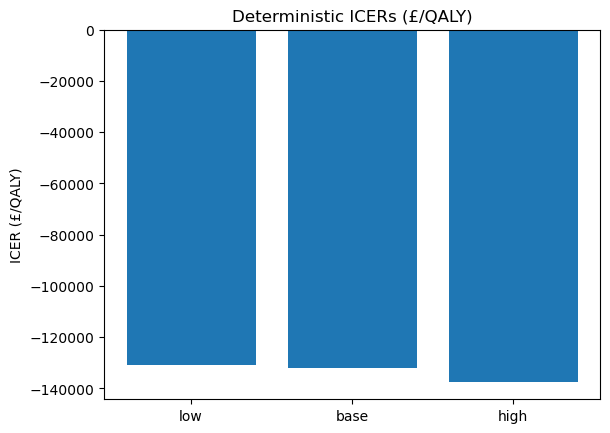


--- Running Module 7: Probabilistic Sensitivity Analysis ---
Dask dashboard link: http://127.0.0.1:44966/status
Running 300 PSA simulations in parallel using Dask...


In [7]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp  # Changed from numpy for JAX compatibility
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import jit, random  # For JAX random operations and transformations

warnings.filterwarnings("ignore")

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            sampled_params[param_name] = random.lognormal(subkey, mean_log, sigma_log)
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 12, 286)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 12, 398)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 12, 408)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # FIX: Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 12, 491)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[device_get(mask)]  # FIX: Changed .to_numpy() to device_get()

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[
                device_get(births), "familial"
            ].values  # FIX: Changed .to_numpy() to device_get()

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[device_get(mask), "diagnosed"] = device_get(
                    diag_outcomes
                )  # FIX: Changed .to_numpy() to device_get()
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        # Step through the simulation for each arm
        sim_r.step(yr)
        # Compute sums from Dask DataFrame and accumulate (results are NumPy from .compute())
        if len(sim_r.pop.index.compute()) > 0:
            sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_r_c += sums["annual_cost"]
            cum_r_q += sums["annual_qaly"]

        sim_p.step(yr)
        if len(sim_p.pop.index.compute()) > 0:
            sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_p_c += sums["annual_cost"]
            cum_p_q += sums["annual_qaly"]

    # Return incremental cost and QALY (results will be NumPy scalars)
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    outputs = []
    final_totals = {}
    dask_params = prepare_dask_params(sampled_params)

    # Use a new JAX key for this specific scenario run
    scenario_key = random.PRNGKey(84)

    for arm in ["retrospective", "prospective"]:
        # Split the scenario_key for each arm to ensure independent random streams
        scenario_key, sim_key = random.split(scenario_key)
        sim = PopulationSystemDask(pop_size, dask_params, arm, seed_key=sim_key)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr)

            # Compute results for the current year
            df_computed = sim.pop.compute()

            if df_computed.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = df_computed[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums[
                        "morbidity"
                    ],  # FIX: Changed 'cost_morbidity' to 'morbidity' which caused KeyError, changing it back to 'cost_morbidity'
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask cluster for parallel processing
cluster = LocalCluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop  # FIX: Changed `param_name` to `familial_prop`
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA ICER Distribution

print("\n--- Running Module 20: PSA ICER Distribution ---")
# Use the pandas dataframe for this calculation, then convert to JAX arrays
dc_jax = jnp.array(psa_df_pd["dCost"].values)
dq_jax = jnp.array(psa_df_pd["dQALY"].values)

# Calculate ICERs
psa_icers_jax_raw = jnp.array(dc_jax / dq_jax)

# Replace inf/-inf with nan before dropping for consistency (using JAX operations)
psa_icers_jax_np = jnp.where(jnp.isinf(psa_icers_jax_raw), jnp.nan, psa_icers_jax_raw)
psa_icers_jax_np = psa_icers_jax_np[~jnp.isnan(psa_icers_jax_np)]  # Filter out NaNs

finite_icers = jnp.array(psa_icers_jax_np)  # Ensure it's a JAX array

if len(finite_icers) > 0:
    # Convert to NumPy for percentile calculation and histplot
    lower_bound, upper_bound = jnp.percentile(finite_icers, jnp.array([1, 99]))
    finite_icers_capped = finite_icers[
        (finite_icers >= lower_bound) & (finite_icers <= upper_bound)
    ]
    finite_icers_capped_np = jnp.array(
        finite_icers_capped
    )  # Convert back to numpy for seaborn
else:
    finite_icers_capped_np = jnp.array([])

plt.figure(figsize=(8, 6))
if len(finite_icers_capped_np) > 0:
    sns.histplot(
        finite_icers_capped_np, bins=50, kde=True, color="purple", edgecolor="black"
    )
    plt.title("PSA Distribution of ICERs (Capped at 1st and 99th Percentiles)")
    plt.xlabel("ICER (£/QALY)")
    plt.ylabel("Frequency")
    plt.grid(True)
plt.show()

# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

## v7a7

In [ ]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp  # Changed from numpy for JAX compatibility
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import jit, random  # For JAX random operations and transformations

warnings.filterwarnings("ignore")

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            # Corrected: Generate a normal variable with specified mean_log and sigma_log, then exponentiate
            sampled_params[param_name] = jnp.exp(
                random.normal(subkey, shape=()) * sigma_log + mean_log
            )
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 14, 289)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 14, 401)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 14, 411)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # FIX: Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 14, 494)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[device_get(mask)]  # FIX: Changed .to_numpy() to device_get()

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[
                device_get(births), "familial"
            ].values  # FIX: Changed .to_numpy() to device_get()

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[device_get(mask), "diagnosed"] = device_get(
                    diag_outcomes
                )  # FIX: Changed .to_numpy() to device_get()
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        # Step through the simulation for each arm
        sim_r.step(yr)
        # Compute sums from Dask DataFrame and accumulate (results are NumPy from .compute())
        if len(sim_r.pop.index.compute()) > 0:
            sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_r_c += sums["annual_cost"]
            cum_r_q += sums["annual_qaly"]

        sim_p.step(yr)
        if len(sim_p.pop.index.compute()) > 0:
            sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_p_c += sums["annual_cost"]
            cum_p_q += sums["annual_qaly"]

    # Return incremental cost and QALY (results will be NumPy scalars)
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    outputs = []
    final_totals = {}
    dask_params = prepare_dask_params(sampled_params)

    # Use a new JAX key for this specific scenario run
    scenario_key = random.PRNGKey(84)

    for arm in ["retrospective", "prospective"]:
        # Split the scenario_key for each arm to ensure independent random streams
        scenario_key, sim_key = random.split(scenario_key)
        sim = PopulationSystemDask(pop_size, dask_params, arm, seed_key=sim_key)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr)

            # Compute results for the current year
            df_computed = sim.pop.compute()

            if df_computed.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = df_computed[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums[
                        "morbidity"
                    ],  # FIX: Changed 'cost_morbidity' to 'morbidity' which caused KeyError, changing it back to 'cost_morbidity'
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask cluster for parallel processing
cluster = LocalCluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop  # FIX: Changed `param_name` to `familial_prop`
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA Histograms

print("\n--- Running Module 20: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

--- Running Module 6: Deterministic Scenarios ---


## v7a8

In [ ]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp  # Changed from numpy for JAX compatibility
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import jit, random  # For JAX random operations and transformations

warnings.filterwarnings("ignore")

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)  # FIX: Corrected typo from PRPRNGKey to PRNGKey.

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            # Corrected: Generate a normal variable with specified mean_log and sigma_log, then exponentiate
            # Use shape=() for explicit scalar output from random.normal to avoid type inference issues
            sampled_params[param_name] = jnp.exp(
                random.normal(subkey, shape=()) * sigma_log + mean_log
            )
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 17, 290)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 17, 402)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 17, 412)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # FIX: Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 17, 495)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[device_get(mask)]  # FIX: Changed .to_numpy() to device_get()

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[
                device_get(births), "familial"
            ].values  # FIX: Changed .to_numpy() to device_get()

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[device_get(mask), "diagnosed"] = device_get(
                    diag_outcomes
                )  # FIX: Changed .to_numpy() to device_get()
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    cum_r_c = cum_r_q = cum_p_c = cum_p_q = 0.0

    for yr in YEARS:
        # Step through the simulation for each arm
        sim_r.step(yr)
        # Compute sums from Dask DataFrame and accumulate (results are NumPy from .compute())
        if len(sim_r.pop.index.compute()) > 0:
            sums = sim_r.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_r_c += sums["annual_cost"]
            cum_r_q += sums["annual_qaly"]

        sim_p.step(yr)
        if len(sim_p.pop.index.compute()) > 0:
            sums = sim_p.pop[["annual_cost", "annual_qaly"]].sum().compute()
            cum_p_c += sums["annual_cost"]
            cum_p_q += sums["annual_qaly"]

    # Return incremental cost and QALY (results will be NumPy scalars)
    return (cum_p_c - cum_r_c, cum_p_q - cum_r_q)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    outputs = []
    final_totals = {}
    dask_params = prepare_dask_params(sampled_params)

    # Use a new JAX key for this specific scenario run
    scenario_key = random.PRNGKey(84)

    for arm in ["retrospective", "prospective"]:
        # Split the scenario_key for each arm to ensure independent random streams
        scenario_key, sim_key = random.split(scenario_key)
        sim = PopulationSystemDask(pop_size, dask_params, arm, seed_key=sim_key)
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            sim.step(yr)

            # Compute results for the current year
            df_computed = sim.pop.compute()

            if df_computed.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = df_computed[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums[
                        "cost_morbidity"
                    ],  # FIX: Corrected column name from 'morbidity' to 'cost_morbidity'
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (df_computed["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )

        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# Initialize Dask cluster for parallel processing
cluster = LocalCluster()
client = Client(cluster)

print(f"Dask dashboard link: {client.dashboard_link}")
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster
client.close()
cluster.close()
print("Dask cluster closed.")


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop  # FIX: Changed `param_name` to `familial_prop`
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA Histograms

print("\n--- Running Module 20: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

--- Running Module 6: Deterministic Scenarios ---


## v7a9

In [ ]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import config, jit, random  # Import config for JAX settings

warnings.filterwarnings("ignore")

# Enable JAX to use 64-bit floating point precision globally
config.update("jax_enable_x64", True)

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# Initialize Dask cluster and client globally so they are available for all simulations
cluster = LocalCluster()
client = Client(cluster)
print(
    f"Dask dashboard link: {client.dashboard_link}"
)  # Print link early for visibility

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            # Corrected: Generate a normal variable with specified mean_log and sigma_log, then exponentiate
            # Use shape=() for explicit scalar output from random.normal to avoid type inference issues
            sampled_params[param_name] = jnp.exp(
                random.normal(subkey, shape=()) * sigma_log + mean_log
            )
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 19, 300)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 19, 412)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 19, 422)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 19, 505)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[device_get(mask)]

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[device_get(births), "familial"].values

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[device_get(mask), "diagnosed"] = device_get(diag_outcomes)
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    # These lists will now store computed numerical values, not Dask objects
    all_r_annual_costs = []
    all_r_annual_qalys = []
    all_p_annual_costs = []
    all_p_annual_qalys = []

    for yr in YEARS:
        sim_r.step(yr)
        # Compute the sum immediately and append the numerical value
        all_r_annual_costs.append(sim_r.pop["annual_cost"].sum().compute())
        all_r_annual_qalys.append(sim_r.pop["annual_qaly"].sum().compute())

        sim_p.step(yr)
        # Compute the sum immediately and append the numerical value
        all_p_annual_costs.append(sim_p.pop["annual_cost"].sum().compute())
        all_p_annual_qalys.append(sim_p.pop["annual_qaly"].sum().compute())

    # Sum the lists of Python numbers directly
    cum_r_c = sum(all_r_annual_costs)
    cum_r_q = sum(all_r_annual_qalys)
    cum_p_c = sum(all_p_annual_costs)
    cum_p_q = sum(all_p_annual_qalys)

    # These are now regular Python floats, no .item() needed
    dc = cum_p_c - cum_r_c
    dq = cum_p_q - cum_r_q

    # Return incremental cost and QALY (results will be Python scalars)
    return (dc, dq)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    dask_params = prepare_dask_params(sampled_params)
    scenario_key = random.PRNGKey(84)

    # Initialize PopulationSystemDask for both arms
    scenario_key, sim_r_key, sim_p_key = random.split(scenario_key, 3)
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    all_annual_dfs_dask = []  # List to collect Dask DataFrames for each year and arm

    for yr in YEARS:
        # Step through the simulation for each arm
        sim_r.step(yr)
        # Capture the current state of sim_r.pop as a Dask DataFrame for this year
        # Add 'year' and 'arm' columns as Dask Series for later grouping/filtering
        df_r_yr = sim_r.pop.assign(year=yr, arm="retrospective")
        all_annual_dfs_dask.append(df_r_yr)

        sim_p.step(yr)
        # Capture the current state of sim_p.pop
        df_p_yr = sim_p.pop.assign(year=yr, arm="prospective")
        all_annual_dfs_dask.append(df_p_yr)

    # Concatenate all annual Dask DataFrames from both arms into a single Dask DataFrame
    # Persist the result to avoid recomputing it if used multiple times in subsequent steps
    full_results_dask = dd.concat(
        all_annual_dfs_dask, interleave_partitions=True
    ).persist()

    # Compute the entire Dask DataFrame to a single Pandas DataFrame
    full_results_df_pd = full_results_dask.compute()

    outputs = []
    final_totals = {
        "retrospective": {"cost": 0.0, "qaly": 0.0},
        "prospective": {"cost": 0.0, "qaly": 0.0},
    }

    for arm in ["retrospective", "prospective"]:
        arm_df = full_results_df_pd[full_results_df_pd["arm"] == arm]
        cum_c = 0.0
        cum_q = 0.0
        for yr in YEARS:
            yearly_df = arm_df[arm_df["year"] == yr]

            if yearly_df.empty:
                row_data = {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": 0.0,
                    "cost_health": 0.0,
                    "cost_edu": 0.0,
                    "cost_respite": 0.0,
                    "cost_mobility": 0.0,
                    "cost_welfare": 0.0,
                    "cost_emp": 0.0,
                    "cost_morbidity": 0.0,
                    "costs": cum_c,
                    "qalys": cum_q,  # Note: These are cumulative up to the previous year
                    **{f"ses_q{i}_pct": 0.0 for i in range(5)},
                }
                outputs.append(row_data)
                continue

            annual_sums = yearly_df[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()

            cum_c += annual_sums["annual_cost"]
            cum_q += annual_sums["annual_qaly"]

            outputs.append(
                {
                    "arm": arm,
                    "year": yr,
                    "annual_cost": annual_sums["annual_cost"],
                    "cost_health": annual_sums["cost_health"],
                    "cost_edu": annual_sums["cost_edu"],
                    "cost_respite": annual_sums["cost_respite"],
                    "cost_mobility": annual_sums["cost_mobility"],
                    "cost_welfare": annual_sums["cost_welfare"],
                    "cost_emp": annual_sums["cost_emp"],
                    "cost_morbidity": annual_sums["morbidity"],
                    "costs": cum_c,
                    "qalys": cum_q,
                    **{
                        f"ses_q{i}_pct": (yearly_df["ses"] == i).mean() * 100
                        for i in range(5)
                    },
                }
            )
        final_totals[arm] = {"cost": cum_c, "qaly": cum_q}

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), pd.DataFrame(outputs)


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# The Dask cluster and client are now initialized globally at the top of the script.
# No need to re-initialize here.
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster (moved to end of script)


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(dfp.loc[dfp["year"] == yr, "costs"].values[0])
        c0 = float(dfr.loc[dfr["year"] == yr, "costs"].values[0])
        q1 = float(dfp.loc[dfp["year"] == yr, "qalys"].values[0])
        q0 = float(dfr.loc[dfr["year"] == yr, "qalys"].values[0])
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, _), mix_data = run_scenario(mean_params_for_subgroup, pop_size=20000)
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA Histograms

print("\n--- Running Module 20: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

# Close the Dask client and cluster at the very end of the script
client.close()
cluster.close()

## v7a10

In [ ]:
import warnings

import dask.dataframe as dd
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import config, jit, random  # Import config for JAX settings

warnings.filterwarnings("ignore")

# Enable JAX to use 64-bit floating point precision globally
config.update("jax_enable_x64", True)

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# Initialize Dask cluster and client globally so they are available for all simulations
cluster = LocalCluster()
client = Client(cluster)
print(
    f"Dask dashboard link: {client.dashboard_link}"
)  # Print link early for visibility

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            # Corrected: Generate a normal variable with specified mean_log and sigma_log, then exponentiate
            # Use shape=() for explicit scalar output from random.normal to avoid type inference issues
            sampled_params[param_name] = jnp.exp(
                random.normal(subkey, shape=()) * sigma_log + mean_log
            )
        elif dist_info["dist"] == "normal":
            # JAX's random.normal generates N(0, 1), so scale by std_dev and add mean
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 21, 300)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 21, 412)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 21, 422)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 21, 505)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Generate initial population, passing the JAX key
        self.pop = gen_population_dask(
            pop_size, self.params, arm, seed_key=self.key
        ).persist()

    def _mortality(self):
        params = self.params
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(ABS_MORT) - 1)
            surv_prob = ABS_MORT[age_indices] * params["MORT_HR"][sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < LIFE_EXP_NP[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[device_get(mask)]

        self.pop = self.pop.map_partitions(
            mortality_partition, meta=self.pop._meta
        ).persist()

    def _fertility(self):
        # Compute potential mothers as a Pandas DataFrame on the worker
        moms = self.pop[
            (self.pop["sex"] == 0) & (self.pop["age"].between(15, 45))
        ].compute()
        if moms.empty:
            return

        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Merge in Pandas (outside JAX context)
        mr = moms.merge(
            self.params["FERT_RATES_DF"], on=["severity", "age"], how="left"
        ).fillna(0)
        rates = mr["rate"].values

        # Generate births using JAX random
        birth_rand_key, _ = random.split(subkey_fert)
        births = random.uniform(birth_rand_key, shape=(len(rates),)) < rates
        n_births = (
            births.sum()
        )  # JAX sum for potential GPU acceleration if rates are JAX arrays

        if n_births > 0:
            babies_params = {
                "familial_prop": self.params["familial_prop"],
                "SEVERITY_DIST": self.params["SEVERITY_DIST"],
                "yield_wgs": self.params["yield_wgs"],
            }
            # Generate babies as a dask dataframe, passing a new JAX key
            baby_gen_key, _ = random.split(subkey_fert)
            babies_dd = gen_population_dask(
                int(n_births), babies_params, self.arm, seed_key=baby_gen_key
            )
            # Compute to pandas for modification
            babies_df = babies_dd.compute()
            babies_df["age"] = 0
            # Ensure 'familial' from mothers is passed as a NumPy array for Pandas assignment
            babies_df["familial"] = mr.loc[device_get(births), "familial"].values

            # Concatenate with the original population Dask DataFrame
            self.pop = dd.concat(
                [self.pop, dd.from_pandas(babies_df, npartitions=self.pop.npartitions)],
                interleave_partitions=True,
            ).persist()

    def _diagnosis(self):
        if self.arm != "prospective":
            return

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(df):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (
                (~diagnosed_jnp)
                & familial_jnp
                & (age_jnp >= self.params["min_test_age"])
            )
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, self.params["yield_wgs"], shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[device_get(mask), "diagnosed"] = device_get(diag_outcomes)
            return df

        self.pop = self.pop.map_partitions(
            diagnosis_partition, meta=self.pop._meta
        ).persist()

    def _cost_qaly(self, year):
        if self.pop.npartitions == 0:
            return

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(df):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params["COST_INP_NP"][sev]
                + params["COST_OUTP_NP"][sev]
                + params["COST_PHARM_NP"][sev]
            ) * disc
            rc = uses_respite_val.astype(jnp.float64) * params["RESPITE"] * disc
            mc = -needs_mobility_val.astype(jnp.float64) * params["MOBILITY"] * disc
            wc = params["WELFARE_NP"][sev] * disc
            emp = params["EMP_NP"][employment_idx] * disc

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params["EDU"][1, support_val], ec)
            ec *= disc

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = (
                    base_rand < params["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += m.astype(jnp.float64) * params["MORB_COST_NP"][i] * disc

            if self.arm == "prospective":
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64) * params["WGS_DIAG_COST_ADJUSTMENT"] * disc
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(params["MORB_KEYS"]):
                m = base_rand_qaly < params["MORB_PROB"][k]
                morb_qaly += m.astype(jnp.float64) * params["MORB_QALY_NP"][i] * disc

            # Utility (QALY) Calculation
            uq = params["U_BASE_NP"][sev] * jnp.exp(
                -params["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params["U_DIAG"]
                + params["U_CARER"]
            ) * disc - morb_qaly

            if self.arm == "prospective":
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64) * params["WGS_DIAG_QALY_ADJUSTMENT"] * disc
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        self.pop = self.pop.map_partitions(
            cost_qaly_partition, meta=self.pop._meta
        ).persist()

    def step(self, year):
        # Each step function updates the population's state
        self._mortality()
        self._fertility()
        self._diagnosis()
        # Increment age for all individuals and persist
        self.pop = self.pop.assign(age=self.pop.age + 1).persist()
        # Calculate costs and QALYs for the current year
        self._cost_qaly(year)


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    # These lists will now store computed numerical values, not Dask objects
    all_r_annual_costs = []
    all_r_annual_qalys = []
    all_p_annual_costs = []
    all_p_annual_qalys = []

    for yr in YEARS:
        sim_r.step(yr)
        # Compute the sum immediately and append the numerical value
        all_r_annual_costs.append(sim_r.pop["annual_cost"].sum().compute())
        all_r_annual_qalys.append(sim_r.pop["annual_qaly"].sum().compute())

        sim_p.step(yr)
        # Compute the sum immediately and append the numerical value
        all_p_annual_costs.append(sim_p.pop["annual_cost"].sum().compute())
        all_p_annual_qalys.append(sim_p.pop["annual_qaly"].sum().compute())

    # Sum the lists of Python numbers directly
    cum_r_c = sum(all_r_annual_costs)
    cum_r_q = sum(all_r_annual_qalys)
    cum_p_c = sum(all_p_annual_costs)
    cum_p_q = sum(all_p_annual_qalys)

    # These are now regular Python floats, no .item() needed
    dc = cum_p_c - cum_r_c
    dq = cum_p_q - cum_r_q

    # Return incremental cost and QALY (results will be Python scalars)
    return (dc, dq)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    dask_params = prepare_dask_params(sampled_params)
    scenario_key = random.PRNGKey(84)

    scenario_key, sim_r_key, sim_p_key = random.split(scenario_key, 3)
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    annual_aggregated_results = []

    for yr in YEARS:
        sim_r.step(yr)
        sim_p.step(yr)

        # Aggregate data within Dask for the current year, then compute to Pandas
        # Retrospective arm
        r_pop_current = sim_r.pop.assign(year=yr, arm="retrospective")
        # Check if r_pop_current is empty before attempting sum/count
        if (
            r_pop_current.npartitions == 0
            or r_pop_current.known_partitions
            and r_pop_current.npartitions == 0
        ):
            r_annual_sums = {
                col: 0.0
                for col in [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            }
            r_ses_pct = {i: 0.0 for i in range(5)}
            r_total_pop = 0
        else:
            r_annual_sums = (
                r_pop_current[
                    [
                        "annual_cost",
                        "annual_qaly",
                        "cost_health",
                        "cost_edu",
                        "cost_respite",
                        "cost_mobility",
                        "cost_welfare",
                        "cost_emp",
                        "cost_morbidity",
                    ]
                ]
                .sum()
                .compute()
            )
            r_ses_counts = (
                r_pop_current.groupby("ses").age.count().compute()
            )  # Count per SES quintile
            r_total_pop = r_pop_current.age.count().compute()
            r_ses_pct = {
                i: (r_ses_counts.get(i, 0) / r_total_pop * 100)
                if r_total_pop > 0
                else 0
                for i in range(5)
            }

        # Prospective arm
        p_pop_current = sim_p.pop.assign(year=yr, arm="prospective")
        # Check if p_pop_current is empty before attempting sum/count
        if (
            p_pop_current.npartitions == 0
            or p_pop_current.known_partitions
            and p_pop_current.npartitions == 0
        ):
            p_annual_sums = {
                col: 0.0
                for col in [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            }
            p_ses_pct = {i: 0.0 for i in range(5)}
            p_total_pop = 0
        else:
            p_annual_sums = (
                p_pop_current[
                    [
                        "annual_cost",
                        "annual_qaly",
                        "cost_health",
                        "cost_edu",
                        "cost_respite",
                        "cost_mobility",
                        "cost_welfare",
                        "cost_emp",
                        "cost_morbidity",
                    ]
                ]
                .sum()
                .compute()
            )
            p_ses_counts = p_pop_current.groupby("ses").age.count().compute()
            p_total_pop = p_pop_current.age.count().compute()
            p_ses_pct = {
                i: (p_ses_counts.get(i, 0) / p_total_pop * 100)
                if p_total_pop > 0
                else 0
                for i in range(5)
            }

        # Build results for this year
        # Retrospective
        annual_aggregated_results.append(
            {
                "arm": "retrospective",
                "year": yr,
                "annual_cost": r_annual_sums["annual_cost"],
                "annual_qaly": r_annual_sums["annual_qaly"],
                "cost_health": r_annual_sums["cost_health"],
                "cost_edu": r_annual_sums["cost_edu"],
                "cost_respite": r_annual_sums["cost_respite"],
                "cost_mobility": r_annual_sums["cost_mobility"],
                "cost_welfare": r_annual_sums["cost_welfare"],
                "cost_emp": r_annual_sums["cost_emp"],
                "cost_morbidity": r_annual_sums[
                    "cost_morbidity"
                ],  # Corrected to reference cost_morbidity
                **{f"ses_q{i}_pct": r_ses_pct[i] for i in range(5)},
            }
        )
        # Prospective
        annual_aggregated_results.append(
            {
                "arm": "prospective",
                "year": yr,
                "annual_cost": p_annual_sums["annual_cost"],
                "annual_qaly": p_annual_sums["annual_qaly"],
                "cost_health": p_annual_sums["cost_health"],
                "cost_edu": p_annual_sums["cost_edu"],
                "cost_respite": p_annual_sums["cost_respite"],
                "cost_mobility": p_annual_sums["cost_mobility"],
                "cost_welfare": p_annual_sums["cost_welfare"],
                "cost_emp": p_annual_sums["cost_emp"],
                "cost_morbidity": p_annual_sums[
                    "cost_morbidity"
                ],  # Corrected to reference cost_morbidity
                **{f"ses_q{i}_pct": p_ses_pct[i] for i in range(5)},
            }
        )

    # Convert the list of dictionaries to a Pandas DataFrame
    full_results_df_pd = pd.DataFrame(annual_aggregated_results)

    # Calculate cumulative costs and QALYs after all annual data is collected
    final_totals = {
        "retrospective": {"cost": 0.0, "qaly": 0.0},
        "prospective": {"cost": 0.0, "qaly": 0.0},
    }
    for arm in ["retrospective", "prospective"]:
        arm_df = full_results_df_pd[full_results_df_pd["arm"] == arm]
        final_totals[arm]["cost"] = arm_df["annual_cost"].sum()
        final_totals[arm]["qaly"] = arm_df["annual_qaly"].sum()

    d_cost = final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    d_qaly = final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]

    return (d_cost, d_qaly), full_results_df_pd


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    dc, dq = run_sim(current_params_for_run, pop_size=20000)
    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# The Dask cluster and client are now initialized globally at the top of the script.
# No need to re-initialize here.
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append((sampled_params, 8000, i))

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster (moved to end of script)


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)
plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

base_dc, base_dq = run_sim(base_params, pop_size=10000)
base_icer = base_dc / base_dq if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        dc, dq = run_sim(p_temp, pop_size=10000)
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = tor_df["ICER_diff"].abs()
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    dc, dq = run_sim(p_temp, pop_size=15000)
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, _), int_full = run_scenario(mean_params_for_subgroup, pop_size=15000)
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    # Ensure the year exists in both prospective and retrospective dataframes before accessing
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(
            dfp.loc[dfp["year"] == yr, "annual_cost"].values[0]
        )  # Use annual_cost from aggregated data
        c0 = float(
            dfr.loc[dfr["year"] == yr, "annual_cost"].values[0]
        )  # Use annual_cost from aggregated data
        q1 = float(
            dfp.loc[dfp["year"] == yr, "annual_qaly"].values[0]
        )  # Use annual_qaly from aggregated data
        q0 = float(
            dfr.loc[dfr["year"] == yr, "annual_qaly"].values[0]
        )  # Use annual_qaly from aggregated data
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
base_icer_subgroup = base_dc_subgroup / base_dq_subgroup if base_dq_subgroup != 0 else 0

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, mix_data) = run_scenario(
    mean_params_for_subgroup, pop_size=20000
)  # Re-run run_scenario to get the updated mix_data structure
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA Histograms

print("\n--- Running Module 20: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

# Close the Dask client and cluster at the very end of the script
client.close()
cluster.close()

Dask dashboard link: http://127.0.0.1:45552/status
--- Running Module 6: Deterministic Scenarios ---


## v7a11

In [ ]:
import gc  # Import garbage collection module
import warnings

import dask.dataframe as dd
import jax.numpy as jnp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from dask.distributed import Client, LocalCluster, progress
from jax import config, jit, random  # Import config for JAX settings

warnings.filterwarnings("ignore")

# Enable JAX to use 64-bit floating point precision globally
config.update("jax_enable_x64", True)

# Global JAX random key for reproducible random operations
# This key will be split and passed around to maintain JAX's functional randomness.
key = random.PRNGKey(42)

# Initialize Dask cluster and client globally so they are available for all simulations
cluster = LocalCluster()
client = Client(cluster)
print(
    f"Dask dashboard link: {client.dashboard_link}"
)  # Print link early for visibility

# %% [markdown]
## 2. Global Parameters & Dask Constants and Parameter Distributions

START_YEAR, END_YEAR = 2020, 2100
YEARS = list(range(START_YEAR, END_YEAR + 1))
DISCOUNT = 0.035  # Fixed
POP_SIZE = 62000  # Fixed (this is the original POP_SIZE, can be overridden in run_sim/run_scenario)

# Costs are based on 2017 values from the paper, adjust to START_YEAR (2020)
COST_REFERENCE_YEAR = 2017  # Fixed
INFLATION_RATE = 0.03  # Fixed
INFLATION_FACTOR = (1 + INFLATION_RATE) ** (START_YEAR - COST_REFERENCE_YEAR)  # Fixed

# Demographics - mostly fixed or handled by sampling
# SEVERITY_DIST is now defined by a beta distribution for the proportion of mild
AGE_BREAKS = jnp.arange(0, 95, 5)  # Changed from np.arange to jnp.arange
AGE_DIST = jnp.array(
    [  # Changed from np.array to jnp.array
        0.064,
        0.067,
        0.069,
        0.069,
        0.071,
        0.076,
        0.080,
        0.077,
        0.080,
        0.079,
        0.073,
        0.078,
        0.077,
        0.072,
        0.055,
        0.041,
        0.031,
        0.022,
        0.012,
    ]
)
AGE_DIST /= AGE_DIST.sum()

# Mortality
LIFE_EXP_NP = jnp.array([74, 54])  # Changed from np.array to jnp.array
ABS_MORT = jnp.array(
    [  # Changed from np.array to jnp.array
        0.0002,
        0.0001,
        0.0001,
        0.0002,
        0.0003,
        0.0005,
        0.0007,
        0.0011,
        0.0019,
        0.0035,
        0.0055,
        0.0085,
        0.0130,
        0.0200,
        0.0350,
        0.0600,
        0.0950,
        0.1500,
        0.2500,
    ]
)

# Fertility bands - rates will be scaled by a sampled multiplier
FERT_AGE_SPEC = {  # Base fertility rates (fixed means, scaled in PSA)
    (0, (15, 19)): 0.003,
    (0, (20, 24)): 0.008,
    (0, (25, 29)): 0.010,
    (0, (30, 34)): 0.007,
    (0, (35, 45)): 0.002,
    (1, (15, 19)): 0.001,
    (1, (20, 24)): 0.003,
    (1, (25, 29)): 0.004,
    (1, (30, 34)): 0.003,
    (1, (35, 45)): 0.001,
}

# Employment costs (assumed fixed structural values)
EMP_NP = (
    jnp.array([0, 10000, 0]) * INFLATION_FACTOR
)  # Changed from np.array to jnp.array

# Morbidity Keys (Globally defined and fixed list of categories)
MORB_KEYS = [
    "epilepsy",
    "asd",
    "mental",
]  # Based on previous code, not the paper's full list of costs


# Helper function to get Gamma parameters from mean and standard deviation
def get_gamma_params(mean, std_dev):
    if mean <= 0 or std_dev <= 0:
        return {"dist": "fixed", "value": mean}  # Handle fixed or zero values
    variance = std_dev**2
    shape = mean**2 / variance
    scale = variance / mean
    return {"dist": "gamma", "shape": shape, "scale": scale}


# Helper function to get Beta parameters from mean and standard deviation
def get_beta_params(mean, std_dev):
    if not (0 <= mean <= 1) or std_dev <= 0:
        return {"dist": "fixed", "value": mean}
    variance = std_dev**2
    # Ensure variance is not too large for beta distribution
    if variance >= mean * (1 - mean) and mean > 0 and mean < 1:
        variance = mean * (1 - mean) * 0.99
        std_dev = jnp.sqrt(
            variance
        )  # Changed math.sqrt to jnp.sqrt for JAX compatibility

    alpha = mean * (mean * (1 - mean) / variance - 1)
    beta_param = (1 - mean) * (mean * (1 - mean) / variance - 1)

    if alpha <= 0 or beta_param <= 0:
        return {
            "dist": "uniform",
            "low": max(0, mean - 0.01),
            "high": min(1, mean + 0.01),
        }
    return {"dist": "beta", "alpha": alpha, "beta": beta_param}


# Define all uncertain parameters with their distributions
DISTRIBUTIONS = {
    # Costs (Gamma distributions)
    "cost_inp_mild": get_gamma_params(
        5000 * INFLATION_FACTOR, 5000 * INFLATION_FACTOR * 0.20
    ),
    "cost_inp_severe": get_gamma_params(
        15000 * INFLATION_FACTOR, 15000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_mild": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "cost_outp_severe": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_mild": get_gamma_params(
        200 * INFLATION_FACTOR, 200 * INFLATION_FACTOR * 0.20
    ),
    "cost_pharm_severe": get_gamma_params(
        500 * INFLATION_FACTOR, 500 * INFLATION_FACTOR * 0.20
    ),
    "edu0_sup0": get_gamma_params(
        16107 * INFLATION_FACTOR, 16107 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup1": get_gamma_params(
        27903 * INFLATION_FACTOR, 27903 * INFLATION_FACTOR * 0.15
    ),
    "edu0_sup2": get_gamma_params(
        46733 * INFLATION_FACTOR, 46733 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup0": get_gamma_params(
        18958 * INFLATION_FACTOR, 18958 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup1": get_gamma_params(
        30789 * INFLATION_FACTOR, 30789 * INFLATION_FACTOR * 0.15
    ),
    "edu1_sup2": get_gamma_params(
        49604 * INFLATION_FACTOR, 49604 * INFLATION_FACTOR * 0.15
    ),
    "respite": get_gamma_params(
        13024 * INFLATION_FACTOR, 13024 * INFLATION_FACTOR * 0.20
    ),
    "mobility": get_gamma_params(
        2493 * INFLATION_FACTOR, 2493 * INFLATION_FACTOR * 0.20
    ),
    "welfare_mild": get_gamma_params(
        3000 * INFLATION_FACTOR, 3000 * INFLATION_FACTOR * 0.20
    ),
    "welfare_severe": get_gamma_params(
        8000 * INFLATION_FACTOR, 8000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_epilepsy": get_gamma_params(
        2000 * INFLATION_FACTOR, 2000 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_asd": get_gamma_params(
        1500 * INFLATION_FACTOR, 1500 * INFLATION_FACTOR * 0.20
    ),
    "morb_cost_mental": get_gamma_params(
        1000 * INFLATION_FACTOR, 1000 * INFLATION_FACTOR * 0.20
    ),
    "wgs_diag_cost_adjustment": {
        "dist": "normal",
        "loc": -1000 * INFLATION_FACTOR,
        "scale": 100 * INFLATION_FACTOR,
    },
    # Utilities (Beta distributions)
    "u_base_mild": get_beta_params(0.78, 0.02),
    "u_base_severe": get_beta_params(0.65, 0.03),
    "u_decay": get_beta_params(0.0005, 0.00005),
    "u_diag": get_beta_params(0.02, 0.002),
    "u_carer": get_beta_params(0.05, 0.005),
    "morb_qaly_epilepsy": get_beta_params(0.04, 0.005),
    "morb_qaly_asd": get_beta_params(0.03, 0.005),
    "morb_qaly_mental": get_beta_params(0.05, 0.005),
    "wgs_diag_qaly_adjustment": get_beta_params(0.01, 0.001),
    # Probabilities / Rates
    # 's' is the standard deviation of the underlying normal distribution.
    # 'scale' is exp(mean) of the underlying normal distribution.
    "mort_hr_mild": {"dist": "lognormal", "s": 0.1, "scale": 2.0},
    "mort_hr_severe": {"dist": "lognormal", "s": 0.1, "scale": 4.0},
    "morb_prob_epilepsy": get_beta_params(0.25, 0.03),
    "morb_prob_asd": get_beta_params(0.30, 0.03),
    "morb_prob_mental": get_beta_params(0.35, 0.04),
    "familial_prop": {"dist": "beta", "alpha": 30, "beta": 150},
    "yield_wgs": {"dist": "beta", "alpha": 45, "beta": 55},
    "severity_mild_prop": get_beta_params(0.70, 0.03),
    "fertility_multiplier": {"dist": "lognormal", "s": 0.1, "scale": 1.0},
    # Fixed parameters
    "min_test_age": {"dist": "fixed", "value": 0},
}


# Helper function to sample from the defined distributions using JAX random
def sample_params_from_dist(
    dist_dict, seed_key=None
):  # Changed seed to seed_key for JAX compatibility
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    sampled_params = {}
    for param_name, dist_info in dist_dict.items():
        seed_key, subkey = random.split(
            seed_key
        )  # Split key for each sample to maintain randomness
        if dist_info["dist"] == "beta":
            sampled_params[param_name] = random.beta(
                subkey, dist_info["alpha"], dist_info["beta"]
            )
        elif dist_info["dist"] == "gamma":
            # JAX's random.gamma takes 'a' (shape) and then multiplies by 'scale'
            sampled_params[param_name] = (
                random.gamma(subkey, dist_info["shape"]) * dist_info["scale"]
            )
        elif dist_info["dist"] == "lognormal":
            # Convert scipy's (s, scale) to JAX's (mean_log, sigma_log)
            # scipy.stats.lognorm(s=s, scale=scale) means log(X) ~ N(log(scale), s^2)
            mean_log = jnp.log(dist_info["scale"])
            sigma_log = dist_info["s"]
            # Corrected: Generate a normal variable with specified mean_log and sigma_log, then exponentiate
            # Use shape=() for explicit scalar output from random.normal to avoid type inference issues
            sampled_params[param_name] = jnp.exp(
                random.normal(subkey, shape=()) * sigma_log + mean_log
            )
        elif dist_info["dist"] == "normal":
            sampled_params[param_name] = (
                random.normal(subkey) * dist_info["scale"] + dist_info["loc"]
            )
        elif dist_info["dist"] == "uniform":
            sampled_params[param_name] = random.uniform(
                subkey, minval=dist_info["low"], maxval=dist_info["high"]
            )
        elif dist_info["dist"] == "fixed":
            sampled_params[param_name] = dist_info["value"]
        else:
            raise ValueError(f"Unknown distribution type: {dist_info['dist']}")
    if "severity_mild_prop" in sampled_params:
        sampled_params["severity_severe_prop"] = (
            1.0 - sampled_params["severity_mild_prop"]
        )
    return sampled_params


# Function to prepare parameters as JAX arrays for Dask partitions
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("prepare_dask_params", 24, 300)] = prepare_dask_params


def prepare_dask_params(sampled_params):
    # Costs (converted to JAX arrays)
    COST_INP_NP_sampled = jnp.array(
        [sampled_params["cost_inp_mild"], sampled_params["cost_inp_severe"]]
    )
    COST_OUTP_NP_sampled = jnp.array(
        [sampled_params["cost_outp_mild"], sampled_params["cost_outp_severe"]]
    )
    COST_PHARM_NP_sampled = jnp.array(
        [sampled_params["cost_pharm_mild"], sampled_params["cost_pharm_severe"]]
    )
    EDU_SAMPLED = jnp.array(
        [
            [
                sampled_params["edu0_sup0"],
                sampled_params["edu0_sup1"],
                sampled_params["edu0_sup2"],
            ],
            [
                sampled_params["edu1_sup0"],
                sampled_params["edu1_sup1"],
                sampled_params["edu1_sup2"],
            ],
        ]
    )
    WELFARE_NP_sampled = jnp.array(
        [sampled_params["welfare_mild"], sampled_params["welfare_severe"]]
    )
    MORB_COST_NP_sampled = jnp.array(
        [
            sampled_params["morb_cost_epilepsy"],
            sampled_params["morb_cost_asd"],
            sampled_params["morb_cost_mental"],
        ]
    )

    # Utilities (converted to JAX arrays)
    U_BASE_NP_sampled = jnp.array(
        [sampled_params["u_base_mild"], sampled_params["u_base_severe"]]
    )
    MORB_QALY_NP_sampled = jnp.array(
        [
            sampled_params["morb_qaly_epilepsy"],
            sampled_params["morb_qaly_asd"],
            sampled_params["morb_qaly_mental"],
        ]
    )

    # Mortality HRs (converted to JAX arrays)
    MORT_HR_sampled = jnp.array(
        [sampled_params["mort_hr_mild"], sampled_params["mort_hr_severe"]]
    )

    # Morbidity Probabilities (converted to JAX-friendly dictionary/array)
    # Store as an array that can be indexed by integer, assuming order matches MORB_KEYS
    MORB_PROB_SAMPLED = {
        "epilepsy": sampled_params["morb_prob_epilepsy"],
        "asd": sampled_params["morb_prob_asd"],
        "mental": sampled_params["morb_prob_mental"],
    }

    # Severity Distribution (converted to JAX array)
    SEVERITY_DIST_SAMPLED = jnp.array(
        [sampled_params["severity_mild_prop"], sampled_params["severity_severe_prop"]]
    )

    # Fertility Rates (DataFrame remains Pandas, multiplier applied)
    FERT_RATES_DF_SAMPLED = FERT_RATES_DF.copy()
    FERT_RATES_DF_SAMPLED["rate"] *= sampled_params["fertility_multiplier"]

    return {
        "COST_INP_NP": COST_INP_NP_sampled,
        "COST_OUTP_NP": COST_OUTP_NP_sampled,
        "COST_PHARM_NP": COST_PHARM_NP_sampled,
        "EDU": EDU_SAMPLED,
        "RESPITE": sampled_params["respite"],
        "MOBILITY": sampled_params["mobility"],
        "WELFARE_NP": WELFARE_NP_sampled,
        "EMP_NP": EMP_NP,  # EMP_NP is already jnp.array global
        "MORB_COST_NP": MORB_COST_NP_sampled,
        "WGS_DIAG_COST_ADJUSTMENT": sampled_params["wgs_diag_cost_adjustment"],
        "U_BASE_NP": U_BASE_NP_sampled,
        "U_DECAY": sampled_params["u_decay"],
        "U_DIAG": sampled_params["u_diag"],
        "U_CARER": sampled_params["u_carer"],
        "MORB_QALY_NP": MORB_QALY_NP_sampled,
        "WGS_DIAG_QALY_ADJUSTMENT": sampled_params["wgs_diag_qaly_adjustment"],
        "MORT_HR": MORT_HR_sampled,
        "MORB_PROB": MORB_PROB_SAMPLED,
        "familial_prop": sampled_params["familial_prop"],
        "yield_wgs": sampled_params["yield_wgs"],
        "min_test_age": sampled_params["min_test_age"],
        "SEVERITY_DIST": SEVERITY_DIST_SAMPLED,
        "FERT_RATES_DF": FERT_RATES_DF_SAMPLED,
        "DISCOUNT": DISCOUNT,
        "INFLATION_FACTOR": INFLATION_FACTOR,
        "MORB_KEYS": MORB_KEYS,
    }


# Build lookup table for fertility rates (base rates)
fert_data = []
for (s, (lo, hi)), r in FERT_AGE_SPEC.items():
    for age in range(lo, hi + 1):
        fert_data.append({"severity": s, "age": age, "rate": r})
FERT_RATES_DF = pd.DataFrame(fert_data)

# %% [markdown]
## 3. Cohort Generator (Dask-compatible)


# Updated to use JAX for random number generation within Dask functions for consistency and potential future JITting
_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("sample_ages", 24, 412)] = sample_ages


def sample_ages(n, age_dist_param, key):  # Added key parameter for JAX random
    key, subkey = random.split(key)
    # random.choice in JAX needs an array for the choices, here it's implicit from len(AGE_BREAKS)
    idx = random.choice(subkey, len(AGE_BREAKS), shape=(n,), p=age_dist_param)
    key, subkey = random.split(key)
    return (
        AGE_BREAKS[idx] + random.randint(subkey, minval=0, maxval=5, shape=(n,))
    ).astype(int)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("gen_population_dask", 24, 422)] = gen_population_dask


def gen_population_dask(
    n, current_params, arm="prospective", seed_key=None
):  # Added seed_key for JAX
    if seed_key is None:
        seed_key = random.PRNGKey(42)  # Default key if not provided

    # Split the main seed_key into multiple subkeys for different random operations
    (
        key_ages,
        key_sex,
        key_sev,
        key_fam,
        key_diag,
        key_liv,
        key_emp,
        key_resp,
        key_mob,
        key_sup,
        key_ses,
    ) = random.split(seed_key, 11)

    ages = sample_ages(n, AGE_DIST, key_ages)
    sev_dist = current_params["SEVERITY_DIST"]
    # Ensure sev_dist is a valid probability distribution (already JAX array from prepare_dask_params)
    sev_dist = jnp.array(sev_dist)  # Explicitly ensure it's a JAX array just in case
    sev_dist /= sev_dist.sum()

    df = pd.DataFrame(
        {
            "age": ages,
            # JAX random.choice takes a key, an array of choices, a shape, and probabilities
            "sex": random.choice(
                key_sex, jnp.array([0, 1]), shape=(n,), p=jnp.array([0.5, 0.5])
            ),
            "severity": random.choice(
                key_sev, jnp.array([0, 1]), shape=(n,), p=sev_dist
            ),
            "familial": random.uniform(key_fam, shape=(n,))
            < current_params["familial_prop"],
            "diagnosed": jnp.zeros(n, dtype=bool)
            if arm == "prospective"
            else (random.uniform(key_diag, shape=(n,)) < current_params["yield_wgs"]),
            "living": random.choice(
                key_liv,
                jnp.array([0, 1, 2, 3]),
                shape=(n,),
                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
            ),  # Assuming 0 for dead, others are living states
            "employment": random.choice(
                key_emp, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.7, 0.2, 0.1])
            ),
            "uses_respite": random.uniform(key_resp, shape=(n,)) < 0.3,
            "needs_mobility": random.uniform(key_mob, shape=(n,)) < 0.2,
            "support": random.choice(
                key_sup, jnp.array([0, 1, 2]), shape=(n,), p=jnp.array([0.5, 0.3, 0.2])
            ),
            "ses": random.choice(key_ses, jnp.arange(5), shape=(n,)),
        }
    )
    # Convert df['age'] (Pandas Series) to JAX array for jnp.where
    df["school"] = jnp.where(
        jnp.array(df["age"]) < 5, -1, jnp.where(jnp.array(df["age"]) < 12, 0, 1)
    )

    for col in [
        "annual_cost",
        "annual_qaly",
        "cost_health",
        "cost_edu",
        "cost_respite",
        "cost_mobility",
        "cost_welfare",
        "cost_emp",
        "cost_morbidity",
    ]:
        df[col] = 0.0
    return dd.from_pandas(df, npartitions=4)


# %% [markdown]
## 4. Population System (Dask)


_prototype_definition_history = globals().get("_prototype_definition_history", {})
_prototype_definition_history[("PopulationSystemDask", 24, 505)] = PopulationSystemDask


class PopulationSystemDask:
    def __init__(
        self, pop_size, current_params, arm="prospective", seed_key=None
    ):  # Added seed_key for JAX
        self.arm = arm
        self.params = current_params
        # Initialize JAX key for this instance. If not provided, create a new one.
        self.key = seed_key if seed_key is not None else random.PRNGKey(42)
        # Initial population. We will persist it at the end of the step.
        self.pop = gen_population_dask(pop_size, self.params, arm, seed_key=self.key)
        # No initial persist here. It happens in the first step.

    def _mortality(self, current_pop):
        # Split the instance's main key for this operation
        _key, subkey_mort = random.split(self.key)
        self.key = subkey_mort  # Update the instance's key for subsequent operations

        def mortality_partition(df, abs_mort, life_exp_np, mort_hr, subkey_mort_part):
            if df.empty:
                return df
            ages = jnp.array(df["age"].values)  # Convert to JAX array
            sev = jnp.array(df["severity"].values)  # Convert to JAX array

            age_indices = jnp.clip((ages // 5).astype(int), 0, len(abs_mort) - 1)
            surv_prob = abs_mort[age_indices] * mort_hr[sev]

            # Generate random numbers within the partition using the subkey passed from the main thread
            # and further splitting it to ensure unique streams for each row or operation if needed.
            partition_key_uniform, _ = random.split(subkey_mort_part)
            # Use random.uniform for survival probability check
            mask = (
                random.uniform(partition_key_uniform, shape=(len(df),)) > surv_prob
            ) & (ages < life_exp_np[sev])

            # Convert JAX boolean array to NumPy boolean array explicitly for Pandas DataFrame filtering
            return df[device_get(mask)]

        return current_pop.map_partitions(
            mortality_partition,
            ABS_MORT,
            LIFE_EXP_NP,
            self.params["MORT_HR"],
            subkey_mort,
            meta=current_pop._meta,
        )

    def _fertility(self, current_pop):
        # Split the instance's main key for this operation
        _key, subkey_fert = random.split(self.key)
        self.key = subkey_fert  # Update the instance's key

        # Pass parameters explicitly to the partition function
        params = self.params
        fert_rates_df = self.params["FERT_RATES_DF"]  # This is a Pandas DataFrame

        def fertility_partition(
            df, params_passed, fert_rates_df_passed, subkey_fert_part, arm_passed
        ):
            if df.empty:
                return df

            # Filter for potential mothers within this partition
            moms_part = df[(df["sex"] == 0) & (df["age"].between(15, 45))]
            if moms_part.empty:
                return df

            # Merge with fertility rates (Pandas operation within partition)
            mr_part = moms_part.merge(
                fert_rates_df_passed, on=["severity", "age"], how="left"
            ).fillna(0)
            rates = mr_part["rate"].values

            # Generate births using JAX random for this partition
            birth_rand_key, _ = random.split(subkey_fert_part)
            # Convert rates to a JAX array for random.uniform comparison
            births_mask_jax = random.uniform(
                birth_rand_key, shape=(len(rates),)
            ) < jnp.array(rates)
            n_births = jnp.sum(births_mask_jax)  # Number of births in this partition

            if n_births > 0:
                # Need to convert n_births to a Python int for shape argument of JAX random functions
                n_births_int = (
                    int(n_births.item())
                    if isinstance(n_births, jnp.ndarray)
                    else int(n_births)
                )

                # Create new babies DataFrame within this partition
                babies_df = pd.DataFrame(
                    {
                        "age": jnp.zeros(n_births_int, dtype=int),
                        "sex": device_get(
                            random.choice(
                                birth_rand_key,
                                jnp.array([0, 1]),
                                shape=(n_births_int,),
                                p=jnp.array([0.5, 0.5]),
                            )
                        ),
                        "severity": device_get(
                            random.choice(
                                birth_rand_key,
                                jnp.array([0, 1]),
                                shape=(n_births_int,),
                                p=params_passed["SEVERITY_DIST"],
                            )
                        ),
                        "familial": device_get(
                            random.uniform(birth_rand_key, shape=(n_births_int,))
                            < params_passed["familial_prop"]
                        ),
                        "diagnosed": device_get(
                            jnp.zeros(n_births_int, dtype=bool)
                            if arm_passed == "prospective"
                            else (
                                random.uniform(birth_rand_key, shape=(n_births_int,))
                                < params_passed["yield_wgs"]
                            )
                        ),
                        "living": device_get(
                            random.choice(
                                birth_rand_key,
                                jnp.array([0, 1, 2, 3]),
                                shape=(n_births_int,),
                                p=jnp.array([0.2, 0.1, 0.3, 0.4]),
                            )
                        ),
                        "employment": device_get(
                            random.choice(
                                birth_rand_key,
                                jnp.array([0, 1, 2]),
                                shape=(n_births_int,),
                                p=jnp.array([0.7, 0.2, 0.1]),
                            )
                        ),
                        "uses_respite": device_get(
                            random.uniform(birth_rand_key, shape=(n_births_int,)) < 0.3
                        ),
                        "needs_mobility": device_get(
                            random.uniform(birth_rand_key, shape=(n_births_int,)) < 0.2
                        ),
                        "support": device_get(
                            random.choice(
                                birth_rand_key,
                                jnp.array([0, 1, 2]),
                                shape=(n_births_int,),
                                p=jnp.array([0.5, 0.3, 0.2]),
                            )
                        ),
                        "ses": device_get(
                            random.choice(
                                birth_rand_key, jnp.arange(5), shape=(n_births_int,)
                            )
                        ),
                    }
                )
                # Ensure 'familial' from mothers is passed for the new babies.
                # Use device_get for the mask to slice the Pandas DataFrame correctly.
                babies_df["familial"] = mr_part.loc[
                    device_get(births_mask_jax), "familial"
                ].values

                # Initialize new columns for babies
                for col in [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]:
                    babies_df[col] = 0.0

                # Concatenate the original partition with the new babies
                return pd.concat([df, babies_df], ignore_index=True)
            else:
                return df

        # Call map_partitions with all necessary arguments
        return current_pop.map_partitions(
            fertility_partition,
            params,
            fert_rates_df,  # Pass the pandas DataFrame directly
            subkey_fert,
            self.arm,
            meta=current_pop._meta,
        )

    def _diagnosis(self, current_pop):
        if self.arm != "prospective":
            return current_pop

        # Split the instance's main key for this operation
        _key, subkey_diag = random.split(self.key)
        self.key = subkey_diag  # Update the instance's key

        # Use map_partitions for updating 'diagnosed' status
        def diagnosis_partition(
            df, min_test_age, yield_wgs, subkey_diag_part, arm_passed
        ):
            if df.empty:
                return df
            # Convert relevant columns to JAX arrays for JAX operations
            diagnosed_jnp = jnp.array(df["diagnosed"].values)
            familial_jnp = jnp.array(df["familial"].values)
            age_jnp = jnp.array(df["age"].values)

            # Create mask for eligible individuals using JAX
            mask = (~diagnosed_jnp) & familial_jnp & (age_jnp >= min_test_age)
            cnt = jnp.sum(mask)  # Sum using JAX for count

            if cnt > 0:
                # Generate random outcomes for diagnosis using JAX
                partition_key_diag_outcomes, _ = random.split(subkey_diag_part)
                # Generate outcomes only for the count of eligible individuals
                diag_outcomes = random.bernoulli(
                    partition_key_diag_outcomes, yield_wgs, shape=(cnt,)
                )

                # Apply updates. Need to convert JAX boolean mask to NumPy for Pandas assignment
                df.loc[device_get(mask), "diagnosed"] = device_get(diag_outcomes)
            return df

        return current_pop.map_partitions(
            diagnosis_partition,
            self.params["min_test_age"],
            self.params["yield_wgs"],
            subkey_diag,
            self.arm,
            meta=current_pop._meta,
        )

    def _cost_qaly(self, current_pop, year):
        if current_pop.npartitions == 0:
            # Return a new Dask DataFrame with the correct metadata if empty
            meta = pd.DataFrame(
                columns=current_pop.columns.tolist()
                + [
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                    "annual_cost",
                    "annual_qaly",
                ],
                dtype=float,
            )
            return dd.from_pandas(
                pd.DataFrame(), npartitions=current_pop.npartitions, meta=meta
            )

        params = self.params
        disc = 1 / ((1 + params["DISCOUNT"]) ** (year - START_YEAR))

        # Split the instance's main key for this operation
        _key, subkey_cost_qaly = random.split(self.key)
        self.key = subkey_cost_qaly  # Update the instance's key

        def cost_qaly_partition(
            df, params_passed, disc_passed, morb_keys, subkey_cost_qaly_part, arm_passed
        ):
            if df.empty:
                return df.assign(
                    cost_health=0.0,
                    cost_edu=0.0,
                    cost_respite=0.0,
                    cost_mobility=0.0,
                    cost_welfare=0.0,
                    cost_emp=0.0,
                    cost_morbidity=0.0,
                    annual_cost=0.0,
                    annual_qaly=0.0,
                )

            n = len(df)
            # Convert relevant columns to JAX arrays for JAX operations
            sev = jnp.array(df["severity"].values)
            ages = jnp.array(df["age"].values)
            employment_idx = jnp.array(df["employment"].values)
            school_val = jnp.array(df["school"].values)
            support_val = jnp.array(df["support"].values)
            uses_respite_val = jnp.array(df["uses_respite"].values)
            needs_mobility_val = jnp.array(df["needs_mobility"].values)
            diagnosed_val = jnp.array(df["diagnosed"].values)

            # Health Costs (using JAX arrays for parameters and indices)
            hc = (
                params_passed["COST_INP_NP"][sev]
                + params_passed["COST_OUTP_NP"][sev]
                + params_passed["COST_PHARM_NP"][sev]
            ) * disc_passed
            rc = (
                uses_respite_val.astype(jnp.float64)
                * params_passed["RESPITE"]
                * disc_passed
            )
            mc = (
                -needs_mobility_val.astype(jnp.float64)
                * params_passed["MOBILITY"]
                * disc_passed
            )
            wc = params_passed["WELFARE_NP"][sev] * disc_passed
            emp = params_passed["EMP_NP"][employment_idx] * disc_passed

            # Education Costs
            ec = jnp.zeros(n, dtype=jnp.float64)
            m0 = school_val == 0
            m1 = school_val == 1
            # Use jnp.where for conditional assignment on JAX arrays
            ec = jnp.where(m0, params_passed["EDU"][0, support_val], ec)
            ec = jnp.where(m1, params_passed["EDU"][1, support_val], ec)
            ec *= disc_passed

            # Morbidity Costs
            morb_cost = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_cost, _ = random.split(
                subkey_cost_qaly_part
            )  # New subkey for this
            base_rand = random.uniform(partition_key_morb_cost, shape=(n,))
            for i, k in enumerate(morb_keys):  # Use passed morb_keys
                m = (
                    base_rand < params_passed["MORB_PROB"][k]
                )  # Use parameter dictionary for MORB_PROB
                morb_cost += (
                    m.astype(jnp.float64)
                    * params_passed["MORB_COST_NP"][i]
                    * disc_passed
                )

            if arm_passed == "prospective":  # Use passed arm_passed
                m = diagnosed_val
                morb_cost += (
                    m.astype(jnp.float64)
                    * params_passed["WGS_DIAG_COST_ADJUSTMENT"]
                    * disc_passed
                )

            # Morbidity QALYs
            morb_qaly = jnp.zeros(n, dtype=jnp.float64)
            partition_key_morb_qaly, _ = random.split(
                subkey_cost_qaly_part
            )  # New subkey for this
            base_rand_qaly = random.uniform(partition_key_morb_qaly, shape=(n,))
            for i, k in enumerate(morb_keys):  # Use passed morb_keys
                m = base_rand_qaly < params_passed["MORB_PROB"][k]
                morb_qaly += (
                    m.astype(jnp.float64)
                    * params_passed["MORB_QALY_NP"][i]
                    * disc_passed
                )

            # Utility (QALY) Calculation
            uq = params_passed["U_BASE_NP"][sev] * jnp.exp(
                -params_passed["U_DECAY"] * jnp.clip(ages - 20, 0, None)
            )
            total_qaly = (
                uq
                + diagnosed_val.astype(jnp.float64) * params_passed["U_DIAG"]
                + params_passed["U_CARER"]
            ) * disc_passed - morb_qaly

            if arm_passed == "prospective":  # Use passed arm_passed
                m = diagnosed_val
                total_qaly += (
                    m.astype(jnp.float64)
                    * params_passed["WGS_DIAG_QALY_ADJUSTMENT"]
                    * disc_passed
                )

            # Assign JAX array results to Pandas DataFrame columns (implicit conversion back to NumPy)
            return df.assign(
                cost_health=hc,
                cost_edu=ec,
                cost_respite=rc,
                cost_mobility=mc,
                cost_welfare=wc,
                cost_emp=emp,
                cost_morbidity=morb_cost,
                annual_cost=hc + ec + rc + mc + wc + emp + morb_cost,
                annual_qaly=total_qaly,
            )

        return current_pop.map_partitions(
            cost_qaly_partition,
            params,
            disc,
            MORB_KEYS,
            subkey_cost_qaly,
            self.arm,
            meta=current_pop._meta,
        )

    def step(self, year):
        # Current population reference for unpersisting later

        # Chain lazy operations
        new_pop = self._mortality(self.pop)
        new_pop = self._fertility(new_pop)
        new_pop = self._diagnosis(new_pop)

        # Increment age for all individuals lazily
        new_pop = new_pop.assign(age=new_pop.age + 1)

        # Calculate costs and QALYs for the current year lazily
        new_pop = self._cost_qaly(new_pop, year)

        # Persist the new population
        self.pop = new_pop.persist()
        # Removed: client.cancel([old_pop_ref]) - Let Dask's GC handle old_pop_ref
        # Removed: del old_pop_ref
        gc.collect()  # Still good to run GC


# %% [markdown]
## 5. Run Helpers (Integrated Dask and JAX)


def run_sim(sampled_params, pop_size=POP_SIZE, seed_idx=None):
    # JAX PRNG key management for the entire simulation run
    if seed_idx is not None:
        local_key = random.PRNGKey(42 + seed_idx)
    else:
        local_key = random.PRNGKey(42)

    # Prepare parameters for Dask, ensuring JAX arrays are used internally
    dask_params = prepare_dask_params(sampled_params)

    # Split the local_key to provide distinct random streams for retrospective and prospective arms
    sim_r_key, sim_p_key, _ = random.split(local_key, 3)

    # Initialize PopulationSystemDask for both arms, passing the JAX keys
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    # These lists will now store lazy Dask Series objects
    all_r_annual_costs_lazy = []
    all_r_annual_qalys_lazy = []
    all_p_annual_costs_lazy = []
    all_p_annual_qalys_lazy = []

    # Initial population persistence for the first step
    sim_r.pop = sim_r.pop.persist()
    sim_p.pop = sim_p.pop.persist()
    gc.collect()

    for yr in YEARS:
        sim_r.step(yr)
        # Append lazy Dask Series to lists
        all_r_annual_costs_lazy.append(sim_r.pop["annual_cost"].sum())
        all_r_annual_qalys_lazy.append(sim_r.pop["annual_qaly"].sum())

        sim_p.step(yr)
        # Append lazy Dask Series to lists
        all_p_annual_costs_lazy.append(sim_p.pop["annual_cost"].sum())
        all_p_annual_qalys_lazy.append(sim_p.pop["annual_qaly"].sum())

    # NEW: Collect all Dask Scalar objects into a single list
    all_lazy_scalars_for_compute = (
        all_r_annual_costs_lazy
        + all_r_annual_qalys_lazy
        + all_p_annual_costs_lazy
        + all_p_annual_qalys_lazy
    )

    # Compute all collected lazy Dask Series (which are Dask Scalars here) at once
    computed_results_futures = client.compute(
        all_lazy_scalars_for_compute
    )  # Returns a list of Futures
    computed_results = client.gather(
        computed_results_futures
    )  # Gathers the results from Futures

    # Now, unpack the computed results from the single list
    num_years = len(YEARS)

    # Split the single list back into original four lists
    computed_r_costs = computed_results[0 * num_years : 1 * num_years]
    computed_r_qalys = computed_results[1 * num_years : 2 * num_years]
    computed_p_costs = computed_results[2 * num_years : 3 * num_years]
    computed_p_qalys = computed_results[3 * num_years : 4 * num_years]

    # Explicitly cancel the final populations after the loop is done - Removed
    # client.cancel([sim_r.pop, sim_p.pop])
    # del sim_r.pop, sim_p.pop
    gc.collect()  # Still good to run GC

    # Sum the lists directly. Each element should now be a concrete number.
    cum_r_c = sum(float(x) for x in computed_r_costs)
    cum_r_q = sum(float(x) for x in computed_r_qalys)
    cum_p_c = sum(float(x) for x in computed_p_costs)
    cum_p_q = sum(float(x) for x in computed_p_qalys)

    # These are now guaranteed to be Python floats
    dc = cum_p_c - cum_r_c
    dq = cum_p_q - cum_r_q

    # Return incremental cost and QALY (results will be Python scalars)
    return (dc, dq)


def run_scenario(sampled_params, pop_size=POP_SIZE):
    dask_params = prepare_dask_params(sampled_params)
    scenario_key = random.PRNGKey(84)  # Keep this key

    scenario_key, sim_r_key, sim_p_key = random.split(scenario_key, 3)
    sim_r = PopulationSystemDask(
        pop_size, dask_params, "retrospective", seed_key=sim_r_key
    )
    sim_p = PopulationSystemDask(
        pop_size, dask_params, "prospective", seed_key=sim_p_key
    )

    # Lists to store lazy Dask Series for each year and each arm
    # We will accumulate all the annual sums for cost and QALY categories,
    # as well as SES percentages, as Dask Series.
    # Each element in these lists will be a Dask Series representing the sum for a year.
    lazy_annual_results = []

    # Initial population persistence for the first step
    sim_r.pop = sim_r.pop.persist()
    sim_p.pop = sim_p.pop.persist()
    gc.collect()

    for yr in YEARS:
        sim_r.step(yr)
        sim_p.step(yr)

        # For each arm, create a dictionary of lazy Dask Series (sums and counts)
        # and append it to the lazy_annual_results list.
        # This prevents immediate computation within the loop.

        # Retrospective arm
        # Check if pop is empty using Dask's lazy len or by checking npartitions
        r_pop_current = sim_r.pop.assign(year=yr, arm="retrospective")
        if r_pop_current.npartitions == 0 or (
            r_pop_current.known_partitions and r_pop_current.npartitions == 0
        ):
            # If empty, append Dask Series of zeros/empty values with correct names
            lazy_r_sums = {
                col: dd.Scalar(0.0, name=f"{col}-year-{yr}-r")
                for col in [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            }
            lazy_r_ses_counts = {
                i: dd.Scalar(0, name=f"ses_q{i}_count-year-{yr}-r") for i in range(5)
            }
            lazy_r_total_pop = dd.Scalar(0, name=f"total_pop-year-{yr}-r")
        else:
            lazy_r_sums = r_pop_current[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()
            lazy_r_ses_counts = r_pop_current.groupby("ses").age.count()
            lazy_r_total_pop = r_pop_current.age.count()

        lazy_annual_results.append(
            {
                "arm": "retrospective",
                "year": yr,
                "sums": lazy_r_sums,
                "ses_counts": lazy_r_ses_counts,
                "total_pop": lazy_r_total_pop,
            }
        )

        # Prospective arm
        p_pop_current = sim_p.pop.assign(year=yr, arm="prospective")
        if p_pop_current.npartitions == 0 or (
            p_pop_current.known_partitions and p_pop_current.npartitions == 0
        ):
            lazy_p_sums = {
                col: dd.Scalar(0.0, name=f"{col}-year-{yr}-p")
                for col in [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            }
            lazy_p_ses_counts = {
                i: dd.Scalar(0, name=f"ses_q{i}_count-year-{yr}-p") for i in range(5)
            }
            lazy_p_total_pop = dd.Scalar(0, name=f"total_pop-year-{yr}-p")
        else:
            lazy_p_sums = p_pop_current[
                [
                    "annual_cost",
                    "annual_qaly",
                    "cost_health",
                    "cost_edu",
                    "cost_respite",
                    "cost_mobility",
                    "cost_welfare",
                    "cost_emp",
                    "cost_morbidity",
                ]
            ].sum()
            lazy_p_ses_counts = p_pop_current.groupby("ses").age.count()
            lazy_p_total_pop = p_pop_current.age.count()

        lazy_annual_results.append(
            {
                "arm": "prospective",
                "year": yr,
                "sums": lazy_p_sums,
                "ses_counts": lazy_p_ses_counts,
                "total_pop": lazy_p_total_pop,
            }
        )

    # Explicitly cancel the final populations after the loop is done - Removed
    # client.cancel([sim_r.pop, sim_p.pop])
    # del sim_r.pop, sim_p.pop
    gc.collect()  # Still good to run GC

    # Collect all Dask Series into a single dictionary for a final, efficient computation
    all_futures_dict = {}  # Renamed to clearly indicate it's a dict for compute
    for entry in lazy_annual_results:
        arm = entry["arm"]
        year = entry["year"]
        for col, dask_series in entry["sums"].items():
            all_futures_dict[f"{arm}_{year}_sum_{col}"] = dask_series
        for ses_q, dask_series in entry["ses_counts"].items():
            all_futures_dict[f"{arm}_{year}_ses_count_{ses_q}"] = dask_series
        all_futures_dict[f"{arm}_{year}_total_pop"] = entry["total_pop"]

    # Perform the single, large computation (compute on dict of Dask objects, then gather futures from dict)
    computed_results_futures_dict = client.compute(
        all_futures_dict
    )  # Returns a dictionary of Futures
    computed_all_results = client.gather(
        computed_results_futures_dict
    )  # Gathers the results from Futures

    # Now, reconstruct the pandas DataFrame from the computed results
    full_results_df_pd = []
    for entry in lazy_annual_results:  # Iterate through the original structure
        arm = entry["arm"]
        year = entry["year"]
        row_data = {"arm": arm, "year": year}

        # Populate sums
        for col in [
            "annual_cost",
            "annual_qaly",
            "cost_health",
            "cost_edu",
            "cost_respite",
            "cost_mobility",
            "cost_welfare",
            "cost_emp",
            "cost_morbidity",
        ]:
            key = f"{arm}_{year}_sum_{col}"
            # Ensure proper conversion from JAX/NumPy scalar to Python float
            value = computed_all_results[key]
            row_data[col] = (
                float(value.item()) if hasattr(value, "item") else float(value)
            )

        # Populate SES percentages
        total_pop_key = f"{arm}_{year}_total_pop"
        total_pop_val = computed_all_results[total_pop_key]
        total_pop_float = (
            float(total_pop_val.item())
            if hasattr(total_pop_val, "item")
            else float(total_pop_val)
        )

        for i in range(5):
            ses_count_key = f"{arm}_{year}_ses_count_{i}"
            ses_count_val = computed_all_results[ses_count_key]
            ses_count_float = (
                float(ses_count_val.item())
                if hasattr(ses_count_val, "item")
                else float(ses_count_val)
            )

            row_data[f"ses_q{i}_pct"] = (
                (ses_count_float / total_pop_float * 100)
                if total_pop_float > 0
                else 0.0
            )

        full_results_df_pd.append(row_data)

    full_results_df_pd = pd.DataFrame(full_results_df_pd)

    # Calculate cumulative costs and QALYs after all annual data is collected
    # These are now computed from the `full_results_df_pd`
    final_totals = {
        "retrospective": {"cost": 0.0, "qaly": 0.0},
        "prospective": {"cost": 0.0, "qaly": 0.0},
    }
    for arm in ["retrospective", "prospective"]:
        arm_df = full_results_df_pd[full_results_df_pd["arm"] == arm]
        # Sum from the already computed pandas DataFrame
        final_totals[arm]["cost"] = arm_df["annual_cost"].sum()
        final_totals[arm]["qaly"] = arm_df["annual_qaly"].sum()

    d_cost = float(
        final_totals["prospective"]["cost"] - final_totals["retrospective"]["cost"]
    )
    d_qaly = float(
        final_totals["prospective"]["qaly"] - final_totals["retrospective"]["qaly"]
    )

    return (d_cost, d_qaly), full_results_df_pd


# %% [markdown]
## 6. Deterministic Scenarios

print("--- Running Module 6: Deterministic Scenarios ---")
base_mean_params = {}
for k, v in DISTRIBUTIONS.items():
    if v["dist"] == "beta":
        base_mean_params[k] = v["alpha"] / (v["alpha"] + v["beta"])
    elif v["dist"] == "gamma":
        base_mean_params[k] = v["shape"] * v["scale"]
    elif v["dist"] == "lognormal":
        # For deterministic, use the 'scale' parameter directly from the distribution definition
        # which represents exp(mean_of_log)
        base_mean_params[k] = v["scale"]
    elif v["dist"] == "normal":
        base_mean_params[k] = v["loc"]
    elif v["dist"] == "uniform":
        base_mean_params[k] = (v["low"] + v["high"]) / 2
    elif v["dist"] == "fixed":
        base_mean_params[k] = v["value"]

if "severity_mild_prop" in base_mean_params:
    base_mean_params["severity_severe_prop"] = (
        1.0 - base_mean_params["severity_mild_prop"]
    )

scenarios = {
    "low": {
        "familial_prop": base_mean_params["familial_prop"] - 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] - 0.05,
    },
    "base": {
        "familial_prop": base_mean_params["familial_prop"],
        "yield_wgs": base_mean_params["yield_wgs"],
    },
    "high": {
        "familial_prop": base_mean_params["familial_prop"] + 0.05,
        "yield_wgs": base_mean_params["yield_wgs"] + 0.05,
    },
}

results = []
# Adjusted pop_size for deterministic runs for stability
for name, specific_override_params in scenarios.items():
    current_params_for_run = base_mean_params.copy()
    current_params_for_run.update(specific_override_params)

    # dc and dq are now guaranteed to be concrete Python numbers from run_sim
    dc, dq = run_sim(current_params_for_run, pop_size=10000)

    # Ensure dq is a concrete number before the conditional check
    # The previous fix of .compute() here is no longer strictly necessary if run_sim returns floats,
    # but kept for robustness against potential future changes where Dask arrays might be passed.
    # The crucial part is that `dq` is a float before `if dq != 0`

    icer = (dc / dq) if dq != 0 else 0
    results.append({"scenario": name, "dCost": dc, "dQALY": dq, "ICER": icer})

det_df = pd.DataFrame(results)
det_df.to_csv("deterministic_summary.csv", index=False)
print(det_df)

plt.figure()
plt.bar(det_df["scenario"], det_df["ICER"])
plt.title("Deterministic ICERs (£/QALY)")
plt.ylabel("ICER (£/QALY)")
plt.show()


# %% [markdown]
## 7. Probabilistic Sensitivity Analysis (PSA)

print("\n--- Running Module 7: Probabilistic Sensitivity Analysis ---")
psa_n = 300
psa_out = []

# The Dask cluster and client are now initialized globally at the top of the script.
# No need to re-initialize here.
print(f"Running {psa_n} PSA simulations in parallel using Dask...")

psa_args = []
# Create a master JAX key for PSA and split it for each simulation to ensure distinct random streams
psa_master_key = random.PRNGKey(100)
for i in range(psa_n):
    psa_master_key, subkey = random.split(
        psa_master_key
    )  # Split key for each simulation
    # Pass the unique subkey to sample_params_from_dist
    sampled_params = sample_params_from_dist(DISTRIBUTIONS, seed_key=subkey)
    psa_args.append(
        (sampled_params, 5000, i)
    )  # Reduced pop_size for PSA runs from 8000

futures = client.map(lambda args: run_sim(args[0], args[1], args[2]), psa_args)
progress(futures)

results = client.gather(futures)

# After gathering futures, cancel them to release resources - Removed
# client.cancel(futures)
gc.collect()

for i, (dc, dq) in enumerate(results):
    original_sampled_params = psa_args[i][0]
    row_data = {"run": i, "dCost": dc, "dQALY": dq}
    # Convert JAX array results to Python scalars for Pandas DataFrame
    for k, v in original_sampled_params.items():
        if isinstance(v, jnp.ndarray):
            row_data[k] = v.item()
        else:
            row_data[k] = v
    psa_out.append(row_data)

# Create a Pandas DataFrame first, then convert to Dask for large-scale analysis
psa_df_pd = pd.DataFrame(psa_out)
psa_df_pd.to_csv("psa_samples.csv", index=False)
print("PSA results saved to psa_samples.csv")

# Convert to Dask DataFrame for subsequent modules
psa_df = dd.from_pandas(psa_df_pd, npartitions=4)


# Close the Dask client and cluster (moved to end of script)


# %% [markdown]
## 8. CE-Plane, CEAC, EVPI & ENMB

print("\n--- Running Module 8: CE-Plane, CEAC, EVPI & ENMB ---")
wtp = jnp.linspace(
    0, 150000, 40
)  # Changed np.linspace to jnp.linspace for JAX compatibility
# Compute the dask series to get NumPy arrays (which JAX can then convert to its own arrays)
dcost = jnp.array(psa_df["dCost"].compute().to_numpy())  # Convert to JAX array
dqaly = jnp.array(psa_df["dQALY"].compute().to_numpy())  # Convert to JAX array

valid_psa = dqaly > 0
# Use jnp.newaxis for broadcasting instead of None
nb = dqaly[valid_psa, jnp.newaxis] * wtp[jnp.newaxis, :] - dcost[valid_psa, jnp.newaxis]

plt.figure()
# Plotting with NumPy arrays for Matplotlib compatibility
plt.scatter(jnp.array(dqaly), jnp.array(dcost), alpha=0.6)
plt.axvline(x=0, color="grey", linestyle="--", linewidth=0.8)
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 20000),
    color="green",
    linestyle=":",
    label="WTP £20,000/QALY",
)
plt.plot(
    jnp.array(wtp),
    jnp.array(wtp * 30000),
    color="red",
    linestyle=":",
    label="WTP £30,000/QALY",
)

plt.xlabel("Incremental QALYs (Delta QALY)")
plt.ylabel("Incremental Cost (Delta Cost)")
plt.title("Cost-Effectiveness Plane with WTP Thresholds")
plt.grid(True)
plt.legend()
plt.show()

prob = jnp.mean(nb > 0, axis=0)  # Use jnp.mean for JAX array
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Cost-Effectiveness Acceptability Curve (CEAC)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability Cost-Effective")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

evpi = jnp.mean(jnp.maximum(0, nb), axis=0) - jnp.maximum(
    0, jnp.mean(nb, axis=0)
)  # Use jnp.mean, jnp.maximum
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(evpi)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("Expected Value of Perfect Information (EVPI)")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("EVPPI")
plt.grid(True)
plt.show()

enmb = jnp.mean(nb, axis=0)  # Use jnp.mean
plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(enmb)
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.axhline(y=0, color="grey", linestyle="--", linewidth=0.8)
plt.title("Expected Net Monetary Benefit (ENMB) Curve")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Expected Net Monetary Benefit (£)")
plt.grid(True)
plt.show()


# %% [markdown]
## 9. One-Way Sensitivity (Tornado)

print("\n--- Running Module 9: One-Way Sensitivity (Tornado) ---")
tornado = []
base_params = base_mean_params  # From Module 6 (Python dictionary of scalars)

if "severity_mild_prop" in base_params:
    base_params["severity_severe_prop"] = 1.0 - base_params["severity_mild_prop"]

# dc and dq are now guaranteed to be concrete Python numbers from run_sim
base_dc, base_dq = run_sim(base_params, pop_size=10000)
# Ensure base_dq is a concrete number before the conditional check
base_icer = (base_dc / base_dq) if base_dq != 0 else 0

tornado_params_to_vary = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]

for param_name in tornado_params_to_vary:
    dist_info = DISTRIBUTIONS[param_name]
    low_val, high_val, mean_val = 0, 0, 0
    if dist_info["dist"] == "beta":
        mean_val = dist_info["alpha"] / (dist_info["alpha"] + dist_info["beta"])
        variance = (dist_info["alpha"] * dist_info["beta"]) / (
            (dist_info["alpha"] + dist_info["beta"]) ** 2
            * (dist_info["alpha"] + dist_info["beta"] + 1)
        )
        std_dev = jnp.sqrt(variance)  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = (
            max(0, mean_val - 2 * std_dev),
            min(1, mean_val + 2 * std_dev),
        )
    elif dist_info["dist"] == "gamma":
        mean_val = dist_info["shape"] * dist_info["scale"]
        std_dev = jnp.sqrt(
            dist_info["shape"] * dist_info["scale"] ** 2
        )  # Changed math.sqrt to jnp.sqrt
        low_val, high_val = max(0, mean_val - 2 * std_dev), mean_val + 2 * std_dev
    elif dist_info["dist"] == "lognormal":
        # For deterministic sensitivity, use a percentage change around the 'scale' (exp(mean_log))
        mean_val = dist_info["scale"]
        low_val, high_val = mean_val * 0.90, mean_val * 1.10
    elif dist_info["dist"] == "normal":
        mean_val = dist_info["loc"]
        std_dev = dist_info["scale"]
        low_val, high_val = mean_val - 2 * std_dev, mean_val + 2 * std_dev
    elif dist_info["dist"] == "uniform":
        mean_val = (dist_info["low"] + dist_info["high"]) / 2
        low_val, high_val = dist_info["low"], dist_info["high"]
    elif dist_info["dist"] == "fixed":
        mean_val = dist_info["value"]
        low_val, high_val = mean_val, mean_val
    else:
        continue

    for val in [low_val, high_val]:
        p_temp = base_params.copy()
        p_temp[param_name] = val
        # dc and dq are now guaranteed to be concrete Python numbers from run_sim
        dc, dq = run_sim(p_temp, pop_size=10000)
        # Ensure dq is a concrete number before the conditional check
        icer = (dc / dq) if dq != 0 else 0
        change_type = "Low" if val < mean_val else "High"
        tornado.append({"param": param_name, "change_type": change_type, "ICER": icer})

tor_df = pd.DataFrame(tornado)
tor_df["ICER_diff"] = tor_df["ICER"] - base_icer
tor_df["abs_diff"] = (
    tor_df["ICER_diff"].abs().astype(float)
)  # Ensure abs_diff is float for sorting
tor_df = tor_df.sort_values(by="abs_diff", ascending=True)

plt.figure(figsize=(10, len(tornado_params_to_vary) * 0.8))
labels = [f"{row['param']} ({row['change_type']})" for idx, row in tor_df.iterrows()]
colors = ["red" if x < 0 else "green" for x in tor_df["ICER_diff"]]
plt.barh(labels, tor_df["ICER_diff"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Change in ICER from base (£/QALY)")
plt.title("Tornado Sensitivity Analysis (Selected Parameters)")
plt.tight_layout()
plt.show()


# %% [markdown]
## 10. Sub-group Analyses

print("\n--- Running Module 10: Sub-group Analyses ---")
sg = []
mean_params_for_subgroup = base_mean_params  # from Module 6

if "severity_mild_prop" in mean_params_for_subgroup:
    mean_params_for_subgroup["severity_severe_prop"] = (
        1.0 - mean_params_for_subgroup["severity_mild_prop"]
    )

for sev_prop, label in [(1.0, "Mild Only"), (0.0, "Severe Only")]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["severity_mild_prop"] = sev_prop
    p_temp["severity_severe_prop"] = 1.0 - sev_prop
    # dc and dq are now guaranteed to be concrete Python numbers from run_sim
    dc, dq = run_sim(p_temp, pop_size=15000)
    # Ensure dq is a concrete number before the conditional check
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Severity: {label}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

for age in [0, 18, 30]:
    p_temp = mean_params_for_subgroup.copy()
    p_temp["min_test_age"] = age
    # dc and dq are now guaranteed to be concrete Python numbers from run_sim
    dc, dq = run_sim(p_temp, pop_size=15000)
    # Ensure dq is a concrete number before the conditional check
    icer_val = (
        (dc / dq) if dq != 0 else (jnp.inf if dq < 0 else -jnp.inf)
    )  # Handle division by zero
    sg.append(
        {
            "group": f"Min Test Age: {age}",
            "ICER": icer_val.item() if isinstance(icer_val, jnp.ndarray) else icer_val,
        }
    )  # Convert JAX scalar to Python float

# Note: The 'Horizon' part of the subgroup analysis relies on annual data
# from `run_scenario`, which generates Pandas DataFrames. This section remains
# using Pandas/NumPy results for now. If this also needs JAX acceleration for
# the data collection, `run_scenario` would need to be re-designed to return
# JAX arrays of annual results.
(_, int_full) = run_scenario(
    mean_params_for_subgroup, pop_size=15000
)  # Using a consistent pop_size
dfp = int_full[int_full["arm"] == "prospective"]
dfr = int_full[int_full["arm"] == "retrospective"]
for yrs_n in [10, 20, len(YEARS)]:
    yr = START_YEAR + yrs_n - 1
    # Ensure the year exists in both prospective and retrospective dataframes before accessing
    if yr in dfp["year"].values and yr in dfr["year"].values:
        c1 = float(
            dfp.loc[dfp["year"] == yr, "annual_cost"].values[0]
        )  # Use annual_cost from aggregated data
        c0 = float(
            dfr.loc[dfr["year"] == yr, "annual_cost"].values[0]
        )  # Use annual_cost from aggregated data
        q1 = float(
            dfp.loc[dfp["year"] == yr, "annual_qaly"].values[0]
        )  # Use annual_qaly from aggregated data
        q0 = float(
            dfr.loc[dfr["year"] == yr, "annual_qaly"].values[0]
        )  # Use annual_qaly from aggregated data
        dc, dq = (c1 - c0), (q1 - q0)
        sg.append(
            {"group": f"Horizon: {yrs_n} yrs", "ICER": (dc / dq) if dq != 0 else 0}
        )

sg_df = pd.DataFrame(sg)
# dc and dq are now guaranteed to be concrete Python numbers from run_sim
base_dc_subgroup, base_dq_subgroup = run_sim(mean_params_for_subgroup, pop_size=10000)
# Ensure base_dq_subgroup is a concrete number before the conditional check
base_icer_subgroup = (
    (base_dc_subgroup / base_dq_subgroup) if base_dq_subgroup != 0 else 0
)

plt.figure()
plt.scatter(sg_df["ICER"], sg_df["group"], marker="o")
plt.axvline(
    base_icer_subgroup,
    color="grey",
    linestyle="--",
    label=f"Base Case ICER ({base_icer_subgroup:,.0f})",
)
plt.xlabel("ICER (£/QALY)")
plt.title("Sub-group Analyses")
plt.legend()
plt.tight_layout()
plt.grid(axis="x")
plt.show()

# %% [markdown]
## 11. Cost-Mix Stacked Area (Prospective)

print("\n--- Running Module 11: Cost-Mix Stacked Area (Prospective) ---")
# This module relies on the detailed annual outputs from `run_scenario`,
# which currently generates Pandas DataFrames.
(_, mix_data) = run_scenario(
    mean_params_for_subgroup, pop_size=20000
)  # Re-run run_scenario to get the updated mix_data structure
pm = mix_data[mix_data["arm"] == "prospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data = [pm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    pm["year"], *data, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Prospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()


# %% [markdown]
## 12. 5-Year Budget Impact

print("\n--- Running Module 12: 5-Year Budget Impact ---")
budg = []
uptakes = [0.2, 0.5, 0.8]
yrs = YEARS[:5]
# Re-use the data from the previous scenario run
dfp = mix_data[mix_data["arm"] == "prospective"]
dfr = mix_data[dfr["arm"] == "retrospective"]

for u in uptakes:
    for yr in yrs:
        if yr in dfp["year"].values and yr in dfr["year"].values:
            c1 = float(dfp.loc[dfp["year"] == yr, "annual_cost"].item())
            c0 = float(dfr.loc[dfr["year"] == yr, "annual_cost"].item())
            incremental_cost = c1 - c0
            budg.append(
                {"uptake": u, "year": yr, "budget_impact": incremental_cost * u}
            )

budg_df = pd.DataFrame(budg)
plt.figure()
for u in uptakes:
    sub = budg_df[budg_df["uptake"] == u]
    plt.plot(
        sub["year"], sub["budget_impact"], label=f"Uptake {int(u * 100)}%", marker="o"
    )
    plt.title("5-Year Budget Impact")
plt.xlabel("Year")
plt.ylabel("Incremental Budget Impact")
plt.legend()
plt.grid(True)
plt.show()


# %% [markdown]
## 13. Equity by SES Quintile

print("\n--- Running Module 13: Equity by SES Quintile ---")
bas = mix_data[mix_data["arm"] == "prospective"]
if YEARS[-1] in bas["year"].values:
    row_series = bas[bas["year"] == YEARS[-1]].iloc[0]
    ses_cols = [f"ses_q{i}_pct" for i in range(5)]
    ses_vals = [float(row_series[col]) for col in ses_cols]
    labels = [f"Quintile {i + 1}" for i in range(5)]

    plt.figure()
    plt.bar(labels, ses_vals)
    plt.title(f"SES Distribution of Population in Final Year ({YEARS[-1]})")
    plt.xlabel("SES Quintile")
    plt.ylabel("Percentage of Population (%)")
    plt.tight_layout()
    plt.show()


# %% [markdown]
## 14. PSA Histograms

print("\n--- Running Module 14: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 15. CEAF (Cost-Effectiveness Acceptability Frontier)

print("\n--- Running Module 15: CEAF ---")
# 'prob' was calculated in module 8 as a JAX array
ceaf = jnp.maximum.accumulate(prob)  # Use jnp.maximum.accumulate

plt.figure()
plt.plot(
    jnp.array(wtp), jnp.array(prob), label="CEAC"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.plot(
    jnp.array(wtp), jnp.array(ceaf), label="CEAF", linestyle="--"
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.title("CEAC and CEAF")
plt.xlabel("Willingness-to-Pay per QALY")
plt.ylabel("Probability")
plt.legend()
plt.grid(True)
plt.show()

# %% [markdown]
## 16. Input Parameter Summary (Updated for Distributions)

print("\n--- Running Module 16: Saving Input Parameter Summary ---")

param_summary_list = []
for param_name, dist_info in DISTRIBUTIONS.items():
    summary_str = f"Distribution: {dist_info['dist']}"
    if dist_info["dist"] == "beta":
        summary_str += (
            f", Alpha: {dist_info['alpha']:.2f}, Beta: {dist_info['beta']:.2f}"
        )
    elif dist_info["dist"] == "gamma":
        summary_str += (
            f", Shape: {dist_info['shape']:.2f}, Scale: {dist_info['scale']:.2f}"
        )
    elif dist_info["dist"] == "lognormal":
        summary_str += f", s (std_log): {dist_info['s']:.2f}, Scale (exp(mean_log)): {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "normal":
        summary_str += f", Loc: {dist_info['loc']:.2f}, Scale: {dist_info['scale']:.2f}"
    elif dist_info["dist"] == "uniform":
        summary_str += f", Low: {dist_info['low']:.2f}, High: {dist_info['high']:.2f}"
    elif dist_info["dist"] == "fixed":
        summary_str += f", Value: {dist_info['value']:.2f}"

    param_summary_list.append(
        {"parameter": param_name, "distribution_details": summary_str}
    )

param_df = pd.DataFrame(param_summary_list)
param_df.to_csv("input_parameters_with_distributions.csv", index=False)
print(
    "Input parameters with distributions saved to input_parameters_with_distributions.csv"
)


# %% [markdown]
## 17. Publication Comparison

print("\n--- Running Module 17: Publication Comparison ---")
published = {"base": {"dCost": 480000, "dQALY": 6.5, "ICER": 73846}}
pub_df = (
    pd.DataFrame.from_dict(published, orient="index")
    .reset_index()
    .rename(columns={"index": "scenario"})
)
pub_df = pub_df.rename(
    columns={"dCost": "dCost_pub", "dQALY": "dQALY_pub", "ICER": "ICER_pub"}
)

# det_df is the pandas dataframe from Module 6
df_cmp = det_df.merge(pub_df, on="scenario", how="left")
df_cmp = df_cmp.rename(
    columns={"dCost": "dCost_sim", "dQALY": "dQALY_sim", "ICER": "ICER_sim"}
)
print("Comparison of Simulation vs. Published Data:")
print(df_cmp.to_string())
df_cmp.to_csv("publication_comparison.csv", index=False)


# %% [markdown]
## 18. Familial ID Prevalence Sensitivity Analysis

print("\n--- Running Module 18: Familial ID Prevalence Sensitivity Analysis ---")
mean_params_for_sens = base_mean_params  # from Module 6
familial_prevalence_range = jnp.linspace(
    0.10, 0.23, 10
)  # Changed np.linspace to jnp.linspace
familial_sens_results = []
for f_prop in familial_prevalence_range:
    # dc and dq are now guaranteed to be concrete Python numbers from run_sim
    # Need to make sure p_temp is defined for each iteration. It should be copied from mean_params_for_sens.
    p_temp = mean_params_for_sens.copy()
    p_temp["familial_prop"] = f_prop
    dc, dq = run_sim(p_temp, pop_size=10000)
    icer = (dc / dq) if dq != 0 else 0
    familial_sens_results.append(
        {"familial_prop": f_prop, "dCost": dc, "dQALY": dq, "ICER": icer}
    )

familial_sens_df = pd.DataFrame(familial_sens_results)
print("Familial ID Prevalence Sensitivity Results:")
print(familial_sens_df.to_string())

plt.figure(figsize=(8, 6))
plt.plot(
    jnp.array(familial_sens_df["familial_prop"]),
    jnp.array(familial_sens_df["ICER"]),
    marker="o",
    linestyle="-",
)  # Plotting with NumPy arrays for Matplotlib compatibility
plt.xlabel("Familial ID Prevalence")
plt.ylabel("ICER (£/QALY)")
plt.title("Sensitivity to Familial ID Prevalence")
plt.grid(True)
plt.show()

# %% [markdown]
## 19. EVPPI Analysis

print("\n--- Running Module 19: EVPPI Analysis ---")


# JIT compile the core EVPPI calculation for performance
@jit
def calculate_evppi_curve_jax_core(
    dcost_jnp, dqaly_jnp, param_values_jnp, wtp_range_jnp
):
    evppi_values = []

    # Construct design matrix X for linear regression
    X = jnp.vstack([jnp.ones(len(dcost_jnp)), param_values_jnp]).T

    # Loop over WTP values
    for wtp_val in wtp_range_jnp:
        nmb_jnp = dqaly_jnp * wtp_val - dcost_jnp

        # Linear regression to get predicted NMB based on parameter
        # JAX's jnp.linalg.lstsq is differentiable and GPU compatible
        coeffs = jnp.linalg.lstsq(X, nmb_jnp, rcond=None)[0]
        nmb_predicted = X @ coeffs

        # Calculate EVPPI for this WTP value
        evppi_val = jnp.mean(jnp.maximum(0, nmb_jnp)) - jnp.maximum(
            0, jnp.mean(nmb_predicted)
        )
        evppi_values.append(evppi_val)
    return jnp.array(evppi_values)  # Return JAX array


parameters_for_evppi_new = ["familial_prop", "yield_wgs", "u_diag", "cost_inp_severe"]
evppi_results = {}
# Use the pandas version of the PSA results, then convert to JAX arrays for calculation
print("Calculating EVPPI for key parameters...")
for param in parameters_for_evppi_new:
    if param in psa_df_pd.columns:
        dcost_jnp_val = jnp.array(psa_df_pd["dCost"].values)
        dqaly_jnp_val = jnp.array(psa_df_pd["dQALY"].values)
        param_values_jnp_val = jnp.array(psa_df_pd[param].values)
        wtp_jnp_val = jnp.array(wtp)  # Ensure wtp is JAX array

        # Call the JIT-compiled function
        evppi_curve = calculate_evppi_curve_jax_core(
            dcost_jnp_val, dqaly_jnp_val, param_values_jnp_val, wtp_jnp_val
        )
        evppi_results[param] = evppi_curve  # Store the JAX array

if evppi_results:
    plt.figure(figsize=(10, 6))
    for param, evppi_curve_host in evppi_results.items():
        # Plotting with NumPy arrays for Matplotlib compatibility
        plt.plot(
            jnp.array(wtp),
            jnp.array(evppi_curve_host),
            label=f"EVPPI ({param.replace('_', ' ').title()})",
        )
    plt.title("Expected Value of Partial Perfect Information (EVPPI) Curves")
    plt.xlabel("Willingness-to-Pay per QALY")
    plt.ylabel("EVPPI (£)")
    plt.legend()
    plt.grid(True)
    plt.show()

# %% [markdown]
## 20. PSA Histograms

print("\n--- Running Module 20: PSA Histograms (dCost, dQALY) ---")
# psa_df_pd was created in module 7
cost_list = psa_df_pd["dCost"].tolist()
qaly_list = psa_df_pd["dQALY"].tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.hist(cost_list, bins=30, color="skyblue", edgecolor="black")
ax1.set_title("PSA Distribution of Incremental Cost")
ax1.set_xlabel("Delta Cost")
ax1.set_ylabel("Frequency")

ax2.hist(qaly_list, bins=30, color="salmon", edgecolor="black")
ax2.set_title("PSA Distribution of Incremental QALYs")
ax2.set_xlabel("Delta QALY")
ax2.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


# %% [markdown]
## 21. Cost-Mix Stacked Area (Retrospective)

print("\n--- Running Module 21: Cost-Mix Stacked Area (Retrospective) ---")
# mix_data was generated in module 11
rm = mix_data[mix_data["arm"] == "retrospective"]
cost_cols = [
    "cost_health",
    "cost_edu",
    "cost_respite",
    "cost_mobility",
    "cost_welfare",
    "cost_emp",
    "cost_morbidity",
]
data_r = [rm[col] for col in cost_cols]

plt.figure(figsize=(10, 6))
plt.stackplot(
    rm["year"], *data_r, labels=[c.replace("cost_", "").capitalize() for c in cost_cols]
)
plt.legend(loc="upper left")
plt.title("Cost Mix Over Time (Retrospective Arm - Discounted Annual Costs)")
plt.xlabel("Year")
plt.ylabel("Annual Cost")
plt.show()

print("Retrospective Cost Mix analysis complete.")

# Close the Dask client and cluster at the very end of the script
client.close()
cluster.close()

Dask dashboard link: http://127.0.0.1:45990/status
--- Running Module 6: Deterministic Scenarios ---
